In [ ]:
print("Hello, E-commerce Analytics!")

Hello, E-commerce Analytics!


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")

In [ ]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [ ]:
orders.shape

(99441, 8)

In [ ]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='str')

In [ ]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [ ]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [ ]:
orders["order_id"].duplicated().sum()

np.int64(0)

In [ ]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [ ]:
orders.dtypes

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

In [ ]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(orders[column])

In [ ]:
orders.dtypes

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [ ]:
orders.groupby("order_status")[
    ["order_approved_at",
     "order_delivered_carrier_date",
     "order_delivered_customer_date"]
].apply(lambda x: x.isnull().sum())

,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
order_status,,,
approved,0,2,2
canceled,141,550,619
created,5,5,5
delivered,14,2,8
invoiced,0,314,314
processing,0,301,301
shipped,0,0,1107
unavailable,0,609,609


In [ ]:
delivered_missing_date = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].isna())
]

delivered_missing_date

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT,2017-12-18
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaT,2018-07-30
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaT,2018-07-30
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaT,2018-07-24
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaT,NaT,2017-06-23
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaT,2018-06-26
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaT,2018-07-19


In [ ]:
delivered_missing_date[
    [
        "order_id",
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
]

,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT,2017-12-18
20618,f5dd62b788049ad9fc0526e3ad11a097,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16
43834,2ebdfc4f15f23b91474edf87475f108e,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaT,2018-07-30
79263,e69f75a717d64fc5ecdfae42b2e8e086,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaT,2018-07-30
82868,0d3268bad9b086af767785e3f0fc0133,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaT,2018-07-24
92643,2d858f451373b04fb5c984a1cc2defaf,2017-05-25 23:22:43,2017-05-25 23:30:16,NaT,NaT,2017-06-23
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaT,2018-06-26
98038,20edc82cf5400ce95e1afacc25798b31,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaT,2018-07-19


In [ ]:
delivered_missing_date = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].isna())
]

delivered_missing_date

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT,2017-12-18
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaT,2018-07-30
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaT,2018-07-30
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaT,2018-07-24
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaT,NaT,2017-06-23
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaT,2018-06-26
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaT,2018-07-19


In [ ]:
order_items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")

In [ ]:
delivered_missing_date[
    [
        "order_id",
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
]

,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT,2017-12-18
20618,f5dd62b788049ad9fc0526e3ad11a097,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16
43834,2ebdfc4f15f23b91474edf87475f108e,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaT,2018-07-30
79263,e69f75a717d64fc5ecdfae42b2e8e086,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaT,2018-07-30
82868,0d3268bad9b086af767785e3f0fc0133,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaT,2018-07-24
92643,2d858f451373b04fb5c984a1cc2defaf,2017-05-25 23:22:43,2017-05-25 23:30:16,NaT,NaT,2017-06-23
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaT,2018-06-26
98038,20edc82cf5400ce95e1afacc25798b31,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaT,2018-07-19


In [ ]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [ ]:
order_items.shape

(112650, 7)

In [ ]:
order_items["order_id"].nunique()

98666

In [ ]:
order_items["product_id"].nunique()

32951

In [ ]:
order_items["seller_id"].nunique()

3095

In [ ]:
order_items["price"].describe()

count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

In [ ]:
order_items.isnull().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [ ]:
orders_items = orders.merge(
    order_items,
    on="order_id",
    how="inner"
)

In [ ]:
orders_items.shape

(112650, 14)

In [ ]:
orders_items.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date',
       'price', 'freight_value'],
      dtype='str')

In [ ]:
orders_items.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


In [ ]:
orders_items["item_total"] = (
    orders_items["price"] + orders_items["freight_value"]
)

In [ ]:
orders_items[
    ["order_id", "price", "freight_value", "item_total"]
].head()

,order_id,price,freight_value,item_total
0,e481f51cbdc54678b7cc49136f2d6af7,29.99,8.72,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,118.70,22.76,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,159.90,19.22,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,45.00,27.20,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,19.90,8.72,28.62


In [ ]:
payments = pd.read_csv("../data/raw/olist_order_payments_dataset.csv")

In [ ]:
payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [ ]:
payments.shape

(103886, 5)

In [ ]:
payments.isnull().sum()

order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

In [ ]:
payments["payment_type"].value_counts()

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

In [ ]:
payments["payment_value"].describe()

count    103886.000000
mean        154.100380
std         217.494064
min           0.000000
25%          56.790000
50%         100.000000
75%         171.837500
max       13664.080000
Name: payment_value, dtype: float64

In [ ]:
payments["order_id"].nunique()

99440

In [ ]:
payments["order_id"].duplicated().sum()

np.int64(4446)

In [ ]:
payment_counts = payments["order_id"].value_counts()

payment_counts.head(10)

order_id
fa65dad1b0e818e3ccc5cb0e39231352    29
ccf804e764ed5650cd8759557269dc13    26
285c2e15bebd4ac83635ccc563dc71f4    22
895ab968e7bb0d5659d16cd74cd1650c    21
ee9ca989fc93ba09a6eddc250ce01742    19
fedcd9f7ccdc8cba3a18defedd1a5547    19
21577126c19bf11a0b91592e5844ba78    15
4bfcba9e084f46c8e3cb49b0fa6e6159    15
3c58bffb70dcf45f12bdf66a3c215905    14
4689b1816de42507a7d63a4617383c59    14
Name: count, dtype: int64

In [ ]:
payment_counts[payment_counts > 1].head()

order_id
fa65dad1b0e818e3ccc5cb0e39231352    29
ccf804e764ed5650cd8759557269dc13    26
285c2e15bebd4ac83635ccc563dc71f4    22
895ab968e7bb0d5659d16cd74cd1650c    21
ee9ca989fc93ba09a6eddc250ce01742    19
Name: count, dtype: int64

In [ ]:
payments[payments["order_id"] == "PUT_ORDER_ID_HERE"]

,order_id,payment_sequential,payment_type,payment_installments,payment_value


In [ ]:
payment_summary = payments.groupby("order_id").agg(
    total_payment=("payment_value", "sum"),
    payment_count=("payment_sequential", "count"),
    max_installments=("payment_installments", "max")
).reset_index()

In [ ]:
payment_summary.head()

,order_id,total_payment,payment_count,max_installments
0,00010242fe8c5a6d1ba2dd792cb16214,72.19,1,2
1,00018f77f2f0320c557190d7a144bdd3,259.83,1,3
2,000229ec398224ef6ca0657da4fc703e,216.87,1,5
3,00024acbcdf0a6daa1e931b038114c75,25.78,1,2
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04,1,3


In [ ]:
payment_summary.shape

(99440, 4)

In [ ]:
payment_summary["order_id"].duplicated().sum()

np.int64(0)

In [ ]:
orders_without_payment = orders[
    ~orders["order_id"].isin(payment_summary["order_id"])
]

In [ ]:
orders_without_payment

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
30710,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04


In [ ]:
orders_without_payment[
    [
        "order_id",
        "customer_id",
        "order_status",
        "order_purchase_timestamp",
        "order_approved_at"
    ]
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at
30710,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38


In [ ]:
payments_without_order = payments[
    ~payments["order_id"].isin(orders["order_id"])
]

In [ ]:
payments_without_order.shape

(0, 5)

In [ ]:
orders_items_payments = orders_items.merge(
    payment_summary,
    on="order_id",
    how="left"
)

In [ ]:
orders_items_payments.shape

(112650, 18)

In [ ]:
orders_items_payments.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date',
       'price', 'freight_value', 'item_total', 'total_payment',
       'payment_count', 'max_installments'],
      dtype='str')

In [ ]:
orders_items_payments[
    ["order_id", "price", "freight_value", "total_payment"]
].head(10)

,order_id,price,freight_value,total_payment
0,e481f51cbdc54678b7cc49136f2d6af7,29.99,8.72,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,118.70,22.76,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,159.90,19.22,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,45.00,27.20,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,19.90,8.72,28.62
5,a4591c265e18cb1dcee52889e2d8acc3,147.90,27.36,175.26
6,136cce7faa42fdb2cefd53fdc79a6098,49.90,16.05,65.95
7,6514b8ad8028c9f2cc2374ded245783f,59.99,15.17,75.16
8,76c6e866289321a7c93b82b54852dc33,19.90,16.05,35.95
9,e69bfb5eb88e0ed6a785585b27e16dbf,149.99,19.77,169.76


In [ ]:
orders_items_payments.shape

(112650, 18)

In [ ]:
orders_items_payments["order_id"].nunique()

98666

In [ ]:
order_summary = orders_items_payments.groupby("order_id").agg(
    customer_id=("customer_id", "first"),
    order_status=("order_status", "first"),
    order_purchase_timestamp=("order_purchase_timestamp", "first"),
    order_approved_at=("order_approved_at", "first"),
    order_delivered_customer_date=("order_delivered_customer_date", "first"),
    order_estimated_delivery_date=("order_estimated_delivery_date", "first"),
    total_items=("order_item_id", "count"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    total_payment=("total_payment", "first"),
    payment_count=("payment_count", "first"),
    max_installments=("max_installments", "first")
).reset_index()

In [ ]:
order_summary.shape

(98666, 13)

In [ ]:
order_summary.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_customer_date,order_estimated_delivery_date,total_items,total_price,total_freight,total_payment,payment_count,max_installments
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-20 23:43:48,2017-09-29,1,58.90,13.29,72.19,1.0,2.0
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-12 16:04:24,2017-05-15,1,239.90,19.93,259.83,1.0,3.0
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-22 13:19:16,2018-02-05,1,199.00,17.87,216.87,1.0,5.0
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-14 13:32:39,2018-08-20,1,12.99,12.79,25.78,1.0,2.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-03-01 16:42:31,2017-03-17,1,199.90,18.14,218.04,1.0,3.0


In [ ]:
order_summary["order_id"].duplicated().sum()

np.int64(0)

In [ ]:
order_summary[
    ["total_items", "total_price", "total_freight", "total_payment"]
].describe()

,total_items,total_price,total_freight,total_payment
count,98666.000000,98666.000000,98666.000000,98665.000000
mean,1.141731,137.754076,22.823562,160.606904
std,0.538452,210.645145,21.650909,220.484252
min,1.000000,0.850000,0.000000,9.590000
25%,1.000000,45.900000,13.850000,62.000000
50%,1.000000,86.900000,17.170000,105.290000
75%,1.000000,149.900000,24.040000,176.880000
max,21.000000,13440.000000,1794.960000,13664.080000


In [ ]:
delivered_orders = order_summary[
    order_summary["order_status"] == "delivered"
].copy()

In [ ]:
orders

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26
...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15


In [ ]:
import pandas as pd

In [ ]:
orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")

In [ ]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

In [ ]:
order_items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")

In [ ]:
orders_items = orders.merge(
    order_items,
    on="order_id",
    how="inner"
)

In [ ]:
orders_items["item_total"] = (
    orders_items["price"] + orders_items["freight_value"]
)

In [ ]:
payments = pd.read_csv("../data/raw/olist_order_payments_dataset.csv")

In [ ]:
payment_summary = payments.groupby("order_id").agg(
    total_payment=("payment_value", "sum"),
    payment_count=("payment_sequential", "count"),
    max_installments=("payment_installments", "max")
).reset_index()

In [ ]:
orders_items_payments = orders_items.merge(
    payment_summary,
    on="order_id",
    how="left"
)

In [ ]:
order_summary = orders_items_payments.groupby("order_id").agg(
    customer_id=("customer_id", "first"),
    order_status=("order_status", "first"),
    order_purchase_timestamp=("order_purchase_timestamp", "first"),
    order_approved_at=("order_approved_at", "first"),
    order_delivered_customer_date=("order_delivered_customer_date", "first"),
    order_estimated_delivery_date=("order_estimated_delivery_date", "first"),
    total_items=("order_item_id", "count"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    total_payment=("total_payment", "first"),
    payment_count=("payment_count", "first"),
    max_installments=("max_installments", "first")
).reset_index()

In [ ]:
order_summary.shape

(98666, 13)

In [ ]:
order_summary[
    ["total_items", "total_price", "total_freight", "total_payment"]
].describe()

,total_items,total_price,total_freight,total_payment
count,98666.000000,98666.000000,98666.000000,98665.000000
mean,1.141731,137.754076,22.823562,160.606904
std,0.538452,210.645145,21.650909,220.484252
min,1.000000,0.850000,0.000000,9.590000
25%,1.000000,45.900000,13.850000,62.000000
50%,1.000000,86.900000,17.170000,105.290000
75%,1.000000,149.900000,24.040000,176.880000
max,21.000000,13440.000000,1794.960000,13664.080000


In [ ]:
delivered_orders = order_summary[
    order_summary["order_status"] == "delivered"
].copy()

In [ ]:
delivered_orders.shape

(96478, 13)

In [ ]:
total_orders = order_summary["order_id"].nunique()

total_orders

98666

In [ ]:
delivered_orders_count = len(delivered_orders)

delivered_orders_count

96478

In [ ]:
canceled_orders = (
    order_summary["order_status"] == "canceled"
).sum()

canceled_orders

np.int64(461)

In [ ]:
cancellation_rate = (
    canceled_orders / total_orders
) * 100

cancellation_rate

np.float64(0.46723288670869395)

In [ ]:
total_sales = delivered_orders["total_price"].sum()

total_sales

np.float64(13221498.11)

In [ ]:
average_order_value = delivered_orders["total_price"].mean()

average_order_value

np.float64(137.0415857501192)

In [ ]:
average_items_per_order = delivered_orders["total_items"].mean()

average_items_per_order

np.float64(1.1421982213561641)

In [ ]:
average_freight = delivered_orders["total_freight"].mean()

average_freight

np.float64(22.785253011049154)

In [ ]:
kpis = {
    "Total Orders": total_orders,
    "Delivered Orders": delivered_orders_count,
    "Canceled Orders": canceled_orders,
    "Cancellation Rate (%)": cancellation_rate,
    "Total Sales": total_sales,
    "Average Order Value": average_order_value,
    "Average Items per Order": average_items_per_order,
    "Average Freight": average_freight
}

kpis

{'Total Orders': 98666,
 'Delivered Orders': 96478,
 'Canceled Orders': np.int64(461),
 'Cancellation Rate (%)': np.float64(0.46723288670869395),
 'Total Sales': np.float64(13221498.11),
 'Average Order Value': np.float64(137.0415857501192),
 'Average Items per Order': np.float64(1.1421982213561641),
 'Average Freight': np.float64(22.785253011049154)}

In [ ]:
delivered_orders["purchase_month"] = (
    delivered_orders["order_purchase_timestamp"]
    .dt.to_period("M")
)

In [ ]:
delivered_orders[
    ["order_purchase_timestamp", "purchase_month"]
].head()

,order_purchase_timestamp,purchase_month
0,2017-09-13 08:59:02,2017-09
1,2017-04-26 10:53:06,2017-04
2,2018-01-14 14:33:31,2018-01
3,2018-08-08 10:00:35,2018-08
4,2017-02-04 13:57:51,2017-02


In [ ]:
monthly_sales = delivered_orders.groupby(
    "purchase_month"
)["total_price"].sum()

In [ ]:
monthly_sales

purchase_month
2016-09       134.97
2016-10     40325.11
2016-12        10.90
2017-01    111798.36
2017-02    234223.40
2017-03    359198.85
2017-04    340669.68
2017-05    489338.25
2017-06    421923.37
2017-07    481604.52
2017-08    554699.70
2017-09    607399.67
2017-10    648247.65
2017-11    987765.37
2017-12    726033.19
2018-01    924645.00
2018-02    826437.13
2018-03    953356.25
2018-04    973534.09
2018-05    977544.69
2018-06    856077.86
2018-07    867953.46
2018-08    838576.64
Freq: M, Name: total_price, dtype: float64

In [ ]:
monthly_sales = monthly_sales.reset_index()

monthly_sales.columns = [
    "month",
    "sales"
]

In [ ]:
monthly_sales.head()

,month,sales
0,2016-09,134.97
1,2016-10,40325.11
2,2016-12,10.90
3,2017-01,111798.36
4,2017-02,234223.40


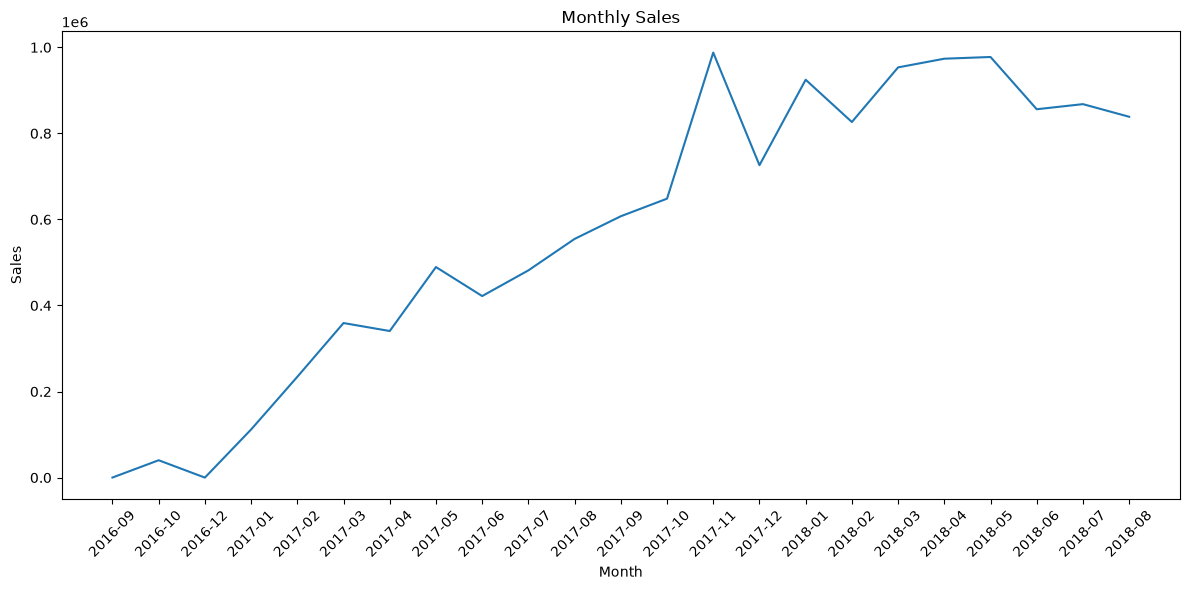

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["month"].astype(str),
    monthly_sales["sales"]
)

plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
monthly_orders = delivered_orders.groupby(
    "purchase_month"
)["order_id"].nunique().reset_index()

monthly_orders.columns = [
    "month",
    "orders"
]

monthly_orders.head()

,month,orders
0,2016-09,1
1,2016-10,265
2,2016-12,1
3,2017-01,750
4,2017-02,1653


In [ ]:
monthly_orders

,month,orders
0,2016-09,1
1,2016-10,265
2,2016-12,1
3,2017-01,750
4,2017-02,1653
5,2017-03,2546
6,2017-04,2303
7,2017-05,3546
8,2017-06,3135
9,2017-07,3872


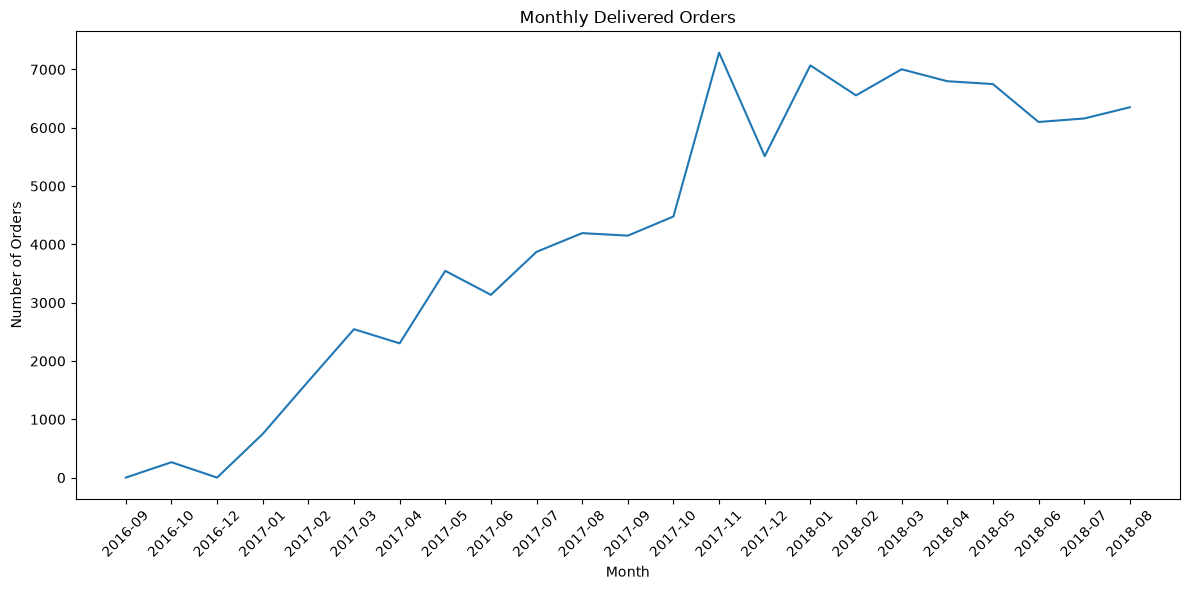

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_orders["month"].astype(str),
    monthly_orders["orders"]
)

plt.title("Monthly Delivered Orders")
plt.xlabel("Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
monthly_analysis = monthly_sales.merge(
    monthly_orders,
    on="month"
)

In [ ]:
monthly_analysis["average_order_value"] = (
    monthly_analysis["sales"] /
    monthly_analysis["orders"]
)

In [ ]:
monthly_analysis

,month,sales,orders,average_order_value
0,2016-09,134.97,1,134.970000
1,2016-10,40325.11,265,152.170226
2,2016-12,10.90,1,10.900000
3,2017-01,111798.36,750,149.064480
4,2017-02,234223.40,1653,141.695947
5,2017-03,359198.85,2546,141.083602
6,2017-04,340669.68,2303,147.924307
7,2017-05,489338.25,3546,137.997250
8,2017-06,421923.37,3135,134.584807
9,2017-07,481604.52,3872,124.381333


In [ ]:
monthly_analysis["sales_growth_%"] = (
    monthly_analysis["sales"]
    .pct_change()
    * 100
)

In [ ]:
monthly_analysis

,month,sales,orders,average_order_value,sales_growth_%
0,2016-09,134.97,1,134.970000,NaN
1,2016-10,40325.11,265,152.170226,2.977709e+04
2,2016-12,10.90,1,10.900000,-9.997297e+01
3,2017-01,111798.36,750,149.064480,1.025573e+06
4,2017-02,234223.40,1653,141.695947,1.095052e+02
5,2017-03,359198.85,2546,141.083602,5.335737e+01
6,2017-04,340669.68,2303,147.924307,-5.158471e+00
7,2017-05,489338.25,3546,137.997250,4.364009e+01
8,2017-06,421923.37,3135,134.584807,-1.377674e+01
9,2017-07,481604.52,3872,124.381333,1.414502e+01


In [ ]:
monthly_analysis["year"] = monthly_analysis["month"].dt.year

In [ ]:
monthly_analysis

,month,sales,orders,average_order_value,sales_growth_%,year
0,2016-09,134.97,1,134.970000,NaN,2016
1,2016-10,40325.11,265,152.170226,2.977709e+04,2016
2,2016-12,10.90,1,10.900000,-9.997297e+01,2016
3,2017-01,111798.36,750,149.064480,1.025573e+06,2017
4,2017-02,234223.40,1653,141.695947,1.095052e+02,2017
5,2017-03,359198.85,2546,141.083602,5.335737e+01,2017
6,2017-04,340669.68,2303,147.924307,-5.158471e+00,2017
7,2017-05,489338.25,3546,137.997250,4.364009e+01,2017
8,2017-06,421923.37,3135,134.584807,-1.377674e+01,2017
9,2017-07,481604.52,3872,124.381333,1.414502e+01,2017


In [ ]:
yearly_sales = monthly_analysis.groupby(
    "year"
)["sales"].sum().reset_index()

yearly_sales

,year,sales
0,2016,40470.98
1,2017,5962902.01
2,2018,7218125.12


In [ ]:
yearly_orders = monthly_analysis.groupby(
    "year"
)["orders"].sum().reset_index()

yearly_orders

,year,orders
0,2016,267
1,2017,43428
2,2018,52783


In [ ]:
yearly_analysis = yearly_sales.merge(
    yearly_orders,
    on="year"
)

yearly_analysis["average_order_value"] = (
    yearly_analysis["sales"] /
    yearly_analysis["orders"]
)

yearly_analysis

,year,sales,orders,average_order_value
0,2016,40470.98,267,151.576704
1,2017,5962902.01,43428,137.305471
2,2018,7218125.12,52783,136.750945


In [ ]:
yearly_analysis["sales_growth_%"] = (
    yearly_analysis["sales"]
    .pct_change()
    * 100
)

In [ ]:
yearly_analysis

,year,sales,orders,average_order_value,sales_growth_%
0,2016,40470.98,267,151.576704,NaN
1,2017,5962902.01,43428,137.305471,14633.772224
2,2018,7218125.12,52783,136.750945,21.050541


In [ ]:
monthly_analysis.sort_values(
    "sales",
    ascending=False
).head(5)

,month,sales,orders,average_order_value,sales_growth_%,year
13,2017-11,987765.37,7289,135.514525,52.374694,2017
19,2018-05,977544.69,6749,144.842894,0.411963,2018
18,2018-04,973534.09,6798,143.208898,2.116506,2018
17,2018-03,953356.25,7003,136.135406,15.357384,2018
15,2018-01,924645.00,7069,130.802801,27.355748,2018


In [ ]:
monthly_analysis.sort_values(
    "sales",
    ascending=True
).head(5)

,month,sales,orders,average_order_value,sales_growth_%,year
2,2016-12,10.90,1,10.900000,-9.997297e+01,2016
0,2016-09,134.97,1,134.970000,NaN,2016
1,2016-10,40325.11,265,152.170226,2.977709e+04,2016
3,2017-01,111798.36,750,149.064480,1.025573e+06,2017
4,2017-02,234223.40,1653,141.695947,1.095052e+02,2017


In [ ]:
unique_customers = delivered_orders["customer_id"].nunique()

unique_customers

96478

In [ ]:
total_delivered_orders = delivered_orders["order_id"].nunique()

total_delivered_orders

96478

In [ ]:
orders_per_customer = (
    total_delivered_orders / unique_customers
)

orders_per_customer

1.0

In [ ]:
customer_orders = delivered_orders.groupby(
    "customer_id"
)["order_id"].nunique().reset_index()

customer_orders.columns = [
    "customer_id",
    "order_count"
]

In [ ]:
customer_orders.head()

,customer_id,order_count
0,00012a2ce6f8dcda20d059ce98491703,1
1,000161a058600d5901f007fab4c27140,1
2,0001fd6190edaaf884bcaf3d49edf079,1
3,0002414f95344307404f0ace7a26f1d5,1
4,000379cdec625522490c315e70c7a9fb,1


In [ ]:
repeat_customers = (
    customer_orders["order_count"] > 1
).sum()

repeat_customers

np.int64(0)

In [ ]:
repeat_customer_rate = (
    repeat_customers / unique_customers
) * 100

repeat_customer_rate

np.float64(0.0)

In [ ]:
customer_spending = delivered_orders.groupby(
    "customer_id"
)["total_price"].sum().reset_index()

customer_spending.columns = [
    "customer_id",
    "total_spent"
]

In [ ]:
customer_spending.sort_values(
    "total_spent",
    ascending=False
).head(10)

,customer_id,total_spent
8293,1617b1357756262bfa56ab541c47bc16,13440.0
89276,ec5b2ba62e574342386871631fafd3fc,7160.0
75240,c6e2731c5b391845f6800c97401a43a9,6735.0
92311,f48d464a0baaea338cb25f816991ab1f,6729.0
24068,3fd6777bbce08a352fddd04e4a7cc8f6,6499.0
2007,05455dfa7cd02f13d132aa7a6a9729c6,5934.6
84350,df55c14d1476a9a3467f131269c2477f,4799.0
13870,24bbf5fd2f2e1b359ee7de94defc4a15,4690.0
23252,3d979689f636322c62418b6346b1c6d2,4590.0
77364,cc803a2c412833101651d3f90ca7de24,4400.0


In [ ]:
average_customer_spending = (
    customer_spending["total_spent"].mean()
)

average_customer_spending

np.float64(137.04158575011922)

In [ ]:
customer_analysis = customer_orders.merge(
    customer_spending,
    on="customer_id"
)

In [ ]:
customer_analysis["average_order_value"] = (
    customer_analysis["total_spent"] /
    customer_analysis["order_count"]
)

In [ ]:
customer_analysis.head()

,customer_id,order_count,total_spent,average_order_value
0,00012a2ce6f8dcda20d059ce98491703,1,89.80,89.80
1,000161a058600d5901f007fab4c27140,1,54.90,54.90
2,0001fd6190edaaf884bcaf3d49edf079,1,179.99,179.99
3,0002414f95344307404f0ace7a26f1d5,1,149.90,149.90
4,000379cdec625522490c315e70c7a9fb,1,93.00,93.00


In [ ]:
customer_analysis.describe()

,order_count,total_spent,average_order_value
count,96478.0,96478.000000,96478.000000
mean,1.0,137.041586,137.041586
std,0.0,209.045198,209.045198
min,1.0,0.850000,0.850000
25%,1.0,45.900000,45.900000
50%,1.0,86.575000,86.575000
75%,1.0,149.900000,149.900000
max,1.0,13440.000000,13440.000000


In [ ]:
delivered_orders["delivery_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / (60 * 60 * 24)

In [ ]:
delivered_orders["delivery_days"].describe()

count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: delivery_days, dtype: float64

In [ ]:
delivered_orders["estimated_days"] = (
    delivered_orders["order_estimated_delivery_date"]
    - delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / (60 * 60 * 24)

In [ ]:
delivered_orders["estimated_days"].describe()

count    96478.000000
mean        23.736347
std          8.760765
min          2.008009
25%         18.330081
50%         23.230880
75%         28.407590
max        155.135463
Name: estimated_days, dtype: float64

In [ ]:
delivered_orders["delivery_delay_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_estimated_delivery_date"]
).dt.total_seconds() / (60 * 60 * 24)

In [ ]:
on_time_orders = (
    delivered_orders["delivery_delay_days"] <= 0
).sum()

total_delivered = len(delivered_orders)

on_time_rate = (
    on_time_orders / total_delivered
) * 100

on_time_rate

np.float64(91.88001409647796)

In [ ]:
late_rate = 100 - on_time_rate

late_rate

np.float64(8.119985903522036)

In [ ]:
average_delivery_delay = (
    delivered_orders["delivery_delay_days"].mean()
)

average_delivery_delay

np.float64(-11.17812572885353)

In [ ]:
average_delivery_time = (
    delivered_orders["delivery_days"].mean()
)

average_delivery_time

np.float64(12.558217098051976)

In [ ]:
delivered_orders[
    [
        "order_id",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "delivery_delay_days"
    ]
].sort_values(
    "delivery_delay_days",
    ascending=False
).head(10)

,order_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days
10503,1b3190b2dfa9d789e1f14c05b647a14a,2018-02-23 14:57:35,2018-09-19 23:24:07,2018-03-15,188.975081
77846,ca07593549f1816d26a572e06dc1eab6,2017-02-21 23:31:27,2017-09-19 14:36:39,2017-03-22,181.608785
27637,47b40429ed8cce3aee9199792275433f,2018-01-03 09:44:01,2018-07-13 20:51:31,2018-01-19,175.869109
18360,2fe324febf907e3ea3f2aa9650869fa5,2017-03-13 20:17:10,2017-09-19 17:00:07,2017-04-05,167.708414
15451,285ab9426d6982034523a855f55a885e,2017-03-08 22:47:40,2017-09-19 14:00:04,2017-04-06,166.583380
26170,440d0d17af552815d15a9e41abe49359,2017-03-07 23:59:51,2017-09-19 15:12:50,2017-04-07,165.633912
74942,c27815f7e3dd0b926b58552628481575,2017-03-15 23:23:17,2017-09-19 17:14:25,2017-04-10,162.718345
81141,d24e8541128cea179a11a65176e0a96f,2017-06-12 13:14:11,2017-12-04 18:36:29,2017-06-26,161.775336
5933,0f4519c5f1c541ddec9f21b3bddd533a,2017-03-09 13:26:57,2017-09-19 14:38:21,2017-04-11,161.609965
17372,2d7561026d542c8dbd8f0daeadf67a43,2017-03-15 11:24:27,2017-09-19 14:38:18,2017-04-13,159.609931


In [ ]:
delivery_kpis = {
    "Average Delivery Time (days)": average_delivery_time,
    "Average Delivery Delay (days)": average_delivery_delay,
    "On-Time Delivery Rate (%)": on_time_rate,
    "Late Delivery Rate (%)": late_rate
}

delivery_kpis

{'Average Delivery Time (days)': np.float64(12.558217098051976),
 'Average Delivery Delay (days)': np.float64(-11.17812572885353),
 'On-Time Delivery Rate (%)': np.float64(91.88001409647796),
 'Late Delivery Rate (%)': np.float64(8.119985903522036)}

In [ ]:
delivered_orders[
    delivered_orders["delivery_delay_days"] > 100
][
    [
        "order_id",
        "order_status",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "delivery_days",
        "estimated_days",
        "delivery_delay_days"
    ]
].sort_values(
    "delivery_delay_days",
    ascending=False
).head(20)

,order_id,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,estimated_days,delivery_delay_days
10503,1b3190b2dfa9d789e1f14c05b647a14a,delivered,2018-02-23 14:57:35,2018-09-19 23:24:07,2018-03-15,208.351759,19.376678,188.975081
77846,ca07593549f1816d26a572e06dc1eab6,delivered,2017-02-21 23:31:27,2017-09-19 14:36:39,2017-03-22,209.628611,28.019826,181.608785
27637,47b40429ed8cce3aee9199792275433f,delivered,2018-01-03 09:44:01,2018-07-13 20:51:31,2018-01-19,191.463542,15.594433,175.869109
18360,2fe324febf907e3ea3f2aa9650869fa5,delivered,2017-03-13 20:17:10,2017-09-19 17:00:07,2017-04-05,189.863160,22.154745,167.708414
15451,285ab9426d6982034523a855f55a885e,delivered,2017-03-08 22:47:40,2017-09-19 14:00:04,2017-04-06,194.633611,28.050231,166.583380
26170,440d0d17af552815d15a9e41abe49359,delivered,2017-03-07 23:59:51,2017-09-19 15:12:50,2017-04-07,195.634016,30.000104,165.633912
74942,c27815f7e3dd0b926b58552628481575,delivered,2017-03-15 23:23:17,2017-09-19 17:14:25,2017-04-10,187.743843,25.025498,162.718345
81141,d24e8541128cea179a11a65176e0a96f,delivered,2017-06-12 13:14:11,2017-12-04 18:36:29,2017-06-26,175.223819,13.448484,161.775336
5933,0f4519c5f1c541ddec9f21b3bddd533a,delivered,2017-03-09 13:26:57,2017-09-19 14:38:21,2017-04-11,194.049583,32.439618,161.609965
17372,2d7561026d542c8dbd8f0daeadf67a43,delivered,2017-03-15 11:24:27,2017-09-19 14:38:18,2017-04-13,188.134618,28.524687,159.609931


In [ ]:
(delivered_orders["delivery_delay_days"] > 30).sum()

np.int64(360)

In [ ]:
(delivered_orders["delivery_delay_days"] > 100).sum()

np.int64(40)

In [ ]:
delivery_kpis

{'Average Delivery Time (days)': np.float64(12.558217098051976),
 'Average Delivery Delay (days)': np.float64(-11.17812572885353),
 'On-Time Delivery Rate (%)': np.float64(91.88001409647796),
 'Late Delivery Rate (%)': np.float64(8.119985903522036)}

In [ ]:
delivered_orders["delivery_delay_days"].describe()

count    96470.000000
mean       -11.178126
std         10.184354
min       -146.016123
25%        -16.244065
50%        -11.948102
75%         -6.389815
max        188.975081
Name: delivery_delay_days, dtype: float64

In [ ]:
delivered_orders["purchase_month"] = (
    delivered_orders["order_purchase_timestamp"]
    .dt.to_period("M")
)

In [ ]:
monthly_delivery = (
    delivered_orders
    .groupby("purchase_month")
    .agg(
        orders=("order_id", "count"),
        average_delivery_days=("delivery_days", "mean"),
        average_delay_days=("delivery_delay_days", "mean"),
        on_time_rate=("delivery_delay_days", lambda x: (x <= 0).mean() * 100)
    )
    .reset_index()
)

In [ ]:
monthly_delivery.head(10)

,purchase_month,orders,average_delivery_days,average_delay_days,on_time_rate
0,2016-09,1,54.813194,36.324745,0.000000
1,2016-10,265,19.600559,-36.076073,98.867925
2,2016-12,1,4.693021,-21.336991,100.000000
3,2017-01,750,12.647044,-26.861788,96.933333
4,2017-02,1653,13.168825,-18.680104,96.793708
5,2017-03,2546,12.951184,-11.781202,94.422624
6,2017-04,2303,14.917913,-12.431898,92.140686
7,2017-05,3546,11.322363,-12.962421,96.362098
8,2017-06,3135,12.011573,-12.010292,96.140351
9,2017-07,3872,11.592732,-11.724584,96.565083


In [ ]:
monthly_delivery.tail(10)

,purchase_month,orders,average_delivery_days,average_delay_days,on_time_rate
13,2017-11,7289,15.161132,-7.399620,85.677048
14,2017-12,5513,15.394919,-12.286421,91.619808
15,2018-01,7069,14.080563,-12.221993,93.436130
16,2018-02,6555,16.945138,-7.583858,84.012204
17,2018-03,7003,16.301410,-5.731657,78.637727
18,2018-04,6798,11.499241,-12.180305,94.689615
19,2018-05,6749,11.419029,-11.472459,91.761742
20,2018-06,6099,9.239216,-18.533524,98.589933
21,2018-07,6159,8.958636,-10.731490,95.470044
22,2018-08,6351,7.732780,-7.453550,89.607936


In [ ]:
monthly_delivery.sort_values(
    "on_time_rate",
    ascending=False
).head(10)

,purchase_month,orders,average_delivery_days,average_delay_days,on_time_rate
2,2016-12,1,4.693021,-21.336991,100.000000
1,2016-10,265,19.600559,-36.076073,98.867925
20,2018-06,6099,9.239216,-18.533524,98.589933
3,2017-01,750,12.647044,-26.861788,96.933333
4,2017-02,1653,13.168825,-18.680104,96.793708
10,2017-08,4193,11.147125,-12.333478,96.684951
9,2017-07,3872,11.592732,-11.724584,96.565083
7,2017-05,3546,11.322363,-12.962421,96.362098
8,2017-06,3135,12.011573,-12.010292,96.140351
21,2018-07,6159,8.958636,-10.731490,95.470044


In [ ]:
monthly_delivery.sort_values(
    "on_time_rate",
    ascending=True
).head(10)

,purchase_month,orders,average_delivery_days,average_delay_days,on_time_rate
0,2016-09,1,54.813194,36.324745,0.000000
17,2018-03,7003,16.301410,-5.731657,78.637727
16,2018-02,6555,16.945138,-7.583858,84.012204
13,2017-11,7289,15.161132,-7.399620,85.677048
22,2018-08,6351,7.732780,-7.453550,89.607936
14,2017-12,5513,15.394919,-12.286421,91.619808
19,2018-05,6749,11.419029,-11.472459,91.761742
6,2017-04,2303,14.917913,-12.431898,92.140686
15,2018-01,7069,14.080563,-12.221993,93.436130
5,2017-03,2546,12.951184,-11.781202,94.422624


In [ ]:
monthly_delivery.sort_values(
    "average_delivery_days",
    ascending=False
).head(10)

,purchase_month,orders,average_delivery_days,average_delay_days,on_time_rate
0,2016-09,1,54.813194,36.324745,0.000000
1,2016-10,265,19.600559,-36.076073,98.867925
16,2018-02,6555,16.945138,-7.583858,84.012204
17,2018-03,7003,16.301410,-5.731657,78.637727
14,2017-12,5513,15.394919,-12.286421,91.619808
13,2017-11,7289,15.161132,-7.399620,85.677048
6,2017-04,2303,14.917913,-12.431898,92.140686
15,2018-01,7069,14.080563,-12.221993,93.436130
4,2017-02,1653,13.168825,-18.680104,96.793708
5,2017-03,2546,12.951184,-11.781202,94.422624


In [ ]:
monthly_delivery.sort_values(
    "average_delay_days",
    ascending=False
).head(10)

,purchase_month,orders,average_delivery_days,average_delay_days,on_time_rate
0,2016-09,1,54.813194,36.324745,0.000000
17,2018-03,7003,16.301410,-5.731657,78.637727
13,2017-11,7289,15.161132,-7.399620,85.677048
22,2018-08,6351,7.732780,-7.453550,89.607936
16,2018-02,6555,16.945138,-7.583858,84.012204
11,2017-09,4150,11.851007,-10.586360,94.795181
21,2018-07,6159,8.958636,-10.731490,95.470044
12,2017-10,4478,11.856700,-11.162836,94.707459
19,2018-05,6749,11.419029,-11.472459,91.761742
9,2017-07,3872,11.592732,-11.724584,96.565083


In [ ]:
median_delivery_delay = (
    delivered_orders["delivery_delay_days"].median()
)

median_delivery_delay

np.float64(-11.948101851851852)

In [ ]:
median_delivery_time = (
    delivered_orders["delivery_days"].median()
)

median_delivery_time

np.float64(10.217476851851853)

In [ ]:
products.head()

NameError: name 'products' is not defined

In [ ]:
products = pd.read_csv("data/olist_products_dataset.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'data/olist_products_dataset.csv'

In [ ]:
import os

print(os.getcwd())

c:\ecommerce-analytics-platform\notebooks


In [ ]:
os.listdir()

['01_data_exploration.ipynb']

In [ ]:
products = pd.read_csv("../data/raw/olist_products_dataset.csv")

NameError: name 'pd' is not defined

In [ ]:
import pandas as pd

In [ ]:
products = pd.read_csv("../data/raw/olist_products_dataset.csv")

In [ ]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [ ]:
products.shape

(32951, 9)

In [ ]:
products.columns

Index(['product_id', 'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm'],
      dtype='str')

In [ ]:
products.isnull().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [ ]:
products["product_category_name"].value_counts(dropna=False).head(15)

product_category_name
cama_mesa_banho                3029
esporte_lazer                  2867
moveis_decoracao               2657
beleza_saude                   2444
utilidades_domesticas          2335
automotivo                     1900
informatica_acessorios         1639
brinquedos                     1411
relogios_presentes             1329
telefonia                      1134
bebes                           919
perfumaria                      868
papelaria                       849
fashion_bolsas_e_acessorios     849
cool_stuff                      789
Name: count, dtype: int64

In [ ]:
products[
    products["product_weight_g"].isna()
    | products["product_length_cm"].isna()
    | products["product_height_cm"].isna()
    | products["product_width_cm"].isna()
]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
products["product_id"].duplicated().sum()

np.int64(0)

In [ ]:
products[
    [
        "product_photos_qty",
        "product_weight_g",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm"
    ]
].describe()

,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,2.188986,2276.472488,30.815078,16.937661,23.196728
std,1.736766,4282.038731,16.914458,13.637554,12.079047
min,1.000000,0.000000,7.000000,2.000000,6.000000
25%,1.000000,300.000000,18.000000,8.000000,15.000000
50%,1.000000,700.000000,25.000000,13.000000,20.000000
75%,3.000000,1900.000000,38.000000,21.000000,30.000000
max,20.000000,40425.000000,105.000000,105.000000,118.000000


In [ ]:
category_sales = (
    orders_items
    .merge(
        products[["product_id", "product_category_name"]],
        on="product_id",
        how="left"
    )
    .groupby("product_category_name")
    .agg(
        orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count"),
        total_sales=("price", "sum")
    )
    .sort_values("total_sales", ascending=False)
)

category_sales.head(15)

NameError: name 'orders_items' is not defined

In [ ]:
import pandas as pd

In [ ]:
orders_items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")

In [ ]:
orders_items.shape

(112650, 7)

In [ ]:
orders_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [ ]:
category_sales = (
    orders_items
    .merge(
        products[["product_id", "product_category_name"]],
        on="product_id",
        how="left"
    )
    .groupby("product_category_name")
    .agg(
        orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count"),
        total_sales=("price", "sum")
    )
    .sort_values("total_sales", ascending=False)
)

category_sales.head(15)

,orders,items_sold,total_sales
product_category_name,,,
beleza_saude,8836,9670,1258681.34
relogios_presentes,5624,5991,1205005.68
cama_mesa_banho,9417,11115,1036988.68
esporte_lazer,7720,8641,988048.97
informatica_acessorios,6689,7827,911954.32
moveis_decoracao,6449,8334,729762.49
cool_stuff,3632,3796,635290.85
utilidades_domesticas,5884,6964,632248.66
automotivo,3897,4235,592720.11


In [ ]:
category_sales["average_item_price"] = (
    category_sales["total_sales"] /
    category_sales["items_sold"]
)

In [ ]:
category_sales.sort_values(
    "average_item_price",
    ascending=False
).head(15)

,orders,items_sold,total_sales,average_item_price
product_category_name,,,,
pcs,181,203,222963.13,1098.340542
portateis_casa_forno_e_cafe,75,76,47445.71,624.285658
eletrodomesticos_2,234,238,113317.74,476.124958
agro_industria_e_comercio,182,212,72530.47,342.124858
instrumentos_musicais,628,680,191498.88,281.616000
eletroportateis,630,679,190648.58,280.778468
portateis_cozinha_e_preparadores_de_alimentos,14,15,3968.53,264.568667
telefonia_fixa,217,264,59583.00,225.693182
construcao_ferramentas_seguranca,167,194,40544.52,208.992371


In [ ]:
category_sales.sort_values(
    "items_sold",
    ascending=False
).head(15)

,orders,items_sold,total_sales,average_item_price
product_category_name,,,,
cama_mesa_banho,9417,11115,1036988.68,93.296327
beleza_saude,8836,9670,1258681.34,130.163531
esporte_lazer,7720,8641,988048.97,114.344285
moveis_decoracao,6449,8334,729762.49,87.564494
informatica_acessorios,6689,7827,911954.32,116.513903
utilidades_domesticas,5884,6964,632248.66,90.788148
relogios_presentes,5624,5991,1205005.68,201.135984
telefonia,4199,4545,323667.53,71.213978
ferramentas_jardim,3518,4347,485256.46,111.630196


In [ ]:
category_sales["average_item_price"] = (
    category_sales["total_sales"] /
    category_sales["items_sold"]
)

In [ ]:
category_sales.sort_values(
    "average_item_price",
    ascending=False
).head(15)

,orders,items_sold,total_sales,average_item_price
product_category_name,,,,
pcs,181,203,222963.13,1098.340542
portateis_casa_forno_e_cafe,75,76,47445.71,624.285658
eletrodomesticos_2,234,238,113317.74,476.124958
agro_industria_e_comercio,182,212,72530.47,342.124858
instrumentos_musicais,628,680,191498.88,281.616000
eletroportateis,630,679,190648.58,280.778468
portateis_cozinha_e_preparadores_de_alimentos,14,15,3968.53,264.568667
telefonia_fixa,217,264,59583.00,225.693182
construcao_ferramentas_seguranca,167,194,40544.52,208.992371


In [ ]:
category_sales.sort_values(
    "items_sold",
    ascending=False
).head(15)

,orders,items_sold,total_sales,average_item_price
product_category_name,,,,
cama_mesa_banho,9417,11115,1036988.68,93.296327
beleza_saude,8836,9670,1258681.34,130.163531
esporte_lazer,7720,8641,988048.97,114.344285
moveis_decoracao,6449,8334,729762.49,87.564494
informatica_acessorios,6689,7827,911954.32,116.513903
utilidades_domesticas,5884,6964,632248.66,90.788148
relogios_presentes,5624,5991,1205005.68,201.135984
telefonia,4199,4545,323667.53,71.213978
ferramentas_jardim,3518,4347,485256.46,111.630196


In [ ]:
category_sales.sort_values(
    "total_sales",
    ascending=False
).head(15)

,orders,items_sold,total_sales,average_item_price
product_category_name,,,,
beleza_saude,8836,9670,1258681.34,130.163531
relogios_presentes,5624,5991,1205005.68,201.135984
cama_mesa_banho,9417,11115,1036988.68,93.296327
esporte_lazer,7720,8641,988048.97,114.344285
informatica_acessorios,6689,7827,911954.32,116.513903
moveis_decoracao,6449,8334,729762.49,87.564494
cool_stuff,3632,3796,635290.85,167.357969
utilidades_domesticas,5884,6964,632248.66,90.788148
automotivo,3897,4235,592720.11,139.957523


In [ ]:
category_sales["revenue_share_%"] = (
    category_sales["total_sales"]
    / category_sales["total_sales"].sum()
    * 100
)

In [ ]:
category_sales.sort_values(
    "revenue_share_%",
    ascending=False
).head(15)

,orders,items_sold,total_sales,average_item_price,revenue_share_%
product_category_name,,,,,
beleza_saude,8836,9670,1258681.34,130.163531,9.384664
relogios_presentes,5624,5991,1205005.68,201.135984,8.984461
cama_mesa_banho,9417,11115,1036988.68,93.296327,7.731735
esporte_lazer,7720,8641,988048.97,114.344285,7.366843
informatica_acessorios,6689,7827,911954.32,116.513903,6.799485
moveis_decoracao,6449,8334,729762.49,87.564494,5.441072
cool_stuff,3632,3796,635290.85,167.357969,4.736696
utilidades_domesticas,5884,6964,632248.66,90.788148,4.714014
automotivo,3897,4235,592720.11,139.957523,4.419291


In [ ]:
product_sales = (
    orders_items
    .groupby("product_id")
    .agg(
        orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count"),
        total_sales=("price", "sum")
    )
    .sort_values("total_sales", ascending=False)
)

product_sales.head(15)

,orders,items_sold,total_sales
product_id,,,
bb50f2e236e5eea0100680137654686c,187,195,63885.00
6cdd53843498f92890544667809f1595,151,156,54730.20
d6160fb7873f184099d9bc95e30376af,35,35,48899.34
d1c427060a0f73f6b889a5c7c61f2ac4,323,343,47214.51
99a4788cb24856965c36a24e339b6058,467,488,43025.56
3dd2a17168ec895c781a9191c1e95ad7,255,274,41082.60
25c38557cf793876c5abdd5931f922db,38,38,38907.32
5f504b3a1c75b73d6151be81eb05bdc9,63,63,37733.90
53b36df67ebb7c41585e8d54d6772e08,306,323,37683.42


In [ ]:
product_sales["average_item_price"] = (
    product_sales["total_sales"] /
    product_sales["items_sold"]
)

product_sales.head(15)

,orders,items_sold,total_sales,average_item_price
product_id,,,,
bb50f2e236e5eea0100680137654686c,187,195,63885.00,327.615385
6cdd53843498f92890544667809f1595,151,156,54730.20,350.834615
d6160fb7873f184099d9bc95e30376af,35,35,48899.34,1397.124000
d1c427060a0f73f6b889a5c7c61f2ac4,323,343,47214.51,137.651633
99a4788cb24856965c36a24e339b6058,467,488,43025.56,88.167131
3dd2a17168ec895c781a9191c1e95ad7,255,274,41082.60,149.936496
25c38557cf793876c5abdd5931f922db,38,38,38907.32,1023.876842
5f504b3a1c75b73d6151be81eb05bdc9,63,63,37733.90,598.950794
53b36df67ebb7c41585e8d54d6772e08,306,323,37683.42,116.666935


In [ ]:
product_sales.sort_values(
    "items_sold",
    ascending=False
).head(15)

,orders,items_sold,total_sales,average_item_price
product_id,,,,
aca2eb7d00ea1a7b8ebd4e68314663af,431,527,37608.90,71.364137
99a4788cb24856965c36a24e339b6058,467,488,43025.56,88.167131
422879e10f46682990de24d770e7f83d,352,484,26577.22,54.911612
389d119b48cf3043d311335e499d9c6b,311,392,21440.59,54.695383
368c6c730842d78016ad823897a372db,291,388,21056.80,54.270103
53759a2ecddad2bb87a079a1f1519f73,287,373,20387.20,54.657373
d1c427060a0f73f6b889a5c7c61f2ac4,323,343,47214.51,137.651633
53b36df67ebb7c41585e8d54d6772e08,306,323,37683.42,116.666935
154e7e31ebfa092203795c972e5804a6,269,281,6325.19,22.509573


In [ ]:
product_sales = (
    orders_items
    .merge(
        products[["product_id", "product_category_name"]],
        on="product_id",
        how="left"
    )
    .groupby(["product_id", "product_category_name"])
    .agg(
        orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count"),
        total_sales=("price", "sum")
    )
)

product_sales["average_item_price"] = (
    product_sales["total_sales"] /
    product_sales["items_sold"]
)

product_sales = product_sales.sort_values(
    "total_sales",
    ascending=False
)

product_sales.head(15)

,,orders,items_sold,total_sales,average_item_price
product_id,product_category_name,,,,
bb50f2e236e5eea0100680137654686c,beleza_saude,187,195,63885.00,327.615385
6cdd53843498f92890544667809f1595,beleza_saude,151,156,54730.20,350.834615
d6160fb7873f184099d9bc95e30376af,pcs,35,35,48899.34,1397.124000
d1c427060a0f73f6b889a5c7c61f2ac4,informatica_acessorios,323,343,47214.51,137.651633
99a4788cb24856965c36a24e339b6058,cama_mesa_banho,467,488,43025.56,88.167131
3dd2a17168ec895c781a9191c1e95ad7,informatica_acessorios,255,274,41082.60,149.936496
25c38557cf793876c5abdd5931f922db,bebes,38,38,38907.32,1023.876842
5f504b3a1c75b73d6151be81eb05bdc9,cool_stuff,63,63,37733.90,598.950794
53b36df67ebb7c41585e8d54d6772e08,relogios_presentes,306,323,37683.42,116.666935


In [ ]:
total_product_sales = product_sales["total_sales"].sum()

product_sales["revenue_share_%"] = (
    product_sales["total_sales"] / total_product_sales
) * 100

product_sales.head(15)

,,orders,items_sold,total_sales,average_item_price,revenue_share_%
product_id,product_category_name,,,,,
bb50f2e236e5eea0100680137654686c,beleza_saude,187,195,63885.00,327.615385,0.476323
6cdd53843498f92890544667809f1595,beleza_saude,151,156,54730.20,350.834615,0.408066
d6160fb7873f184099d9bc95e30376af,pcs,35,35,48899.34,1397.124000,0.364591
d1c427060a0f73f6b889a5c7c61f2ac4,informatica_acessorios,323,343,47214.51,137.651633,0.352029
99a4788cb24856965c36a24e339b6058,cama_mesa_banho,467,488,43025.56,88.167131,0.320796
3dd2a17168ec895c781a9191c1e95ad7,informatica_acessorios,255,274,41082.60,149.936496,0.306310
25c38557cf793876c5abdd5931f922db,bebes,38,38,38907.32,1023.876842,0.290091
5f504b3a1c75b73d6151be81eb05bdc9,cool_stuff,63,63,37733.90,598.950794,0.281342
53b36df67ebb7c41585e8d54d6772e08,relogios_presentes,306,323,37683.42,116.666935,0.280966


In [ ]:
product_sales["revenue_share_%"].head(15).sum()

np.float64(4.50093826485784)

In [ ]:
top_products_by_orders = product_sales.sort_values(
    "orders",
    ascending=False
).head(15)

top_products_by_orders

,,orders,items_sold,total_sales,average_item_price,revenue_share_%
product_id,product_category_name,,,,,
99a4788cb24856965c36a24e339b6058,cama_mesa_banho,467,488,43025.56,88.167131,0.320796
aca2eb7d00ea1a7b8ebd4e68314663af,moveis_decoracao,431,527,37608.90,71.364137,0.280410
422879e10f46682990de24d770e7f83d,ferramentas_jardim,352,484,26577.22,54.911612,0.198158
d1c427060a0f73f6b889a5c7c61f2ac4,informatica_acessorios,323,343,47214.51,137.651633,0.352029
389d119b48cf3043d311335e499d9c6b,ferramentas_jardim,311,392,21440.59,54.695383,0.159860
53b36df67ebb7c41585e8d54d6772e08,relogios_presentes,306,323,37683.42,116.666935,0.280966
368c6c730842d78016ad823897a372db,ferramentas_jardim,291,388,21056.80,54.270103,0.156998
53759a2ecddad2bb87a079a1f1519f73,ferramentas_jardim,287,373,20387.20,54.657373,0.152006
154e7e31ebfa092203795c972e5804a6,beleza_saude,269,281,6325.19,22.509573,0.047160


In [ ]:
top_products_by_price = product_sales.sort_values(
    "average_item_price",
    ascending=False
).head(15)

top_products_by_price

,,orders,items_sold,total_sales,average_item_price,revenue_share_%
product_id,product_category_name,,,,,
489ae2aa008f021502940f251d4cce7f,utilidades_domesticas,1,1,6735.00,6735.00,0.050216
69c590f7ffc7bf8db97190b6cb6ed62e,pcs,1,1,6729.00,6729.00,0.050171
1bdf5e6731585cf01aa8169c7028d6ad,artes,1,1,6499.00,6499.00,0.048456
a6492cc69376c469ab6f61d8f44de961,eletroportateis,1,1,4799.00,4799.00,0.035781
c3ed642d592594bb648ff4a04cee2747,eletroportateis,1,1,4690.00,4690.00,0.034968
259037a6a41845e455183f89c5035f18,pcs,1,1,4590.00,4590.00,0.034223
a1beef8f3992dbd4cd8726796aa69c53,instrumentos_musicais,1,1,4399.87,4399.87,0.032805
6cdf8fc1d741c76586d8b6b15e9eef30,consoles_games,1,1,4099.99,4099.99,0.030569
6902c1962dd19d540807d0ab8fade5c6,relogios_presentes,1,1,3999.90,3999.90,0.029823


In [ ]:
uncategorized_sales = (
    orders_items
    .merge(
        products[["product_id", "product_category_name"]],
        on="product_id",
        how="left"
    )
)

uncategorized_sales = uncategorized_sales[
    uncategorized_sales["product_category_name"].isna()
]

uncategorized_sales["price"].sum()

np.float64(179535.28)

In [ ]:
uncategorized_sales["product_id"].nunique()

610

In [ ]:
top_products_by_volume = product_sales.sort_values(
    "items_sold",
    ascending=False
).head(15)

top_products_by_volume

,,orders,items_sold,total_sales,average_item_price,revenue_share_%
product_id,product_category_name,,,,,
aca2eb7d00ea1a7b8ebd4e68314663af,moveis_decoracao,431,527,37608.90,71.364137,0.280410
99a4788cb24856965c36a24e339b6058,cama_mesa_banho,467,488,43025.56,88.167131,0.320796
422879e10f46682990de24d770e7f83d,ferramentas_jardim,352,484,26577.22,54.911612,0.198158
389d119b48cf3043d311335e499d9c6b,ferramentas_jardim,311,392,21440.59,54.695383,0.159860
368c6c730842d78016ad823897a372db,ferramentas_jardim,291,388,21056.80,54.270103,0.156998
53759a2ecddad2bb87a079a1f1519f73,ferramentas_jardim,287,373,20387.20,54.657373,0.152006
d1c427060a0f73f6b889a5c7c61f2ac4,informatica_acessorios,323,343,47214.51,137.651633,0.352029
53b36df67ebb7c41585e8d54d6772e08,relogios_presentes,306,323,37683.42,116.666935,0.280966
154e7e31ebfa092203795c972e5804a6,beleza_saude,269,281,6325.19,22.509573,0.047160


In [ ]:
product_sales["revenue_per_order"] = (
    product_sales["total_sales"] /
    product_sales["orders"]
)

product_sales.sort_values(
    "revenue_per_order",
    ascending=False
).head(15)

,,orders,items_sold,total_sales,average_item_price,revenue_share_%,revenue_per_order
product_id,product_category_name,,,,,,
5769ef0a239114ac3a854af00df129e4,telefonia_fixa,1,8,13440.00,1680.000000,0.100208,13440.00
489ae2aa008f021502940f251d4cce7f,utilidades_domesticas,1,1,6735.00,6735.000000,0.050216,6735.00
69c590f7ffc7bf8db97190b6cb6ed62e,pcs,1,1,6729.00,6729.000000,0.050171,6729.00
1bdf5e6731585cf01aa8169c7028d6ad,artes,1,1,6499.00,6499.000000,0.048456,6499.00
c183fd5d2abf05873fa6e1014ed9e06c,agro_industria_e_comercio,1,6,5934.60,989.100000,0.044248,5934.60
19936fa4f614ee0590d3b77ac83fd648,telefonia_fixa,2,6,10460.00,1743.333333,0.077989,5230.00
a6492cc69376c469ab6f61d8f44de961,eletroportateis,1,1,4799.00,4799.000000,0.035781,4799.00
c3ed642d592594bb648ff4a04cee2747,eletroportateis,1,1,4690.00,4690.000000,0.034968,4690.00
259037a6a41845e455183f89c5035f18,pcs,1,1,4590.00,4590.000000,0.034223,4590.00


In [ ]:
category_sales["sales_per_order"] = (
    category_sales["total_sales"] /
    category_sales["orders"]
)

category_sales.sort_values(
    "sales_per_order",
    ascending=False
).head(15)

,orders,items_sold,total_sales,average_item_price,revenue_share_%,sales_per_order
product_category_name,,,,,,
pcs,181,203,222963.13,1098.340542,1.662402,1231.840497
portateis_casa_forno_e_cafe,75,76,47445.71,624.285658,0.353753,632.609467
eletrodomesticos_2,234,238,113317.74,476.124958,0.844891,484.263846
agro_industria_e_comercio,182,212,72530.47,342.124858,0.540784,398.519066
instrumentos_musicais,628,680,191498.88,281.616000,1.427806,304.934522
eletroportateis,630,679,190648.58,280.778468,1.421466,302.616794
portateis_cozinha_e_preparadores_de_alimentos,14,15,3968.53,264.568667,0.029589,283.466429
telefonia_fixa,217,264,59583.00,225.693182,0.444248,274.576037
construcao_ferramentas_seguranca,167,194,40544.52,208.992371,0.302298,242.781557


In [ ]:
category_sales_final = category_sales[
    [
        "orders",
        "items_sold",
        "total_sales",
        "average_item_price",
        "revenue_share_%",
        "sales_per_order"
    ]
].sort_values(
    "total_sales",
    ascending=False
)

category_sales_final.head(15)

,orders,items_sold,total_sales,average_item_price,revenue_share_%,sales_per_order
product_category_name,,,,,,
beleza_saude,8836,9670,1258681.34,130.163531,9.384664,142.449224
relogios_presentes,5624,5991,1205005.68,201.135984,8.984461,214.261323
cama_mesa_banho,9417,11115,1036988.68,93.296327,7.731735,110.118794
esporte_lazer,7720,8641,988048.97,114.344285,7.366843,127.985618
informatica_acessorios,6689,7827,911954.32,116.513903,6.799485,136.336421
moveis_decoracao,6449,8334,729762.49,87.564494,5.441072,113.159015
cool_stuff,3632,3796,635290.85,167.357969,4.736696,174.914882
utilidades_domesticas,5884,6964,632248.66,90.788148,4.714014,107.452186
automotivo,3897,4235,592720.11,139.957523,4.419291,152.096513


In [ ]:
missing_category_sales = (
    orders_items
    .merge(
        products[["product_id", "product_category_name"]],
        on="product_id",
        how="left"
    )
)

missing_category_sales = missing_category_sales[
    missing_category_sales["product_category_name"].isna()
]

missing_category_sales.shape

(1603, 8)

In [ ]:
missing_category_sales["price"].sum()

np.float64(179535.28)

In [ ]:
missing_revenue = missing_category_sales["price"].sum()
total_revenue = orders_items["price"].sum()

missing_revenue_share = (
    missing_revenue / total_revenue
) * 100

missing_revenue_share

np.float64(1.3209239733086882)

In [ ]:
missing_category_sales["product_id"].nunique()

610

In [ ]:
missing_products = products[
    products["product_category_name"].isna()
]

missing_products.shape

(610, 9)

In [ ]:
missing_products[
    [
        "product_id",
        "product_name_lenght",
        "product_description_lenght",
        "product_photos_qty",
        "product_weight_g",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm"
    ]
].head(20)

,product_id,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,300.0,35.0,7.0,12.0
244,e10758160da97891c2fdcbc35f0f031d,NaN,NaN,NaN,2200.0,16.0,2.0,11.0
294,39e3b9b12cd0bf8ee681bbc1c130feb5,NaN,NaN,NaN,300.0,16.0,7.0,11.0
299,794de06c32a626a5692ff50e4985d36f,NaN,NaN,NaN,300.0,18.0,8.0,14.0
347,7af3e2da474486a3519b0cba9dea8ad9,NaN,NaN,NaN,200.0,22.0,14.0,14.0
428,629beb8e7317703dcc5f35b5463fd20e,NaN,NaN,NaN,1400.0,25.0,25.0,25.0


In [ ]:
customers = pd.read_csv(
    "../data/raw/olist_customers_dataset.csv"
)

customers.shape

(99441, 5)

In [ ]:
customers.columns

Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='str')

In [ ]:
customers.isnull().sum()


customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [ ]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [ ]:
customers["customer_id"].duplicated().sum()

np.int64(0)

In [ ]:
customers["customer_unique_id"].nunique()

96096

In [ ]:
orders.columns

NameError: name 'orders' is not defined

In [ ]:
orders = pd.read_csv(
    "../data/raw/olist_orders_dataset.csv"
)µ

SyntaxError: invalid syntax (2519841639.py, line 3)

In [ ]:
orders = pd.read_csv(
    "../data/raw/olist_orders_dataset.csv"
)

In [ ]:
orders.shape

(99441, 8)

In [ ]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='str')

In [ ]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [ ]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [ ]:
orders["order_id"].duplicated().sum()

np.int64(0)

In [ ]:
orders["order_status"].value_counts(dropna=False)

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [ ]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

orders["order_purchase_timestamp"].min(), orders["order_purchase_timestamp"].max()

(Timestamp('2016-09-04 21:15:19'), Timestamp('2018-10-17 17:30:18'))

In [ ]:
orders["customer_id"].nunique()

99441

In [ ]:
customers["customer_id"].nunique()

99441

In [ ]:
orders[~orders["customer_id"].isin(customers["customer_id"])].shape

(0, 8)

In [ ]:
customer_orders = (
    orders
    .merge(
        customers[["customer_id", "customer_unique_id"]],
        on="customer_id",
        how="left"
    )
    .groupby("customer_unique_id")
    .agg(
        orders=("order_id", "nunique")
    )
)

customer_orders.head()

,orders
customer_unique_id,
0000366f3b9a7992bf8c76cfdf3221e2,1
0000b849f77a49e4a4ce2b2a4ca5be3f,1
0000f46a3911fa3c0805444483337064,1
0000f6ccb0745a6a4b88665a16c9f078,1
0004aac84e0df4da2b147fca70cf8255,1


In [ ]:
customer_orders["orders"].value_counts().sort_index().head(15)

orders
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64

In [ ]:
total_customers = customer_orders.shape[0]

repeat_customers = (
    customer_orders["orders"] > 1
).sum()

repeat_customer_rate = (
    repeat_customers / total_customers
) * 100

total_customers, repeat_customers, repeat_customer_rate

(96096, np.int64(2997), np.float64(3.1187562437562435))

In [ ]:
customer_state = (
    customers
    .groupby("customer_state")
    .agg(
        customers=("customer_unique_id", "nunique")
    )
    .sort_values("customers", ascending=False)
)

customer_state.head(15)

,customers
customer_state,
SP,40302
RJ,12384
MG,11259
RS,5277
PR,4882
SC,3534
BA,3277
DF,2075
ES,1964


In [ ]:
customer_state["customer_share_%"] = (
    customer_state["customers"] /
    customer_state["customers"].sum()
) * 100

customer_state.head(15)

,customers,customer_share_%
customer_state,,
SP,40302,41.921861
RJ,12384,12.881751
MG,11259,11.711534
RS,5277,5.489099
PR,4882,5.078223
SC,3534,3.676042
BA,3277,3.408713
DF,2075,2.158401
ES,1964,2.042939


In [ ]:
customer_city = (
    customers
    .groupby("customer_city")
    .agg(
        customers=("customer_unique_id", "nunique")
    )
    .sort_values("customers", ascending=False)
)

customer_city.head(15)

,customers
customer_city,
sao paulo,14984
rio de janeiro,6620
belo horizonte,2672
brasilia,2069
curitiba,1465
campinas,1398
porto alegre,1326
salvador,1209
guarulhos,1153


In [ ]:
customer_sales = (
    orders
    .merge(
        customers[
            ["customer_id", "customer_unique_id", "customer_state"]
        ],
        on="customer_id",
        how="left"
    )
    .merge(
        orders_items[
            ["order_id", "price"]
        ],
        on="order_id",
        how="left"
    )
    .groupby("customer_state")
    .agg(
        customers=("customer_unique_id", "nunique"),
        orders=("order_id", "nunique"),
        total_sales=("price", "sum")
    )
    .sort_values("total_sales", ascending=False)
)

customer_sales.head(15)

,customers,orders,total_sales
customer_state,,,
SP,40302,41746,5202955.05
RJ,12384,12852,1824092.67
MG,11259,11635,1585308.03
RS,5277,5466,750304.02
PR,4882,5045,683083.76
SC,3534,3637,520553.34
BA,3277,3380,511349.99
DF,2075,2140,302603.94
GO,1952,2020,294591.95


In [ ]:
customer_sales["revenue_share_%"] = (
    customer_sales["total_sales"] /
    customer_sales["total_sales"].sum()
) * 100

customer_sales.head(15)

,customers,orders,total_sales,revenue_share_%
customer_state,,,,
SP,40302,41746,5202955.05,38.280543
RJ,12384,12852,1824092.67,13.420692
MG,11259,11635,1585308.03,11.663843
RS,5277,5466,750304.02,5.520333
PR,4882,5045,683083.76,5.025763
SC,3534,3637,520553.34,3.829951
BA,3277,3380,511349.99,3.762238
DF,2075,2140,302603.94,2.226397
GO,1952,2020,294591.95,2.167449


In [ ]:
customer_sales_detail = (
    orders
    .merge(
        customers[
            ["customer_id", "customer_unique_id", "customer_state"]
        ],
        on="customer_id",
        how="left"
    )
    .merge(
        orders_items[
            ["order_id", "price"]
        ],
        on="order_id",
        how="left"
    )
    .groupby("customer_unique_id")
    .agg(
        orders=("order_id", "nunique"),
        items_sold=("price", "count"),
        total_spend=("price", "sum")
    )
    .sort_values("total_spend", ascending=False)
)

customer_sales_detail.head(15)

,orders,items_sold,total_spend
customer_unique_id,,,
0a0a92112bd4c708ca5fde585afaa872,1,8,13440.00
da122df9eeddfedc1dc1f5349a1a690c,2,2,7388.00
763c8b1c9c68a0229c42c9fc6f662b93,1,4,7160.00
dc4802a71eae9be1dd28f5d788ceb526,1,1,6735.00
459bef486812aa25204be022145caa62,1,1,6729.00
ff4159b92c40ebe40454e3e6a7c35ed6,1,1,6499.00
4007669dec559734d6f53e029e360987,1,6,5934.60
eebb5dda148d3893cdaf5b5ca3040ccb,1,1,4690.00
5d0a2980b292d049061542014e8960bf,1,2,4599.90


In [ ]:
customer_sales_detail["total_spend"].describe()

count    96096.000000
mean       141.438184
std        217.215904
min          0.000000
25%         45.990000
50%         89.000000
75%        154.000000
max      13440.000000
Name: total_spend, dtype: float64

In [ ]:
customer_sales_detail.head(15)

,orders,items_sold,total_spend
customer_unique_id,,,
0a0a92112bd4c708ca5fde585afaa872,1,8,13440.00
da122df9eeddfedc1dc1f5349a1a690c,2,2,7388.00
763c8b1c9c68a0229c42c9fc6f662b93,1,4,7160.00
dc4802a71eae9be1dd28f5d788ceb526,1,1,6735.00
459bef486812aa25204be022145caa62,1,1,6729.00
ff4159b92c40ebe40454e3e6a7c35ed6,1,1,6499.00
4007669dec559734d6f53e029e360987,1,6,5934.60
eebb5dda148d3893cdaf5b5ca3040ccb,1,1,4690.00
5d0a2980b292d049061542014e8960bf,1,2,4599.90


In [ ]:
customer_sales_detail["average_order_value"] = (
    customer_sales_detail["total_spend"] /
    customer_sales_detail["orders"]
)

In [ ]:
customer_sales_detail.sort_values(
    "average_order_value",
    ascending=False
).head(15)

,orders,items_sold,total_spend,average_order_value
customer_unique_id,,,,
0a0a92112bd4c708ca5fde585afaa872,1,8,13440.00,13440.00
763c8b1c9c68a0229c42c9fc6f662b93,1,4,7160.00,7160.00
dc4802a71eae9be1dd28f5d788ceb526,1,1,6735.00,6735.00
459bef486812aa25204be022145caa62,1,1,6729.00,6729.00
ff4159b92c40ebe40454e3e6a7c35ed6,1,1,6499.00,6499.00
4007669dec559734d6f53e029e360987,1,6,5934.60,5934.60
eebb5dda148d3893cdaf5b5ca3040ccb,1,1,4690.00,4690.00
5d0a2980b292d049061542014e8960bf,1,2,4599.90,4599.90
48e1ac109decbb87765a3eade6854098,1,1,4590.00,4590.00


In [ ]:
customer_sales_detail["customer_type"] = (
    customer_sales_detail["orders"]
    .apply(lambda x: "Repeat" if x > 1 else "One-time")
)

In [ ]:
customer_sales_detail["customer_type"].value_counts()

customer_type
One-time    93099
Repeat       2997
Name: count, dtype: int64

In [ ]:
customer_segment = (
    customer_sales_detail
    .groupby("customer_type")
    .agg(
        customers=("total_spend", "count"),
        total_revenue=("total_spend", "sum"),
        average_spend=("total_spend", "mean"),
        median_spend=("total_spend", "median"),
        total_orders=("orders", "sum")
    )
)

customer_segment

,customers,total_revenue,average_spend,median_spend,total_orders
customer_type,,,,,
One-time,93099,12812821.73,137.625772,85.90,93099
Repeat,2997,778821.97,259.867191,179.89,6342


In [ ]:
customer_segment["revenue_share_%"] = (
    customer_segment["total_revenue"] /
    customer_segment["total_revenue"].sum()
) * 100

customer_segment

,customers,total_revenue,average_spend,median_spend,total_orders,revenue_share_%
customer_type,,,,,,
One-time,93099,12812821.73,137.625772,85.90,93099,94.269847
Repeat,2997,778821.97,259.867191,179.89,6342,5.730153


In [ ]:
customer_sales_detail.sort_values(
    "total_spend",
    ascending=False
).head(20)

,orders,items_sold,total_spend,average_order_value,customer_type
customer_unique_id,,,,,
0a0a92112bd4c708ca5fde585afaa872,1,8,13440.00,13440.00,One-time
da122df9eeddfedc1dc1f5349a1a690c,2,2,7388.00,3694.00,Repeat
763c8b1c9c68a0229c42c9fc6f662b93,1,4,7160.00,7160.00,One-time
dc4802a71eae9be1dd28f5d788ceb526,1,1,6735.00,6735.00,One-time
459bef486812aa25204be022145caa62,1,1,6729.00,6729.00,One-time
ff4159b92c40ebe40454e3e6a7c35ed6,1,1,6499.00,6499.00,One-time
4007669dec559734d6f53e029e360987,1,6,5934.60,5934.60,One-time
eebb5dda148d3893cdaf5b5ca3040ccb,1,1,4690.00,4690.00,One-time
5d0a2980b292d049061542014e8960bf,1,2,4599.90,4599.90,One-time


In [ ]:
order_status = (
    orders
    .groupby("order_status")
    .agg(
        orders=("order_id", "nunique")
    )
    .sort_values("orders", ascending=False)
)

order_status

,orders
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [ ]:
order_status["order_share_%"] = (
    order_status["orders"] /
    order_status["orders"].sum()
) * 100

order_status

,orders,order_share_%
order_status,,
delivered,96478,97.020344
shipped,1107,1.113223
canceled,625,0.628513
unavailable,609,0.612423
invoiced,314,0.315765
processing,301,0.302692
created,5,0.005028
approved,2,0.002011


In [ ]:
orders["purchase_month"] = (
    orders["order_purchase_timestamp"]
    .dt.to_period("M")
)

In [ ]:
monthly_orders = (
    orders
    .groupby("purchase_month")
    .agg(
        orders=("order_id", "nunique")
    )
)

monthly_orders.head()

,orders
purchase_month,
2016-09,4
2016-10,324
2016-12,1
2017-01,800
2017-02,1780


In [ ]:
monthly_orders.tail()

,orders
purchase_month,
2018-06,6167
2018-07,6292
2018-08,6512
2018-09,16
2018-10,4


In [ ]:
order_sales = (
    orders
    .merge(
        orders_items[["order_id", "price"]],
        on="order_id",
        how="left"
    )
    .groupby("order_id")
    .agg(
        total_sales=("price", "sum")
    )
)

In [ ]:
order_sales["total_sales"].describe()

count    99441.000000
mean       136.680481
std        210.172081
min          0.000000
25%         45.000000
50%         85.000000
75%        149.900000
max      13440.000000
Name: total_sales, dtype: float64

In [ ]:
order_sales["total_sales"].sort_values(
    ascending=False
).head(15)

order_id
03caa2c082116e1d31e67e9ae3700499    13440.00
736e1922ae60d0d6a89247b851902527     7160.00
0812eb902a67711a1cb742b3cdaa65ae     6735.00
fefacc66af859508bf1a7934eab1e97f     6729.00
f5136e38d1a14a4dbd87dff67da82701     6499.00
2cc9089445046817a7539d90805e6e5a     5934.60
a96610ab360d42a2e5335a3998b4718a     4799.00
199af31afc78c699f0dbf71fb178d4d4     4690.00
b4c4b76c642808cbe472a32b86cddc95     4599.90
8dbc85d1447242f3b127dda390d56e19     4590.00
d2f270487125ddc41fd134c4003ad1d7     4400.00
426a9742b533fc6fed17d1fd6d143d7e     4399.87
68101694e5c5dc7330c91e1bbc36214f     4099.99
b239ca7cd485940b31882363b52e6674     4059.00
86c4eab1571921a6a6e248ed312f5a5a     3999.90
Name: total_sales, dtype: float64

In [ ]:
aov = (
    order_sales["total_sales"].sum() /
    order_sales.shape[0]
)

aov

np.float64(136.68048088816482)

In [ ]:
median_order_value = order_sales["total_sales"].median()

median_order_value

np.float64(85.0)

In [ ]:
monthly_sales = (
    orders
    .merge(
        orders_items[["order_id", "price"]],
        on="order_id",
        how="left"
    )
    .groupby("purchase_month")
    .agg(
        orders=("order_id", "nunique"),
        total_sales=("price", "sum")
    )
)

In [ ]:
monthly_sales["average_order_value"] = (
    monthly_sales["total_sales"] /
    monthly_sales["orders"]
)

monthly_sales.head(15)

,orders,total_sales,average_order_value
purchase_month,,,
2016-09,4,267.36,66.840000
2016-10,324,49507.66,152.801420
2016-12,1,10.90,10.900000
2017-01,800,120312.87,150.391087
2017-02,1780,247303.02,138.934281
2017-03,2682,374344.30,139.576547
2017-04,2404,359927.23,149.720146
2017-05,3700,506071.14,136.775984
2017-06,3245,433038.60,133.447951


In [ ]:
monthly_sales.tail(15)

,orders,total_sales,average_order_value
purchase_month,,,
2017-08,4331,573971.68,132.526363
2017-09,4285,624401.69,145.718014
2017-10,4631,664219.43,143.428942
2017-11,7544,1010271.37,133.917202
2017-12,5673,743914.17,131.132411
2018-01,7269,950030.36,130.696156
2018-02,6728,844178.71,125.472460
2018-03,7211,983213.44,136.349111
2018-04,6939,996647.75,143.629882


In [ ]:
order_status = (
    orders
    .groupby("order_status")
    .agg(
        orders=("order_id", "nunique")
    )
    .sort_values("orders", ascending=False)
)

order_status["order_share_%"] = (
    order_status["orders"] /
    order_status["orders"].sum()
) * 100

order_status

,orders,order_share_%
order_status,,
delivered,96478,97.020344
shipped,1107,1.113223
canceled,625,0.628513
unavailable,609,0.612423
invoiced,314,0.315765
processing,301,0.302692
created,5,0.005028
approved,2,0.002011


In [ ]:
orders["purchase_month"] = (
    orders["order_purchase_timestamp"]
    .dt.to_period("M")
)

monthly_orders = (
    orders
    .groupby("purchase_month")
    .agg(
        orders=("order_id", "nunique")
    )
)

monthly_orders

,orders
purchase_month,
2016-09,4
2016-10,324
2016-12,1
2017-01,800
2017-02,1780
2017-03,2682
2017-04,2404
2017-05,3700
2017-06,3245


In [ ]:
order_sales = (
    orders
    .merge(
        orders_items[["order_id", "price"]],
        on="order_id",
        how="left"
    )
    .groupby("order_id")
    .agg(
        total_sales=("price", "sum")
    )
)

order_sales["total_sales"].describe()

count    99441.000000
mean       136.680481
std        210.172081
min          0.000000
25%         45.000000
50%         85.000000
75%        149.900000
max      13440.000000
Name: total_sales, dtype: float64

In [ ]:
order_status

,orders,order_share_%
order_status,,
delivered,96478,97.020344
shipped,1107,1.113223
canceled,625,0.628513
unavailable,609,0.612423
invoiced,314,0.315765
processing,301,0.302692
created,5,0.005028
approved,2,0.002011


In [ ]:
order_status["orders"].sum()

np.int64(99441)

In [ ]:
monthly_orders["mom_growth_%"] = (
    monthly_orders["orders"].pct_change() * 100
)

monthly_orders.head(15)

,orders,mom_growth_%
purchase_month,,
2016-09,4,NaN
2016-10,324,8000.000000
2016-12,1,-99.691358
2017-01,800,79900.000000
2017-02,1780,122.500000
2017-03,2682,50.674157
2017-04,2404,-10.365399
2017-05,3700,53.910150
2017-06,3245,-12.297297


In [ ]:
monthly_orders.sort_values(
    "orders",
    ascending=False
).head(10)

,orders,mom_growth_%
purchase_month,,
2017-11,7544,62.902181
2018-01,7269,28.133263
2018-03,7211,7.178954
2018-04,6939,-3.772015
2018-05,6873,-0.951146
2018-02,6728,-7.442564
2018-08,6512,3.496503
2018-07,6292,2.026917
2018-06,6167,-10.272079


In [ ]:
order_monthly_sales = (
    orders
    .merge(
        orders_items[["order_id", "price"]],
        on="order_id",
        how="left"
    )
    .groupby("purchase_month")
    .agg(
        revenue=("price", "sum"),
        orders=("order_id", "nunique")
    )
)

order_monthly_sales["average_order_value"] = (
    order_monthly_sales["revenue"] /
    order_monthly_sales["orders"]
)

order_monthly_sales.head()

,revenue,orders,average_order_value
purchase_month,,,
2016-09,267.36,4,66.840000
2016-10,49507.66,324,152.801420
2016-12,10.90,1,10.900000
2017-01,120312.87,800,150.391087
2017-02,247303.02,1780,138.934281


In [ ]:
order_monthly_sales.sort_values(
    "revenue",
    ascending=False
).head(10)

,revenue,orders,average_order_value
purchase_month,,,
2017-11,1010271.37,7544,133.917202
2018-04,996647.75,6939,143.629882
2018-05,996517.68,6873,144.990205
2018-03,983213.44,7211,136.349111
2018-01,950030.36,7269,130.696156
2018-07,895507.22,6292,142.324733
2018-06,865124.31,6167,140.282846
2018-08,854686.33,6512,131.247901
2018-02,844178.71,6728,125.472460


In [ ]:
orders["delivery_days"] = (
    orders["order_delivered_customer_date"] -
    orders["order_purchase_timestamp"]
).dt.total_seconds() / (60 * 60 * 24)

TypeError: cannot subtract DatetimeArray from ndarray[object]

In [ ]:
orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    errors="coerce"
)

In [ ]:
orders[
    [
        "order_purchase_timestamp",
        "order_delivered_customer_date"
    ]
].dtypes

order_purchase_timestamp         datetime64[us]
order_delivered_customer_date    datetime64[us]
dtype: object

In [ ]:
orders["delivery_days"] = (
    orders["order_delivered_customer_date"] -
    orders["order_purchase_timestamp"]
).dt.total_seconds() / (60 * 60 * 24)

In [ ]:
orders["delivery_days"].describe()

count    96476.000000
mean        12.558702
std          9.546530
min          0.533414
25%          6.766403
50%         10.217755
75%         15.720327
max        209.628611
Name: delivery_days, dtype: float64

In [ ]:
orders[
    [
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "delivery_days"
    ]
].head(10)

,order_purchase_timestamp,order_delivered_customer_date,delivery_days
0,2017-10-02 10:56:33,2017-10-10 21:25:13,8.436574
1,2018-07-24 20:41:37,2018-08-07 15:27:45,13.782037
2,2018-08-08 08:38:49,2018-08-17 18:06:29,9.394213
3,2017-11-18 19:28:06,2017-12-02 00:28:42,13.208750
4,2018-02-13 21:18:39,2018-02-16 18:17:02,2.873877
5,2017-07-09 21:57:05,2017-07-26 10:57:55,16.542245
6,2017-04-11 12:22:08,NaT,NaN
7,2017-05-16 13:10:30,2017-05-26 12:55:51,9.989826
8,2017-01-23 18:29:09,2017-02-02 14:08:10,9.818762
9,2017-07-29 11:55:02,2017-08-16 17:14:30,18.221852


In [ ]:
orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    errors="coerce"
)

In [ ]:
orders["delivery_delay_days"] = (
    orders["order_delivered_customer_date"] -
    orders["order_estimated_delivery_date"]
).dt.total_seconds() / (60 * 60 * 24)

In [ ]:
orders["delivery_delay_days"].describe()

count    96476.000000
mean       -11.179120
std         10.186113
min       -146.016123
25%        -16.244384
50%        -11.948941
75%         -6.390000
max        188.975081
Name: delivery_delay_days, dtype: float64

In [ ]:
orders["delivery_delay_days"].median()

np.float64(-11.948940972222221)

In [ ]:
orders["delivery_delay_days"].mean()

np.float64(-11.179119879819465)

In [ ]:
orders["delivery_performance"] = np.select(
    [
        orders["order_delivered_customer_date"].isna(),
        orders["delivery_delay_days"] <= 0,
        orders["delivery_delay_days"] > 0
    ],
    [
        "Not delivered",
        "On time",
        "Late"
    ],
    default="Unknown"
)

NameError: name 'np' is not defined

In [ ]:
"delivery_delay_days" in orders.columns

True

In [ ]:
import numpy as np

In [ ]:
orders["delivery_performance"] = np.select(
    [
        orders["order_delivered_customer_date"].isna(),
        orders["delivery_delay_days"] <= 0,
        orders["delivery_delay_days"] > 0
    ],
    [
        "Not delivered",
        "On time",
        "Late"
    ],
    default="Unknown"
)

In [ ]:
orders["delivery_performance"].value_counts(dropna=False)

delivery_performance
On time          88649
Late              7827
Not delivered     2965
Name: count, dtype: int64

In [ ]:
orders["delivery_performance"].value_counts(normalize=True) * 100

delivery_performance
On time          89.147334
Late              7.870999
Not delivered     2.981668
Name: proportion, dtype: float64

In [ ]:
delivery_performance = (
    orders
    .groupby("delivery_performance")
    .agg(
        orders=("order_id", "nunique"),
        average_delivery_days=("delivery_days", "mean"),
        median_delivery_days=("delivery_days", "median")
    )
    .sort_values("orders", ascending=False)
)

delivery_performance

,orders,average_delivery_days,median_delivery_days
delivery_performance,,,
On time,88649,10.884685,9.727488
Late,7827,31.518708,29.155671
Not delivered,2965,NaN,NaN


In [ ]:
orders["delivery_delay_days"].describe()

count    96476.000000
mean       -11.179120
std         10.186113
min       -146.016123
25%        -16.244384
50%        -11.948941
75%         -6.390000
max        188.975081
Name: delivery_delay_days, dtype: float64

In [ ]:
orders.loc[
    orders["delivery_performance"] == "Late",
    "delivery_delay_days"
].describe()

count    7827.000000
mean        9.552206
std        13.951700
min         0.002500
25%         1.867193
50%         5.807894
75%        11.822471
max       188.975081
Name: delivery_delay_days, dtype: float64

In [ ]:
orders["delivery_estimate_difference_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_estimated_delivery_date"]
).dt.total_seconds() / (60 * 60 * 24)

In [ ]:
orders["delivery_estimate_difference_days"].describe()

count    96476.000000
mean       -11.179120
std         10.186113
min       -146.016123
25%        -16.244384
50%        -11.948941
75%         -6.390000
max        188.975081
Name: delivery_estimate_difference_days, dtype: float64

In [ ]:
orders.loc[
    orders["order_delivered_customer_date"].notna(),
    "delivery_estimate_difference_days"
].mean()

np.float64(-11.179119879819469)

In [ ]:
delivery_summary = orders.groupby("delivery_performance").agg(
    orders=("order_id", "nunique"),
    average_delivery_days=("delivery_days", "mean"),
    median_delivery_days=("delivery_days", "median"),
    average_delay_days=("delivery_delay_days", "mean")
)

delivery_summary

,orders,average_delivery_days,median_delivery_days,average_delay_days
delivery_performance,,,,
Late,7827,31.518708,29.155671,9.552206
Not delivered,2965,NaN,NaN,NaN
On time,88649,10.884685,9.727488,-13.009531


In [ ]:
delivery_summary

,orders,average_delivery_days,median_delivery_days,average_delay_days
delivery_performance,,,,
Late,7827,31.518708,29.155671,9.552206
Not delivered,2965,NaN,NaN,NaN
On time,88649,10.884685,9.727488,-13.009531


In [ ]:
monthly_delivery = (
    orders
    .groupby("purchase_month")
    .agg(
        orders=("order_id", "nunique"),
        average_delivery_days=("delivery_days", "mean"),
        average_delay_days=("delivery_delay_days", "mean")
    )
)

monthly_delivery.head(20)

,orders,average_delivery_days,average_delay_days
purchase_month,,,
2016-09,4,54.813194,36.324745
2016-10,324,19.578572,-36.059479
2016-12,1,4.693021,-21.336991
2017-01,800,12.647044,-26.861788
2017-02,1780,13.168825,-18.680104
2017-03,2682,12.951184,-11.781202
2017-04,2404,14.917913,-12.431898
2017-05,3700,11.322363,-12.962421
2017-06,3245,12.011573,-12.010292


In [ ]:
monthly_late_rate = (
    orders
    .groupby("purchase_month")["delivery_performance"]
    .apply(lambda x: (x == "Late").mean() * 100)
    .rename("late_rate_%")
)

monthly_delivery = monthly_delivery.join(monthly_late_rate)

monthly_delivery

,orders,average_delivery_days,average_delay_days,late_rate_%
purchase_month,,,,
2016-09,4,54.813194,36.324745,25.000000
2016-10,324,19.578572,-36.059479,0.925926
2016-12,1,4.693021,-21.336991,0.000000
2017-01,800,12.647044,-26.861788,2.875000
2017-02,1780,13.168825,-18.680104,2.977528
2017-03,2682,12.951184,-11.781202,5.294556
2017-04,2404,14.917913,-12.431898,7.529118
2017-05,3700,11.322363,-12.962421,3.459459
2017-06,3245,12.011573,-12.010292,3.728814


In [ ]:
state_delivery = (
    orders
    .merge(
        customers[["customer_id", "customer_state"]],
        on="customer_id",
        how="left"
    )
    .groupby("customer_state")
    .agg(
        orders=("order_id", "nunique"),
        average_delivery_days=("delivery_days", "mean"),
        average_delay_days=("delivery_delay_days", "mean")
    )
)

state_late_rate = (
    orders
    .merge(
        customers[["customer_id", "customer_state"]],
        on="customer_id",
        how="left"
    )
    .groupby("customer_state")["delivery_performance"]
    .apply(lambda x: (x == "Late").mean() * 100)
    .rename("late_rate_%")
)

state_delivery = state_delivery.join(state_late_rate)

state_delivery.sort_values("late_rate_%", ascending=False).head(15)

,orders,average_delivery_days,average_delay_days,late_rate_%
customer_state,,,,
AL,413,24.543855,-8.032059,23.002421
MA,747,21.572976,-8.887844,18.875502
PI,495,19.457098,-10.629538,15.353535
CE,1336,21.266579,-10.110007,14.670659
SE,350,21.519788,-9.328641,14.571429
BA,3380,19.335466,-10.099073,13.520710
RJ,12852,15.310053,-11.060399,12.947401
TO,280,17.658063,-11.439738,12.500000
ES,2033,15.789307,-9.797109,12.001968


In [ ]:
kpis = {
    "total_orders": orders["order_id"].nunique(),
    "total_customers": customers["customer_unique_id"].nunique(),
    "total_revenue": orders_items["price"].sum(),
    "average_order_value": orders_items.groupby("order_id")["price"].sum().mean(),
    "repeat_customer_rate_%": repeat_customer_rate,
    "on_time_delivery_rate_%": (
        (orders["delivery_performance"] == "On time").mean() * 100
    ),
    "late_delivery_rate_%": (
        (orders["delivery_performance"] == "Late").mean() * 100
    ),
    "not_delivered_rate_%": (
        (orders["delivery_performance"] == "Not delivered").mean() * 100
    )
}

kpis

{'total_orders': 99441,
 'total_customers': 96096,
 'total_revenue': np.float64(13591643.7),
 'average_order_value': np.float64(137.75407637889444),
 'repeat_customer_rate_%': np.float64(3.1187562437562435),
 'on_time_delivery_rate_%': np.float64(89.14733359479492),
 'late_delivery_rate_%': np.float64(7.870998883760219),
 'not_delivered_rate_%': np.float64(2.981667521444877)}

In [ ]:
customer_state_analysis = customer_state.copy()

customer_state_analysis["revenue_per_customer"] = (
    customer_state_analysis["total_sales"] /
    customer_state_analysis["customers"]
)

customer_state_analysis.sort_values(
    "revenue_per_customer",
    ascending=False
).head(15)

KeyError: 'total_sales'

In [ ]:
customer_state_analysis = (
    orders
    .merge(
        customers[["customer_id", "customer_unique_id", "customer_state"]],
        on="customer_id",
        how="left"
    )
    .merge(
        orders_items[["order_id", "price"]],
        on="order_id",
        how="left"
    )
    .groupby("customer_state")
    .agg(
        customers=("customer_unique_id", "nunique"),
        orders=("order_id", "nunique"),
        total_sales=("price", "sum")
    )
)

customer_state_analysis["revenue_per_customer"] = (
    customer_state_analysis["total_sales"] /
    customer_state_analysis["customers"]
)

customer_state_analysis = customer_state_analysis.sort_values(
    "revenue_per_customer",
    ascending=False
)

customer_state_analysis.head(15)

,customers,orders,total_sales,revenue_per_customer
customer_state,,,,
PB,519,536,115268.08,222.096493
AC,77,81,15982.95,207.570779
AP,67,68,13474.30,201.108955
AL,401,413,80314.81,200.286309
RO,240,253,46140.64,192.252667
PA,949,975,178947.81,188.564605
TO,273,280,49621.74,181.764615
PI,482,495,86914.08,180.319668
MT,876,907,156453.53,178.599920


In [ ]:
category_sales = (
    orders_items
    .merge(
        products[
            ["product_id", "product_category_name"]
        ],
        on="product_id",
        how="left"
    )
    .groupby("product_category_name")
    .agg(
        items_sold=("order_id", "count"),
        total_revenue=("price", "sum"),
        average_item_price=("price", "mean")
    )
    .sort_values("total_revenue", ascending=False)
)

category_sales["revenue_share_%"] = (
    category_sales["total_revenue"] /
    category_sales["total_revenue"].sum()
) * 100

category_sales.head(20)

,items_sold,total_revenue,average_item_price,revenue_share_%
product_category_name,,,,
beleza_saude,9670,1258681.34,130.163531,9.384664
relogios_presentes,5991,1205005.68,201.135984,8.984461
cama_mesa_banho,11115,1036988.68,93.296327,7.731735
esporte_lazer,8641,988048.97,114.344285,7.366843
informatica_acessorios,7827,911954.32,116.513903,6.799485
moveis_decoracao,8334,729762.49,87.564494,5.441072
cool_stuff,3796,635290.85,167.357969,4.736696
utilidades_domesticas,6964,632248.66,90.788148,4.714014
automotivo,4235,592720.11,139.957523,4.419291


In [ ]:
product_sales = (
    orders_items
    .merge(
        products[
            ["product_id", "product_category_name"]
        ],
        on="product_id",
        how="left"
    )
    .groupby(["product_id", "product_category_name"])
    .agg(
        items_sold=("order_id", "count"),
        total_revenue=("price", "sum"),
        average_price=("price", "mean")
    )
    .sort_values("total_revenue", ascending=False)
)

product_sales.head(20)

,,items_sold,total_revenue,average_price
product_id,product_category_name,,,
bb50f2e236e5eea0100680137654686c,beleza_saude,195,63885.00,327.615385
6cdd53843498f92890544667809f1595,beleza_saude,156,54730.20,350.834615
d6160fb7873f184099d9bc95e30376af,pcs,35,48899.34,1397.124000
d1c427060a0f73f6b889a5c7c61f2ac4,informatica_acessorios,343,47214.51,137.651633
99a4788cb24856965c36a24e339b6058,cama_mesa_banho,488,43025.56,88.167131
3dd2a17168ec895c781a9191c1e95ad7,informatica_acessorios,274,41082.60,149.936496
25c38557cf793876c5abdd5931f922db,bebes,38,38907.32,1023.876842
5f504b3a1c75b73d6151be81eb05bdc9,cool_stuff,63,37733.90,598.950794
53b36df67ebb7c41585e8d54d6772e08,relogios_presentes,323,37683.42,116.666935


In [ ]:
product_sales.sort_values(
    "items_sold",
    ascending=False
).head(20)

,,items_sold,total_revenue,average_price
product_id,product_category_name,,,
aca2eb7d00ea1a7b8ebd4e68314663af,moveis_decoracao,527,37608.90,71.364137
99a4788cb24856965c36a24e339b6058,cama_mesa_banho,488,43025.56,88.167131
422879e10f46682990de24d770e7f83d,ferramentas_jardim,484,26577.22,54.911612
389d119b48cf3043d311335e499d9c6b,ferramentas_jardim,392,21440.59,54.695383
368c6c730842d78016ad823897a372db,ferramentas_jardim,388,21056.80,54.270103
53759a2ecddad2bb87a079a1f1519f73,ferramentas_jardim,373,20387.20,54.657373
d1c427060a0f73f6b889a5c7c61f2ac4,informatica_acessorios,343,47214.51,137.651633
53b36df67ebb7c41585e8d54d6772e08,relogios_presentes,323,37683.42,116.666935
154e7e31ebfa092203795c972e5804a6,beleza_saude,281,6325.19,22.509573


In [ ]:
seller_sales = (
    orders_items
    .groupby("seller_id")
    .agg(
        items_sold=("order_id", "count"),
        total_revenue=("price", "sum"),
        average_item_price=("price", "mean"),
        orders=("order_id", "nunique")
    )
    .sort_values("total_revenue", ascending=False)
)

seller_sales.head(20)

,items_sold,total_revenue,average_item_price,orders
seller_id,,,,
4869f7a5dfa277a7dca6462dcf3b52b2,1156,229472.63,198.505735,1132
53243585a1d6dc2643021fd1853d8905,410,222776.05,543.356220,358
4a3ca9315b744ce9f8e9374361493884,1987,200472.92,100.892260,1806
fa1c13f2614d7b5c4749cbc52fecda94,586,194042.03,331.129744,585
7c67e1448b00f6e969d365cea6b010ab,1364,187923.89,137.774113,982
7e93a43ef30c4f03f38b393420bc753a,340,176431.87,518.917265,336
da8622b14eb17ae2831f4ac5b9dab84a,1551,160236.57,103.311779,1314
7a67c85e85bb2ce8582c35f2203ad736,1171,141745.53,121.046567,1160
1025f0e2d44d7041d6cf58b6550e0bfa,1428,138968.55,97.316912,915


In [ ]:
category_sales.head(20)

,items_sold,total_revenue,average_item_price,revenue_share_%
product_category_name,,,,
beleza_saude,9670,1258681.34,130.163531,9.384664
relogios_presentes,5991,1205005.68,201.135984,8.984461
cama_mesa_banho,11115,1036988.68,93.296327,7.731735
esporte_lazer,8641,988048.97,114.344285,7.366843
informatica_acessorios,7827,911954.32,116.513903,6.799485
moveis_decoracao,8334,729762.49,87.564494,5.441072
cool_stuff,3796,635290.85,167.357969,4.736696
utilidades_domesticas,6964,632248.66,90.788148,4.714014
automotivo,4235,592720.11,139.957523,4.419291


In [ ]:
customer_state_analysis_filtered = (
    customer_state_analysis[
        customer_state_analysis["customers"] >= 500
    ]
    .sort_values(
        "revenue_per_customer",
        ascending=False
    )
)

customer_state_analysis_filtered.head(15)

,customers,orders,total_sales,revenue_per_customer
customer_state,,,,
PB,519,536,115268.08,222.096493
PA,949,975,178947.81,188.564605
MT,876,907,156453.53,178.599920
CE,1313,1336,227254.71,173.080510
MS,694,715,116812.64,168.317925
MA,726,747,119648.22,164.804711
PE,1609,1652,262788.03,163.323822
BA,3277,3380,511349.99,156.042109
GO,1952,2020,294591.95,150.918007


In [ ]:
state_customer_type = (
    orders
    .merge(
        customers[
            ["customer_id", "customer_unique_id", "customer_state"]
        ],
        on="customer_id",
        how="left"
    )
    .groupby(["customer_state", "customer_unique_id"])
    .agg(
        orders=("order_id", "nunique")
    )
    .reset_index()
)

state_customer_type["customer_type"] = np.where(
    state_customer_type["orders"] > 1,
    "Repeat",
    "One-time"
)

state_repeat_rate = (
    state_customer_type
    .groupby("customer_state")
    .agg(
        customers=("customer_unique_id", "count"),
        repeat_customers=("customer_type", lambda x: (x == "Repeat").sum())
    )
)

state_repeat_rate["repeat_rate_%"] = (
    state_repeat_rate["repeat_customers"] /
    state_repeat_rate["customers"]
) * 100

state_repeat_rate = (
    state_repeat_rate[
        state_repeat_rate["customers"] >= 500
    ]
    .sort_values("repeat_rate_%", ascending=False)
)

state_repeat_rate.head(15)

,customers,repeat_customers,repeat_rate_%
customer_state,,,
RJ,12384,421,3.399548
MT,876,29,3.310502
GO,1952,64,3.278689
SP,40302,1296,3.215721
RS,5277,167,3.164677
MG,11259,338,3.002043
DF,2075,62,2.987952
PR,4882,145,2.970094
ES,1964,57,2.902240


In [ ]:
product_sales = (
    orders_items
    .merge(
        products[
            ["product_id", "product_category_name"]
        ],
        on="product_id",
        how="left"
    )
    .groupby("product_category_name")
    .agg(
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum"),
        average_price=("price", "mean"),
        unique_products=("product_id", "nunique")
    )
    .sort_values("revenue", ascending=False)
)

product_sales.head(20)

,items_sold,revenue,average_price,unique_products
product_category_name,,,,
beleza_saude,9670,1258681.34,130.163531,2444
relogios_presentes,5991,1205005.68,201.135984,1329
cama_mesa_banho,11115,1036988.68,93.296327,3029
esporte_lazer,8641,988048.97,114.344285,2867
informatica_acessorios,7827,911954.32,116.513903,1639
moveis_decoracao,8334,729762.49,87.564494,2657
cool_stuff,3796,635290.85,167.357969,789
utilidades_domesticas,6964,632248.66,90.788148,2335
automotivo,4235,592720.11,139.957523,1900


In [ ]:
product_sales["revenue_share_%"] = (
    product_sales["revenue"] /
    product_sales["revenue"].sum()
) * 100

product_sales.head(20)

,items_sold,revenue,average_price,unique_products,revenue_share_%
product_category_name,,,,,
beleza_saude,9670,1258681.34,130.163531,2444,9.384664
relogios_presentes,5991,1205005.68,201.135984,1329,8.984461
cama_mesa_banho,11115,1036988.68,93.296327,3029,7.731735
esporte_lazer,8641,988048.97,114.344285,2867,7.366843
informatica_acessorios,7827,911954.32,116.513903,1639,6.799485
moveis_decoracao,8334,729762.49,87.564494,2657,5.441072
cool_stuff,3796,635290.85,167.357969,789,4.736696
utilidades_domesticas,6964,632248.66,90.788148,2335,4.714014
automotivo,4235,592720.11,139.957523,1900,4.419291


In [ ]:
top_products = (
    orders_items
    .merge(
        products[
            ["product_id", "product_category_name"]
        ],
        on="product_id",
        how="left"
    )
    .groupby(
        ["product_id", "product_category_name"]
    )
    .agg(
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum"),
        average_price=("price", "mean")
    )
    .sort_values("revenue", ascending=False)
)

top_products.head(20)

,,items_sold,revenue,average_price
product_id,product_category_name,,,
bb50f2e236e5eea0100680137654686c,beleza_saude,195,63885.00,327.615385
6cdd53843498f92890544667809f1595,beleza_saude,156,54730.20,350.834615
d6160fb7873f184099d9bc95e30376af,pcs,35,48899.34,1397.124000
d1c427060a0f73f6b889a5c7c61f2ac4,informatica_acessorios,343,47214.51,137.651633
99a4788cb24856965c36a24e339b6058,cama_mesa_banho,488,43025.56,88.167131
3dd2a17168ec895c781a9191c1e95ad7,informatica_acessorios,274,41082.60,149.936496
25c38557cf793876c5abdd5931f922db,bebes,38,38907.32,1023.876842
5f504b3a1c75b73d6151be81eb05bdc9,cool_stuff,63,37733.90,598.950794
53b36df67ebb7c41585e8d54d6772e08,relogios_presentes,323,37683.42,116.666935


In [ ]:
sellers.shape

NameError: name 'sellers' is not defined

In [ ]:
sellers = pd.read_csv(
    "../data/raw/olist_sellers_dataset.csv"
)

NameError: name 'pd' is not defined

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
sellers = pd.read_csv(
    "../data/raw/olist_sellers_dataset.csv"
)

In [ ]:
sellers.shape

(3095, 4)

In [ ]:
sellers.columns

Index(['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state'], dtype='str')

In [ ]:
sellers.isnull().sum()

seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

In [ ]:
sellers.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [ ]:
sellers["seller_id"].nunique()

3095

In [ ]:
sellers["seller_id"].duplicated().sum()

np.int64(0)

In [ ]:
orders_items[
    ~orders_items["seller_id"].isin(sellers["seller_id"])
].shape

NameError: name 'orders_items' is not defined

In [ ]:
orders_items = pd.read_csv(
    "../data/raw/olist_order_items_dataset.csv"
)

In [ ]:
orders_items.shape

(112650, 7)

In [ ]:
orders_items.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='str')

In [ ]:
orders_items.isnull().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [ ]:
orders_items["seller_id"].nunique()

3095

In [ ]:
orders_items["seller_id"].duplicated().sum()

np.int64(109555)

In [ ]:
orders_items[
    ~orders_items["seller_id"].isin(sellers["seller_id"])
].shape

(0, 7)

In [ ]:
import pandas as pd
import numpy as np

customers = pd.read_csv(
    "../data/raw/olist_customers_dataset.csv"
)

orders = pd.read_csv(
    "../data/raw/olist_orders_dataset.csv"
)

orders_items = pd.read_csv(
    "../data/raw/olist_order_items_dataset.csv"
)

products = pd.read_csv(
    "../data/raw/olist_products_dataset.csv"
)

sellers = pd.read_csv(
    "../data/raw/olist_sellers_dataset.csv"
)

In [ ]:
orders_items.shape
orders_items["seller_id"].nunique()
orders_items["seller_id"].duplicated().sum()

orders_items[
    ~orders_items["seller_id"].isin(sellers["seller_id"])
].shape

(0, 7)

In [ ]:
seller_sales = (
    orders_items
    .merge(
        sellers[
            [
                "seller_id",
                "seller_city",
                "seller_state"
            ]
        ],
        on="seller_id",
        how="left"
    )
    .groupby(
        [
            "seller_id",
            "seller_city",
            "seller_state"
        ]
    )
    .agg(
        orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum")
    )
    .sort_values("revenue", ascending=False)
)

In [ ]:
seller_sales.head(20)

,,,orders,items_sold,revenue
seller_id,seller_city,seller_state,,,
4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1132,1156,229472.63
53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,358,410,222776.05
4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1806,1987,200472.92
fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,585,586,194042.03
7c67e1448b00f6e969d365cea6b010ab,itaquaquecetuba,SP,982,1364,187923.89
7e93a43ef30c4f03f38b393420bc753a,barueri,SP,336,340,176431.87
da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1314,1551,160236.57
7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1160,1171,141745.53
1025f0e2d44d7041d6cf58b6550e0bfa,sao paulo,SP,915,1428,138968.55


In [ ]:
seller_sales["revenue"].describe()

count      3095.000000
mean       4391.484233
std       13921.997192
min           3.500000
25%         208.850000
50%         821.480000
75%        3280.830000
max      229472.630000
Name: revenue, dtype: float64

In [ ]:
seller_sales["revenue_share_%"] = (
    seller_sales["revenue"] /
    seller_sales["revenue"].sum()
) * 100

In [ ]:
seller_sales.head(20)

,,,orders,items_sold,revenue,revenue_share_%
seller_id,seller_city,seller_state,,,,
4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1132,1156,229472.63,1.688336
53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,358,410,222776.05,1.639066
4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1806,1987,200472.92,1.474972
fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,585,586,194042.03,1.427657
7c67e1448b00f6e969d365cea6b010ab,itaquaquecetuba,SP,982,1364,187923.89,1.382643
7e93a43ef30c4f03f38b393420bc753a,barueri,SP,336,340,176431.87,1.298091
da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1314,1551,160236.57,1.178934
7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1160,1171,141745.53,1.042887
1025f0e2d44d7041d6cf58b6550e0bfa,sao paulo,SP,915,1428,138968.55,1.022456


In [ ]:
seller_concentration = seller_sales.copy()

seller_concentration["cumulative_revenue_share_%"] = (
    seller_concentration["revenue"].cumsum()
    / seller_concentration["revenue"].sum()
) * 100

seller_concentration.head(20)

,,,orders,items_sold,revenue,revenue_share_%,cumulative_revenue_share_%
seller_id,seller_city,seller_state,,,,,
4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1132,1156,229472.63,1.688336,1.688336
53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,358,410,222776.05,1.639066,3.327402
4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1806,1987,200472.92,1.474972,4.802374
fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,585,586,194042.03,1.427657,6.230031
7c67e1448b00f6e969d365cea6b010ab,itaquaquecetuba,SP,982,1364,187923.89,1.382643,7.612674
7e93a43ef30c4f03f38b393420bc753a,barueri,SP,336,340,176431.87,1.298091,8.910765
da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1314,1551,160236.57,1.178934,10.089699
7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1160,1171,141745.53,1.042887,11.132586
1025f0e2d44d7041d6cf58b6550e0bfa,sao paulo,SP,915,1428,138968.55,1.022456,12.155042


In [ ]:
top_10_revenue_share = (
    seller_sales.head(10)["revenue"].sum()
    / seller_sales["revenue"].sum()
) * 100

top_50_revenue_share = (
    seller_sales.head(50)["revenue"].sum()
    / seller_sales["revenue"].sum()
) * 100

top_100_revenue_share = (
    seller_sales.head(100)["revenue"].sum()
    / seller_sales["revenue"].sum()
) * 100

top_10_revenue_share, top_50_revenue_share, top_100_revenue_share

(np.float64(13.14956291857474),
 np.float64(32.88876804503049),
 np.float64(45.06141946613859))

In [ ]:
seller_sales["revenue_per_order"] = (
    seller_sales["revenue"] /
    seller_sales["orders"]
)

In [ ]:
seller_sales.sort_values(
    "revenue_per_order",
    ascending=False
).head(20)

,,,orders,items_sold,revenue,revenue_share_%,revenue_per_order
seller_id,seller_city,seller_state,,,,,
80ceebb4ee9b31afb6c6a916a574a1e2,londrina,PR,1,1,6729.00,0.049508,6729.000000
ee27a8f15b1dded4d213a468ba4eb391,goiania,GO,1,1,6499.00,0.047816,6499.000000
b37c4c02bda3161a7546a4e6d222d5b2,sao paulo,SP,4,15,24075.00,0.177131,6018.750000
585175ec331ea177fa47199e39a6170a,montes claros,MG,1,1,3549.00,0.026112,3549.000000
abe021b01ba992245271b9aa422032df,curitiba,PR,2,2,6720.00,0.049442,3360.000000
a00824eb9093d40e589b940ec45c4eb0,bofete,SP,3,3,9399.97,0.069160,3133.323333
e2a1ac9bf33e5549a2a4f834e70df2f8,sao paulo,SP,5,5,14999.45,0.110358,2999.890000
e908c0f3646e8b60375734a350d95d71,sao paulo,SP,1,1,2951.00,0.021712,2951.000000
d63c73efd41eb002280e7ec831424edb,piracicaba,SP,2,2,5598.00,0.041187,2799.000000


In [ ]:
seller_sales["revenue_per_item"] = (
    seller_sales["revenue"] /
    seller_sales["items_sold"]
)

In [ ]:
seller_sales.sort_values(
    "revenue_per_item",
    ascending=False
).head(20)

,,,orders,items_sold,revenue,revenue_share_%,revenue_per_order,revenue_per_item
seller_id,seller_city,seller_state,,,,,,
80ceebb4ee9b31afb6c6a916a574a1e2,londrina,PR,1,1,6729.00,0.049508,6729.000000,6729.000000
ee27a8f15b1dded4d213a468ba4eb391,goiania,GO,1,1,6499.00,0.047816,6499.000000,6499.000000
585175ec331ea177fa47199e39a6170a,montes claros,MG,1,1,3549.00,0.026112,3549.000000,3549.000000
abe021b01ba992245271b9aa422032df,curitiba,PR,2,2,6720.00,0.049442,3360.000000,3360.000000
a00824eb9093d40e589b940ec45c4eb0,bofete,SP,3,3,9399.97,0.069160,3133.323333,3133.323333
e2a1ac9bf33e5549a2a4f834e70df2f8,sao paulo,SP,5,5,14999.45,0.110358,2999.890000,2999.890000
e908c0f3646e8b60375734a350d95d71,sao paulo,SP,1,1,2951.00,0.021712,2951.000000,2951.000000
d63c73efd41eb002280e7ec831424edb,piracicaba,SP,2,2,5598.00,0.041187,2799.000000,2799.000000
1444c08e64d55fb3c25f0f09c07ffcf2,lauro de freitas,BA,1,1,2749.00,0.020226,2749.000000,2749.000000


In [ ]:
seller_performance = seller_performance.sort_values(
    "revenue",
    ascending=False
)

seller_performance.head(10)

NameError: name 'seller_performance' is not defined

In [ ]:
seller_sales.head(10)

,,,orders,items_sold,revenue,revenue_share_%,revenue_per_order,revenue_per_item
seller_id,seller_city,seller_state,,,,,,
4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1132,1156,229472.63,1.688336,202.714337,198.505735
53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,358,410,222776.05,1.639066,622.279469,543.356220
4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1806,1987,200472.92,1.474972,111.003832,100.892260
fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,585,586,194042.03,1.427657,331.695778,331.129744
7c67e1448b00f6e969d365cea6b010ab,itaquaquecetuba,SP,982,1364,187923.89,1.382643,191.368523,137.774113
7e93a43ef30c4f03f38b393420bc753a,barueri,SP,336,340,176431.87,1.298091,525.094851,518.917265
da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1314,1551,160236.57,1.178934,121.945639,103.311779
7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1160,1171,141745.53,1.042887,122.194422,121.046567
1025f0e2d44d7041d6cf58b6550e0bfa,sao paulo,SP,915,1428,138968.55,1.022456,151.878197,97.316912


In [ ]:
seller_sales.columns

Index(['orders', 'items_sold', 'revenue', 'revenue_share_%',
       'revenue_per_order', 'revenue_per_item'],
      dtype='str')

In [ ]:
seller_sales.sort_values(
    "orders",
    ascending=False
).head(15)

,,,orders,items_sold,revenue,revenue_share_%,revenue_per_order,revenue_per_item
seller_id,seller_city,seller_state,,,,,,
6560211a19b47992c3666cc44a7e94c0,sao paulo,SP,1854,2033,123304.83,0.907211,66.507460,60.651663
4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1806,1987,200472.92,1.474972,111.003832,100.892260
cc419e0650a3c5ba77189a1882b7556a,santo andre,SP,1706,1775,104288.42,0.767298,61.130375,58.754039
1f50f920176fa81dab994f9023523100,sao jose do rio preto,SP,1404,1931,106939.21,0.786801,76.167528,55.380223
da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1314,1551,160236.57,1.178934,121.945639,103.311779
955fee9216a65b617aa5c0531780ce60,sao paulo,SP,1287,1499,135171.70,0.994521,105.028516,90.174583
7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1160,1171,141745.53,1.042887,122.194422,121.046567
ea8482cd71df3c1969d7b9473ff13abc,sao paulo,SP,1146,1203,37177.52,0.273532,32.441117,30.904007
4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1132,1156,229472.63,1.688336,202.714337,198.505735


In [ ]:
seller_sales[
    seller_sales["orders"] >= 50
].sort_values(
    "revenue",
    ascending=False
).head(15)

,,,orders,items_sold,revenue,revenue_share_%,revenue_per_order,revenue_per_item
seller_id,seller_city,seller_state,,,,,,
4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1132,1156,229472.63,1.688336,202.714337,198.505735
53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,358,410,222776.05,1.639066,622.279469,543.356220
4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1806,1987,200472.92,1.474972,111.003832,100.892260
fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,585,586,194042.03,1.427657,331.695778,331.129744
7c67e1448b00f6e969d365cea6b010ab,itaquaquecetuba,SP,982,1364,187923.89,1.382643,191.368523,137.774113
7e93a43ef30c4f03f38b393420bc753a,barueri,SP,336,340,176431.87,1.298091,525.094851,518.917265
da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1314,1551,160236.57,1.178934,121.945639,103.311779
7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1160,1171,141745.53,1.042887,122.194422,121.046567
1025f0e2d44d7041d6cf58b6550e0bfa,sao paulo,SP,915,1428,138968.55,1.022456,151.878197,97.316912


In [ ]:
seller_sales[
    seller_sales["orders"] >= 50
].sort_values(
    "revenue",
    ascending=False
).head(15)

,,,orders,items_sold,revenue,revenue_share_%,revenue_per_order,revenue_per_item
seller_id,seller_city,seller_state,,,,,,
4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1132,1156,229472.63,1.688336,202.714337,198.505735
53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,358,410,222776.05,1.639066,622.279469,543.356220
4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1806,1987,200472.92,1.474972,111.003832,100.892260
fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,585,586,194042.03,1.427657,331.695778,331.129744
7c67e1448b00f6e969d365cea6b010ab,itaquaquecetuba,SP,982,1364,187923.89,1.382643,191.368523,137.774113
7e93a43ef30c4f03f38b393420bc753a,barueri,SP,336,340,176431.87,1.298091,525.094851,518.917265
da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1314,1551,160236.57,1.178934,121.945639,103.311779
7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1160,1171,141745.53,1.042887,122.194422,121.046567
1025f0e2d44d7041d6cf58b6550e0bfa,sao paulo,SP,915,1428,138968.55,1.022456,151.878197,97.316912


In [ ]:
top_sellers = (
    seller_sales
    .sort_values("revenue", ascending=False)
    .head(20)
)

top_sellers

,,,orders,items_sold,revenue,revenue_share_%,revenue_per_order,revenue_per_item
seller_id,seller_city,seller_state,,,,,,
4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1132,1156,229472.63,1.688336,202.714337,198.505735
53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,358,410,222776.05,1.639066,622.279469,543.356220
4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1806,1987,200472.92,1.474972,111.003832,100.892260
fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,585,586,194042.03,1.427657,331.695778,331.129744
7c67e1448b00f6e969d365cea6b010ab,itaquaquecetuba,SP,982,1364,187923.89,1.382643,191.368523,137.774113
7e93a43ef30c4f03f38b393420bc753a,barueri,SP,336,340,176431.87,1.298091,525.094851,518.917265
da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1314,1551,160236.57,1.178934,121.945639,103.311779
7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1160,1171,141745.53,1.042887,122.194422,121.046567
1025f0e2d44d7041d6cf58b6550e0bfa,sao paulo,SP,915,1428,138968.55,1.022456,151.878197,97.316912


In [ ]:
high_volume_sellers = (
    seller_sales[
        seller_sales["orders"] >= 100
    ]
    .sort_values("revenue", ascending=False)
    .head(20)
)

high_volume_sellers

,,,orders,items_sold,revenue,revenue_share_%,revenue_per_order,revenue_per_item
seller_id,seller_city,seller_state,,,,,,
4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1132,1156,229472.63,1.688336,202.714337,198.505735
53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,358,410,222776.05,1.639066,622.279469,543.356220
4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1806,1987,200472.92,1.474972,111.003832,100.892260
fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,585,586,194042.03,1.427657,331.695778,331.129744
7c67e1448b00f6e969d365cea6b010ab,itaquaquecetuba,SP,982,1364,187923.89,1.382643,191.368523,137.774113
7e93a43ef30c4f03f38b393420bc753a,barueri,SP,336,340,176431.87,1.298091,525.094851,518.917265
da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1314,1551,160236.57,1.178934,121.945639,103.311779
7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1160,1171,141745.53,1.042887,122.194422,121.046567
1025f0e2d44d7041d6cf58b6550e0bfa,sao paulo,SP,915,1428,138968.55,1.022456,151.878197,97.316912


In [ ]:
seller_sales[
    seller_sales["orders"] >= 50
].sort_values(
    "revenue_per_order",
    ascending=False
).head(20)

,,,orders,items_sold,revenue,revenue_share_%,revenue_per_order,revenue_per_item
seller_id,seller_city,seller_state,,,,,,
e882b2a25a10b9c057cc49695f222c19,teresopolis,RJ,57,58,51057.54,0.375654,895.746316,880.302414
17f51e7198701186712e53a39c564617,sao paulo,SP,56,61,48019.00,0.353298,857.482143,787.196721
966cb4760537b1404caedd472cc610a5,diadema,SP,75,75,51286.05,0.377335,683.814000,683.814000
04308b1ee57b6625f47df1d56f00eedf,bombinhas,SC,94,94,60130.60,0.442409,639.687234,639.687234
53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,358,410,222776.05,1.639066,622.279469,543.356220
834f3294fba9f932f56edc879193f925,araraquara,SP,66,66,39907.50,0.293618,604.659091,604.659091
7681ef142fd2c19048da7430856b5588,guarulhos,SP,59,77,31941.81,0.235011,541.386610,414.828701
eeb6de78f79159600292e314a77cbd18,lages,SC,83,84,43739.84,0.321814,526.986024,520.712381
7e93a43ef30c4f03f38b393420bc753a,barueri,SP,336,340,176431.87,1.298091,525.094851,518.917265


In [ ]:
seller_sales.sort_values(
    "revenue_share_%",
    ascending=False
).head(20)

,,,orders,items_sold,revenue,revenue_share_%,revenue_per_order,revenue_per_item
seller_id,seller_city,seller_state,,,,,,
4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1132,1156,229472.63,1.688336,202.714337,198.505735
53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,358,410,222776.05,1.639066,622.279469,543.356220
4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1806,1987,200472.92,1.474972,111.003832,100.892260
fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,585,586,194042.03,1.427657,331.695778,331.129744
7c67e1448b00f6e969d365cea6b010ab,itaquaquecetuba,SP,982,1364,187923.89,1.382643,191.368523,137.774113
7e93a43ef30c4f03f38b393420bc753a,barueri,SP,336,340,176431.87,1.298091,525.094851,518.917265
da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1314,1551,160236.57,1.178934,121.945639,103.311779
7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1160,1171,141745.53,1.042887,122.194422,121.046567
1025f0e2d44d7041d6cf58b6550e0bfa,sao paulo,SP,915,1428,138968.55,1.022456,151.878197,97.316912


In [ ]:
top_10_revenue_share = (
    seller_sales
    .sort_values("revenue", ascending=False)
    .head(10)["revenue_share_%"]
    .sum()
)

top_10_revenue_share

np.float64(13.149562918574741)

In [ ]:
seller_state = (
    seller_sales
    .groupby("seller_state")
    .agg(
        sellers=("seller_id", "nunique"),
        orders=("orders", "sum"),
        items_sold=("items_sold", "sum"),
        revenue=("revenue", "sum")
    )
    .sort_values("revenue", ascending=False)
)

seller_state

KeyError: "Label(s) ['seller_id'] do not exist"

In [ ]:
seller_sales_reset = seller_sales.reset_index()

seller_sales_reset.head()

,seller_id,seller_city,seller_state,orders,items_sold,revenue,revenue_share_%,revenue_per_order,revenue_per_item
0,4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1132,1156,229472.63,1.688336,202.714337,198.505735
1,53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,358,410,222776.05,1.639066,622.279469,543.356220
2,4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1806,1987,200472.92,1.474972,111.003832,100.892260
3,fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,585,586,194042.03,1.427657,331.695778,331.129744
4,7c67e1448b00f6e969d365cea6b010ab,itaquaquecetuba,SP,982,1364,187923.89,1.382643,191.368523,137.774113


In [ ]:
seller_sales_reset.columns

Index(['seller_id', 'seller_city', 'seller_state', 'orders', 'items_sold',
       'revenue', 'revenue_share_%', 'revenue_per_order', 'revenue_per_item'],
      dtype='str')

In [ ]:
seller_state = (
    seller_sales_reset
    .groupby("seller_state")
    .agg(
        sellers=("seller_id", "nunique"),
        orders=("orders", "sum"),
        items_sold=("items_sold", "sum"),
        revenue=("revenue", "sum")
    )
    .sort_values("revenue", ascending=False)
)

seller_state

,sellers,orders,items_sold,revenue
seller_state,,,,
SP,1849,70950,80342,8753396.21
PR,349,7717,8671,1261887.21
MG,244,7942,8827,1011564.74
RJ,171,4355,4818,843984.22
SC,190,3672,4075,632426.07
RS,129,1991,2199,378559.54
BA,19,569,643,285561.56
DF,30,824,899,97749.48
PE,9,406,448,91493.85


In [ ]:
seller_state["revenue_per_seller"] = (
    seller_state["revenue"] /
    seller_state["sellers"]
)

seller_state.sort_values(
    "revenue_per_seller",
    ascending=False
).head(15)

,sellers,orders,items_sold,revenue,revenue_per_seller
seller_state,,,,,
MA,1,392,405,36408.95,36408.950000
BA,19,569,643,285561.56,15029.555789
PE,9,406,448,91493.85,10165.983333
RJ,171,4355,4818,843984.22,4935.580234
SP,1849,70950,80342,8753396.21,4734.124505
MT,4,137,145,17070.72,4267.680000
MG,244,7942,8827,1011564.74,4145.757131
PR,349,7717,8671,1261887.21,3615.722665
SC,190,3672,4075,632426.07,3328.558263


In [ ]:
products.columns

Index(['product_id', 'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm'],
      dtype='str')

In [ ]:
product_sales = (
    orders_items
    .merge(
        products[["product_id", "product_category_name"]],
        on="product_id",
        how="left"
    )
)

product_sales.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim


In [ ]:
product_sales.isnull().sum()

order_id                    0
order_item_id               0
product_id                  0
seller_id                   0
shipping_limit_date         0
price                       0
freight_value               0
product_category_name    1603
dtype: int64

In [ ]:
category_sales = (
    product_sales
    .groupby("product_category_name")
    .agg(
        items_sold=("order_item_id", "count"),
        orders=("order_id", "nunique"),
        revenue=("price", "sum")
    )
    .sort_values("revenue", ascending=False)
)

category_sales.head(20)

,items_sold,orders,revenue
product_category_name,,,
beleza_saude,9670,8836,1258681.34
relogios_presentes,5991,5624,1205005.68
cama_mesa_banho,11115,9417,1036988.68
esporte_lazer,8641,7720,988048.97
informatica_acessorios,7827,6689,911954.32
moveis_decoracao,8334,6449,729762.49
cool_stuff,3796,3632,635290.85
utilidades_domesticas,6964,5884,632248.66
automotivo,4235,3897,592720.11


In [ ]:
category_sales["revenue_share_%"] = (
    category_sales["revenue"] /
    category_sales["revenue"].sum()
) * 100

In [ ]:
category_sales["cumulative_revenue_share_%"] = (
    category_sales["revenue_share_%"].cumsum()
)

category_sales.head(20)

,items_sold,orders,revenue,revenue_share_%,cumulative_revenue_share_%
product_category_name,,,,,
beleza_saude,9670,8836,1258681.34,9.384664,9.384664
relogios_presentes,5991,5624,1205005.68,8.984461,18.369125
cama_mesa_banho,11115,9417,1036988.68,7.731735,26.100860
esporte_lazer,8641,7720,988048.97,7.366843,33.467703
informatica_acessorios,7827,6689,911954.32,6.799485,40.267189
moveis_decoracao,8334,6449,729762.49,5.441072,45.708261
cool_stuff,3796,3632,635290.85,4.736696,50.444957
utilidades_domesticas,6964,5884,632248.66,4.714014,55.158971
automotivo,4235,3897,592720.11,4.419291,59.578262


In [ ]:
category_sales["average_item_price"] = (
    category_sales["revenue"] /
    category_sales["items_sold"]
)

category_sales.sort_values(
    "average_item_price",
    ascending=False
).head(20)

,items_sold,orders,revenue,revenue_share_%,cumulative_revenue_share_%,average_item_price
product_category_name,,,,,,
pcs,203,181,222963.13,1.662402,80.690732,1098.340542
portateis_casa_forno_e_cafe,76,75,47445.71,0.353753,95.911640,624.285658
eletrodomesticos_2,238,234,113317.74,0.844891,91.616857,476.124958
agro_industria_e_comercio,212,182,72530.47,0.540784,93.374896,342.124858
instrumentos_musicais,680,628,191498.88,1.427806,83.716463,281.616000
eletroportateis,679,630,190648.58,1.421466,85.137929,280.778468
portateis_cozinha_e_preparadores_de_alimentos,15,14,3968.53,0.029589,99.885483,264.568667
telefonia_fixa,264,217,59583.00,0.444248,94.332982,225.693182
construcao_ferramentas_seguranca,194,167,40544.52,0.302298,97.215012,208.992371


In [ ]:
category_sales.sort_values(
    "items_sold",
    ascending=False
).head(20)

,items_sold,orders,revenue,revenue_share_%,cumulative_revenue_share_%,average_item_price
product_category_name,,,,,,
cama_mesa_banho,11115,9417,1036988.68,7.731735,26.100860,93.296327
beleza_saude,9670,8836,1258681.34,9.384664,9.384664,130.163531
esporte_lazer,8641,7720,988048.97,7.366843,33.467703,114.344285
moveis_decoracao,8334,6449,729762.49,5.441072,45.708261,87.564494
informatica_acessorios,7827,6689,911954.32,6.799485,40.267189,116.513903
utilidades_domesticas,6964,5884,632248.66,4.714014,55.158971,90.788148
relogios_presentes,5991,5624,1205005.68,8.984461,18.369125,201.135984
telefonia,4545,4199,323667.53,2.413249,75.263792,71.213978
ferramentas_jardim,4347,3518,485256.46,3.618048,63.196310,111.630196


In [ ]:
category_sales.sort_values(
    "orders",
    ascending=False
).head(20)

,items_sold,orders,revenue,revenue_share_%,cumulative_revenue_share_%,average_item_price
product_category_name,,,,,,
cama_mesa_banho,11115,9417,1036988.68,7.731735,26.100860,93.296327
beleza_saude,9670,8836,1258681.34,9.384664,9.384664,130.163531
esporte_lazer,8641,7720,988048.97,7.366843,33.467703,114.344285
informatica_acessorios,7827,6689,911954.32,6.799485,40.267189,116.513903
moveis_decoracao,8334,6449,729762.49,5.441072,45.708261,87.564494
utilidades_domesticas,6964,5884,632248.66,4.714014,55.158971,90.788148
relogios_presentes,5991,5624,1205005.68,8.984461,18.369125,201.135984
telefonia,4545,4199,323667.53,2.413249,75.263792,71.213978
automotivo,4235,3897,592720.11,4.419291,59.578262,139.957523


In [ ]:
products.columns

Index(['product_id', 'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm'],
      dtype='str')

In [ ]:
product_sales = (
    orders_items
    .merge(
        products[["product_id", "product_category_name"]],
        on="product_id",
        how="left"
    )
)

product_sales.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim


In [ ]:
category_sales = (
    product_sales
    .groupby("product_category_name")
    .agg(
        items_sold=("order_item_id", "count"),
        orders=("order_id", "nunique"),
        revenue=("price", "sum")
    )
    .sort_values("revenue", ascending=False)
)

category_sales.head(20)

,items_sold,orders,revenue
product_category_name,,,
beleza_saude,9670,8836,1258681.34
relogios_presentes,5991,5624,1205005.68
cama_mesa_banho,11115,9417,1036988.68
esporte_lazer,8641,7720,988048.97
informatica_acessorios,7827,6689,911954.32
moveis_decoracao,8334,6449,729762.49
cool_stuff,3796,3632,635290.85
utilidades_domesticas,6964,5884,632248.66
automotivo,4235,3897,592720.11


In [ ]:
category_performance = (
    category_sales.copy()
)

category_performance["revenue_share_%"] = (
    category_performance["revenue"]
    / category_performance["revenue"].sum()
    * 100
)

category_performance["revenue_per_order"] = (
    category_performance["revenue"]
    / category_performance["orders"]
)

category_performance["revenue_per_item"] = (
    category_performance["revenue"]
    / category_performance["items_sold"]
)

category_performance = category_performance.sort_values(
    "revenue",
    ascending=False
)

category_performance

,items_sold,orders,revenue,revenue_share_%,revenue_per_order,revenue_per_item
product_category_name,,,,,,
beleza_saude,9670,8836,1258681.34,9.384664,142.449224,130.163531
relogios_presentes,5991,5624,1205005.68,8.984461,214.261323,201.135984
cama_mesa_banho,11115,9417,1036988.68,7.731735,110.118794,93.296327
esporte_lazer,8641,7720,988048.97,7.366843,127.985618,114.344285
informatica_acessorios,7827,6689,911954.32,6.799485,136.336421,116.513903
...,...,...,...,...,...,...
flores,33,29,1110.04,0.008276,38.277241,33.637576
casa_conforto_2,30,24,760.27,0.005669,31.677917,25.342333
cds_dvds_musicais,14,12,730.00,0.005443,60.833333,52.142857


In [ ]:
category_performance.head(10)

,items_sold,orders,revenue,revenue_share_%,revenue_per_order,revenue_per_item
product_category_name,,,,,,
beleza_saude,9670,8836,1258681.34,9.384664,142.449224,130.163531
relogios_presentes,5991,5624,1205005.68,8.984461,214.261323,201.135984
cama_mesa_banho,11115,9417,1036988.68,7.731735,110.118794,93.296327
esporte_lazer,8641,7720,988048.97,7.366843,127.985618,114.344285
informatica_acessorios,7827,6689,911954.32,6.799485,136.336421,116.513903
moveis_decoracao,8334,6449,729762.49,5.441072,113.159015,87.564494
cool_stuff,3796,3632,635290.85,4.736696,174.914882,167.357969
utilidades_domesticas,6964,5884,632248.66,4.714014,107.452186,90.788148
automotivo,4235,3897,592720.11,4.419291,152.096513,139.957523


In [ ]:
category_performance.sort_values(
    "revenue_per_item",
    ascending=False
).head(10)

,items_sold,orders,revenue,revenue_share_%,revenue_per_order,revenue_per_item
product_category_name,,,,,,
pcs,203,181,222963.13,1.662402,1231.840497,1098.340542
portateis_casa_forno_e_cafe,76,75,47445.71,0.353753,632.609467,624.285658
eletrodomesticos_2,238,234,113317.74,0.844891,484.263846,476.124958
agro_industria_e_comercio,212,182,72530.47,0.540784,398.519066,342.124858
instrumentos_musicais,680,628,191498.88,1.427806,304.934522,281.616000
eletroportateis,679,630,190648.58,1.421466,302.616794,280.778468
portateis_cozinha_e_preparadores_de_alimentos,15,14,3968.53,0.029589,283.466429,264.568667
telefonia_fixa,264,217,59583.00,0.444248,274.576037,225.693182
construcao_ferramentas_seguranca,194,167,40544.52,0.302298,242.781557,208.992371


In [ ]:
category_performance.tail(10)

,items_sold,orders,revenue,revenue_share_%,revenue_per_order,revenue_per_item
product_category_name,,,,,,
fashion_esporte,30,27,2119.51,0.015803,78.500370,70.650333
la_cuisine,14,13,2054.99,0.015322,158.076154,146.785000
artes_e_artesanato,24,23,1814.01,0.013525,78.870000,75.583750
fraldas_higiene,39,27,1567.59,0.011688,58.058889,40.194615
pc_gamer,9,8,1545.95,0.011527,193.243750,171.772222
flores,33,29,1110.04,0.008276,38.277241,33.637576
casa_conforto_2,30,24,760.27,0.005669,31.677917,25.342333
cds_dvds_musicais,14,12,730.00,0.005443,60.833333,52.142857
fashion_roupa_infanto_juvenil,8,8,569.85,0.004249,71.231250,71.231250


In [ ]:
category_performance.sort_values(
    "revenue_per_item",
    ascending=True
).head(10)

,items_sold,orders,revenue,revenue_share_%,revenue_per_order,revenue_per_item
product_category_name,,,,,,
casa_conforto_2,30,24,760.27,0.005669,31.677917,25.342333
flores,33,29,1110.04,0.008276,38.277241,33.637576
fraldas_higiene,39,27,1567.59,0.011688,58.058889,40.194615
cds_dvds_musicais,14,12,730.00,0.005443,60.833333,52.142857
alimentos_bebidas,278,227,15179.48,0.113177,66.869956,54.602446
artigos_de_natal,153,128,8800.82,0.065618,68.756406,57.521699
alimentos,510,450,29393.41,0.219156,65.318689,57.634137
eletronicos,2767,2550,160246.74,1.194792,62.841859,57.913531
fashion_roupa_feminina,48,39,2803.64,0.020904,71.888205,58.409167


In [ ]:
top_5_category_share = (
    category_performance
    .head(5)["revenue_share_%"]
    .sum()
)

top_5_category_share

np.float64(40.267188579735624)

In [ ]:
category_summary = category_performance[
    [
        "items_sold",
        "orders",
        "revenue",
        "revenue_share_%",
        "revenue_per_order",
        "revenue_per_item"
    ]
]

category_summary

,items_sold,orders,revenue,revenue_share_%,revenue_per_order,revenue_per_item
product_category_name,,,,,,
beleza_saude,9670,8836,1258681.34,9.384664,142.449224,130.163531
relogios_presentes,5991,5624,1205005.68,8.984461,214.261323,201.135984
cama_mesa_banho,11115,9417,1036988.68,7.731735,110.118794,93.296327
esporte_lazer,8641,7720,988048.97,7.366843,127.985618,114.344285
informatica_acessorios,7827,6689,911954.32,6.799485,136.336421,116.513903
...,...,...,...,...,...,...
flores,33,29,1110.04,0.008276,38.277241,33.637576
casa_conforto_2,30,24,760.27,0.005669,31.677917,25.342333
cds_dvds_musicais,14,12,730.00,0.005443,60.833333,52.142857


In [ ]:
category_analysis = (
    orders_items
    .groupby("product_category_name")
    .agg(
        orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum")
    )
)

category_analysis["revenue_per_order"] = (
    category_analysis["revenue"] /
    category_analysis["orders"]
)

category_analysis["revenue_per_item"] = (
    category_analysis["revenue"] /
    category_analysis["items_sold"]
)

category_analysis["revenue_share_%"] = (
    category_analysis["revenue"] /
    category_analysis["revenue"].sum()
) * 100

category_analysis = category_analysis.sort_values(
    "revenue",
    ascending=False
)

category_analysis.head(20)

KeyError: 'product_category_name'

In [ ]:
products.columns

Index(['product_id', 'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm'],
      dtype='str')

In [ ]:
orders_items = orders_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

In [ ]:
orders_items["product_category_name"].isnull().sum()

np.int64(1603)

In [ ]:
category_analysis = (
    orders_items
    .groupby("product_category_name")
    .agg(
        orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum")
    )
)

category_analysis["revenue_per_order"] = (
    category_analysis["revenue"] /
    category_analysis["orders"]
)

category_analysis["revenue_per_item"] = (
    category_analysis["revenue"] /
    category_analysis["items_sold"]
)

category_analysis["revenue_share_%"] = (
    category_analysis["revenue"] /
    category_analysis["revenue"].sum()
) * 100

category_analysis = category_analysis.sort_values(
    "revenue",
    ascending=False
)

category_analysis.head(20)

,orders,items_sold,revenue,revenue_per_order,revenue_per_item,revenue_share_%
product_category_name,,,,,,
beleza_saude,8836,9670,1258681.34,142.449224,130.163531,9.384664
relogios_presentes,5624,5991,1205005.68,214.261323,201.135984,8.984461
cama_mesa_banho,9417,11115,1036988.68,110.118794,93.296327,7.731735
esporte_lazer,7720,8641,988048.97,127.985618,114.344285,7.366843
informatica_acessorios,6689,7827,911954.32,136.336421,116.513903,6.799485
moveis_decoracao,6449,8334,729762.49,113.159015,87.564494,5.441072
cool_stuff,3632,3796,635290.85,174.914882,167.357969,4.736696
utilidades_domesticas,5884,6964,632248.66,107.452186,90.788148,4.714014
automotivo,3897,4235,592720.11,152.096513,139.957523,4.419291


In [ ]:
orders_items["product_category_name"].isnull().sum()

np.int64(1603)

In [ ]:
orders_items[orders_items["product_category_name"].isnull()].head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name
123,0046e1d57f4c07c8c92ab26be8c3dfc0,1,ff6caf9340512b8bf6d2a2a6df032cfa,38e6dada03429a47197d5d584d793b41,2017-10-02 15:49:17,7.79,7.78,NaN
125,00482f2670787292280e0a8153d82467,1,a9c404971d1a5b1cbc2e4070e02731fd,702835e4b785b67a084280efca355756,2017-02-17 16:18:07,7.60,10.96,NaN
132,004f5d8f238e8908e6864b874eda3391,1,5a848e4ab52fd5445cdc07aab1c40e48,c826c40d7b19f62a09e2d7c5e7295ee2,2018-03-06 09:29:25,122.99,15.61,NaN
142,0057199db02d1a5ef41bacbf41f8f63b,1,41eee23c25f7a574dfaf8d5c151dbb12,e5a3438891c0bfdb9394643f95273d8e,2018-01-25 09:07:51,20.30,16.79,NaN
171,006cb7cafc99b29548d4f412c7f9f493,1,e10758160da97891c2fdcbc35f0f031d,323ce52b5b81df2cd804b017b7f09aa7,2018-02-22 13:35:28,56.00,14.14,NaN


In [ ]:
orders_items["product_category_name"].isnull().sum()

np.int64(1603)

In [ ]:
orders_items["product_id"].isnull().sum()

np.int64(0)

In [ ]:
orders_items.loc[
    orders_items["product_category_name"].isnull(),
    "product_id"
].nunique()

610

In [ ]:
orders_items[
    orders_items["product_category_name"].isnull()
]["product_id"].isin(products["product_id"]).value_counts()

product_id
True    1603
Name: count, dtype: int64

In [ ]:
missing_category = orders_items[
    orders_items["product_category_name"].isnull()
]

print("Missing-category items:", len(missing_category))
print("Missing-category revenue:", missing_category["price"].sum())
print(
    "Missing-category revenue share:",
    missing_category["price"].sum() / orders_items["price"].sum() * 100
)

Missing-category items: 1603
Missing-category revenue: 179535.28
Missing-category revenue share: 1.3209239733086882


In [ ]:
orders_items["product_category_name"] = (
    orders_items["product_category_name"]
    .fillna("unknown")
)

In [ ]:
category_analysis = (
    orders_items
    .groupby("product_category_name")
    .agg(
        orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum")
    )
)

category_analysis["revenue_per_order"] = (
    category_analysis["revenue"] /
    category_analysis["orders"]
)

category_analysis["revenue_per_item"] = (
    category_analysis["revenue"] /
    category_analysis["items_sold"]
)

category_analysis["revenue_share_%"] = (
    category_analysis["revenue"] /
    category_analysis["revenue"].sum()
) * 100

category_analysis = category_analysis.sort_values(
    "revenue",
    ascending=False
)

category_analysis.head(25)

,orders,items_sold,revenue,revenue_per_order,revenue_per_item,revenue_share_%
product_category_name,,,,,,
beleza_saude,8836,9670,1258681.34,142.449224,130.163531,9.260700
relogios_presentes,5624,5991,1205005.68,214.261323,201.135984,8.865783
cama_mesa_banho,9417,11115,1036988.68,110.118794,93.296327,7.629605
esporte_lazer,7720,8641,988048.97,127.985618,114.344285,7.269533
informatica_acessorios,6689,7827,911954.32,136.336421,116.513903,6.709669
moveis_decoracao,6449,8334,729762.49,113.159015,87.564494,5.369200
cool_stuff,3632,3796,635290.85,174.914882,167.357969,4.674128
utilidades_domesticas,5884,6964,632248.66,107.452186,90.788148,4.651745
automotivo,3897,4235,592720.11,152.096513,139.957523,4.360916


In [ ]:
orders_items["product_category_name"].isnull().sum()

np.int64(0)

In [ ]:
missing_category_rate = (
    orders_items["product_category_name"].isnull().mean() * 100
)

missing_category_rate

np.float64(0.0)

In [ ]:
orders_items[
    orders_items["product_category_name"].isnull()
][["product_id"]].head(20)

,product_id


In [ ]:
orders_items[
    orders_items["product_category_name"].isnull()
]["product_id"].nunique()

0

In [ ]:
products["product_category_name"].isnull().sum()

np.int64(610)

In [ ]:
products["product_category_name"].isnull().mean() * 100

np.float64(1.8512336499650999)

In [ ]:
category_analysis = category_analysis.sort_values(
    "revenue",
    ascending=False
)

category_analysis[
    [
        "orders",
        "items_sold",
        "revenue",
        "revenue_share_%",
        "revenue_per_order",
        "revenue_per_item"
    ]
].head(20)

,orders,items_sold,revenue,revenue_share_%,revenue_per_order,revenue_per_item
product_category_name,,,,,,
beleza_saude,8836,9670,1258681.34,9.260700,142.449224,130.163531
relogios_presentes,5624,5991,1205005.68,8.865783,214.261323,201.135984
cama_mesa_banho,9417,11115,1036988.68,7.629605,110.118794,93.296327
esporte_lazer,7720,8641,988048.97,7.269533,127.985618,114.344285
informatica_acessorios,6689,7827,911954.32,6.709669,136.336421,116.513903
moveis_decoracao,6449,8334,729762.49,5.369200,113.159015,87.564494
cool_stuff,3632,3796,635290.85,4.674128,174.914882,167.357969
utilidades_domesticas,5884,6964,632248.66,4.651745,107.452186,90.788148
automotivo,3897,4235,592720.11,4.360916,152.096513,139.957523


In [ ]:
category_analysis.sort_values(
    "revenue_per_order",
    ascending=False
).head(10)

,orders,items_sold,revenue,revenue_per_order,revenue_per_item,revenue_share_%
product_category_name,,,,,,
pcs,181,203,222963.13,1231.840497,1098.340542,1.640443
portateis_casa_forno_e_cafe,75,76,47445.71,632.609467,624.285658,0.349080
eletrodomesticos_2,234,238,113317.74,484.263846,476.124958,0.833731
agro_industria_e_comercio,182,212,72530.47,398.519066,342.124858,0.533640
instrumentos_musicais,628,680,191498.88,304.934522,281.616000,1.408946
eletroportateis,630,679,190648.58,302.616794,280.778468,1.402690
portateis_cozinha_e_preparadores_de_alimentos,14,15,3968.53,283.466429,264.568667,0.029198
telefonia_fixa,217,264,59583.00,274.576037,225.693182,0.438380
construcao_ferramentas_seguranca,167,194,40544.52,242.781557,208.992371,0.298305


In [ ]:
category_analysis.sort_values(
    "revenue_per_item",
    ascending=False
).head(10)

,orders,items_sold,revenue,revenue_per_order,revenue_per_item,revenue_share_%
product_category_name,,,,,,
pcs,181,203,222963.13,1231.840497,1098.340542,1.640443
portateis_casa_forno_e_cafe,75,76,47445.71,632.609467,624.285658,0.349080
eletrodomesticos_2,234,238,113317.74,484.263846,476.124958,0.833731
agro_industria_e_comercio,182,212,72530.47,398.519066,342.124858,0.533640
instrumentos_musicais,628,680,191498.88,304.934522,281.616000,1.408946
eletroportateis,630,679,190648.58,302.616794,280.778468,1.402690
portateis_cozinha_e_preparadores_de_alimentos,14,15,3968.53,283.466429,264.568667,0.029198
telefonia_fixa,217,264,59583.00,274.576037,225.693182,0.438380
construcao_ferramentas_seguranca,167,194,40544.52,242.781557,208.992371,0.298305


In [ ]:
product_analysis = (
    orders_items
    .groupby("product_id")
    .agg(
        orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum")
    )
)

product_analysis["revenue_per_order"] = (
    product_analysis["revenue"] /
    product_analysis["orders"]
)

product_analysis["revenue_per_item"] = (
    product_analysis["revenue"] /
    product_analysis["items_sold"]
)

product_analysis = product_analysis.sort_values(
    "revenue",
    ascending=False
)

product_analysis.head(20)

,orders,items_sold,revenue,revenue_per_order,revenue_per_item
product_id,,,,,
bb50f2e236e5eea0100680137654686c,187,195,63885.00,341.631016,327.615385
6cdd53843498f92890544667809f1595,151,156,54730.20,362.451656,350.834615
d6160fb7873f184099d9bc95e30376af,35,35,48899.34,1397.124000,1397.124000
d1c427060a0f73f6b889a5c7c61f2ac4,323,343,47214.51,146.174954,137.651633
99a4788cb24856965c36a24e339b6058,467,488,43025.56,92.131820,88.167131
3dd2a17168ec895c781a9191c1e95ad7,255,274,41082.60,161.108235,149.936496
25c38557cf793876c5abdd5931f922db,38,38,38907.32,1023.876842,1023.876842
5f504b3a1c75b73d6151be81eb05bdc9,63,63,37733.90,598.950794,598.950794
53b36df67ebb7c41585e8d54d6772e08,306,323,37683.42,123.148431,116.666935


In [ ]:
product_analysis = (
    orders_items
    .groupby("product_id")
    .agg(
        orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum")
    )
)

product_analysis["revenue_per_order"] = (
    product_analysis["revenue"] /
    product_analysis["orders"]
)

product_analysis["revenue_per_item"] = (
    product_analysis["revenue"] /
    product_analysis["items_sold"]
)

product_analysis = (
    product_analysis
    .reset_index()
    .merge(
        products[
            ["product_id", "product_category_name"]
        ],
        on="product_id",
        how="left"
    )
)

product_analysis = product_analysis.sort_values(
    "revenue",
    ascending=False
)

product_analysis.head(20)

,product_id,orders,items_sold,revenue,revenue_per_order,revenue_per_item,product_category_name
24086,bb50f2e236e5eea0100680137654686c,187,195,63885.00,341.631016,327.615385,beleza_saude
14068,6cdd53843498f92890544667809f1595,151,156,54730.20,362.451656,350.834615,beleza_saude
27613,d6160fb7873f184099d9bc95e30376af,35,35,48899.34,1397.124000,1397.124000,pcs
27039,d1c427060a0f73f6b889a5c7c61f2ac4,323,343,47214.51,146.174954,137.651633,informatica_acessorios
19742,99a4788cb24856965c36a24e339b6058,467,488,43025.56,92.131820,88.167131,cama_mesa_banho
8051,3dd2a17168ec895c781a9191c1e95ad7,255,274,41082.60,161.108235,149.936496,informatica_acessorios
4996,25c38557cf793876c5abdd5931f922db,38,38,38907.32,1023.876842,1023.876842,bebes
12351,5f504b3a1c75b73d6151be81eb05bdc9,63,63,37733.90,598.950794,598.950794,cool_stuff
10867,53b36df67ebb7c41585e8d54d6772e08,306,323,37683.42,123.148431,116.666935,relogios_presentes
22112,aca2eb7d00ea1a7b8ebd4e68314663af,431,527,37608.90,87.259629,71.364137,moveis_decoracao


In [ ]:
product_analysis["product_category_name"].isnull().sum()

np.int64(610)

In [ ]:
product_analysis.head(20)

,product_id,orders,items_sold,revenue,revenue_per_order,revenue_per_item,product_category_name
24086,bb50f2e236e5eea0100680137654686c,187,195,63885.00,341.631016,327.615385,beleza_saude
14068,6cdd53843498f92890544667809f1595,151,156,54730.20,362.451656,350.834615,beleza_saude
27613,d6160fb7873f184099d9bc95e30376af,35,35,48899.34,1397.124000,1397.124000,pcs
27039,d1c427060a0f73f6b889a5c7c61f2ac4,323,343,47214.51,146.174954,137.651633,informatica_acessorios
19742,99a4788cb24856965c36a24e339b6058,467,488,43025.56,92.131820,88.167131,cama_mesa_banho
8051,3dd2a17168ec895c781a9191c1e95ad7,255,274,41082.60,161.108235,149.936496,informatica_acessorios
4996,25c38557cf793876c5abdd5931f922db,38,38,38907.32,1023.876842,1023.876842,bebes
12351,5f504b3a1c75b73d6151be81eb05bdc9,63,63,37733.90,598.950794,598.950794,cool_stuff
10867,53b36df67ebb7c41585e8d54d6772e08,306,323,37683.42,123.148431,116.666935,relogios_presentes
22112,aca2eb7d00ea1a7b8ebd4e68314663af,431,527,37608.90,87.259629,71.364137,moveis_decoracao


In [ ]:
category_analysis["revenue_per_item"].sort_values(
    ascending=False
).head(10)

product_category_name
pcs                                              1098.340542
portateis_casa_forno_e_cafe                       624.285658
eletrodomesticos_2                                476.124958
agro_industria_e_comercio                         342.124858
instrumentos_musicais                             281.616000
eletroportateis                                   280.778468
portateis_cozinha_e_preparadores_de_alimentos     264.568667
telefonia_fixa                                    225.693182
construcao_ferramentas_seguranca                  208.992371
relogios_presentes                                201.135984
Name: revenue_per_item, dtype: float64

In [ ]:
category_analysis["items_sold"].sort_values(
    ascending=False
).head(10)

product_category_name
cama_mesa_banho           11115
beleza_saude               9670
esporte_lazer              8641
moveis_decoracao           8334
informatica_acessorios     7827
utilidades_domesticas      6964
relogios_presentes         5991
telefonia                  4545
ferramentas_jardim         4347
automotivo                 4235
Name: items_sold, dtype: int64

In [ ]:
category_analysis["revenue"].sort_values(
    ascending=False
).head(10)

product_category_name
beleza_saude              1258681.34
relogios_presentes        1205005.68
cama_mesa_banho           1036988.68
esporte_lazer              988048.97
informatica_acessorios     911954.32
moveis_decoracao           729762.49
cool_stuff                 635290.85
utilidades_domesticas      632248.66
automotivo                 592720.11
ferramentas_jardim         485256.46
Name: revenue, dtype: float64

In [ ]:
product_analysis[
    product_analysis["product_category_name"].isnull()
].head(20)

,product_id,orders,items_sold,revenue,revenue_per_order,revenue_per_item,product_category_name
11746,5a848e4ab52fd5445cdc07aab1c40e48,194,197,24229.03,124.891907,122.990000,NaN
30749,eed5cbd74fac3bd79b7c7ec95fa7507d,5,5,9945.00,1989.000000,1989.000000,NaN
22838,b1d207586fca400a2370d50a9ba1da98,43,48,7152.00,166.325581,149.000000,NaN
15392,76d1a1a9d21ab677a61c3ae34b1b352f,32,32,5712.64,178.520000,178.520000,NaN
22245,ad88641611c35ebd59ecda07a9f17099,28,29,4515.33,161.261786,155.701034,NaN
7736,3b60d513e90300a4e9833e5cda1f1d61,28,29,4393.33,156.904643,151.494138,NaN
9913,4c50dcc50f1512f46096d6ef0142c4a9,1,1,3980.00,3980.000000,3980.000000,NaN
3100,17823ffd2de8234f0e885a71109613a4,11,11,2969.89,269.990000,269.990000,NaN
1822,0e030462875259ec0cb868f7ecf1fd5e,1,1,2740.00,2740.000000,2740.000000,NaN
23027,b36f3c918c91478c4559160022d3f14e,17,17,2550.00,150.000000,150.000000,NaN


In [ ]:
product_analysis[
    product_analysis["product_category_name"].isnull()
]["revenue"].sum()

np.float64(179535.28)

In [ ]:
missing_category = product_analysis[
    product_analysis["product_category_name"].isnull()
]

missing_category.shape

(610, 7)

In [ ]:
missing_category["revenue"].sum()

np.float64(179535.28)

In [ ]:
products["product_category_name"].isnull().sum()

np.int64(610)

In [ ]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='str')

In [ ]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [ ]:
orders[
    [
        "order_status",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
].head(10)

,order_status,order_delivered_customer_date,order_estimated_delivery_date
0,delivered,2017-10-10 21:25:13,2017-10-18 00:00:00
1,delivered,2018-08-07 15:27:45,2018-08-13 00:00:00
2,delivered,2018-08-17 18:06:29,2018-09-04 00:00:00
3,delivered,2017-12-02 00:28:42,2017-12-15 00:00:00
4,delivered,2018-02-16 18:17:02,2018-02-26 00:00:00
5,delivered,2017-07-26 10:57:55,2017-08-01 00:00:00
6,invoiced,NaN,2017-05-09 00:00:00
7,delivered,2017-05-26 12:55:51,2017-06-07 00:00:00
8,delivered,2017-02-02 14:08:10,2017-03-06 00:00:00
9,delivered,2017-08-16 17:14:30,2017-08-23 00:00:00


In [ ]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

In [ ]:
orders[date_columns].dtypes

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [ ]:
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

In [ ]:
delivered_orders["delivery_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / (60 * 60 * 24)

In [ ]:
delivered_orders["delivery_days"].describe()

count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: delivery_days, dtype: float64

In [ ]:
delivered_orders["delivery_difference_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_estimated_delivery_date"]
).dt.total_seconds() / (60 * 60 * 24)

In [ ]:
delivered_orders["delivery_difference_days"].describe()

count    96470.000000
mean       -11.178126
std         10.184354
min       -146.016123
25%        -16.244065
50%        -11.948102
75%         -6.389815
max        188.975081
Name: delivery_difference_days, dtype: float64

In [ ]:
delivered_orders["on_time"] = (
    delivered_orders["delivery_difference_days"] <= 0
)

In [ ]:
on_time_rate = delivered_orders["on_time"].mean() * 100

on_time_rate

np.float64(91.88001409647796)

In [ ]:
delivery_kpis = {
    "delivered_orders": len(delivered_orders),
    "average_delivery_days": delivered_orders["delivery_days"].mean(),
    "median_delivery_days": delivered_orders["delivery_days"].median(),
    "on_time_rate_%": on_time_rate,
    "average_difference_from_estimate_days": delivered_orders[
        "delivery_difference_days"
    ].mean()
}

delivery_kpis

{'delivered_orders': 96478,
 'average_delivery_days': np.float64(12.558217098051975),
 'median_delivery_days': np.float64(10.217476851851853),
 'on_time_rate_%': np.float64(91.88001409647796),
 'average_difference_from_estimate_days': np.float64(-11.17812572885353)}

In [ ]:
orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"]
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"]
)

orders["delivery_delay_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_estimated_delivery_date"]
).dt.days

orders[[
    "order_id",
    "order_status",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "delivery_delay_days"
]].head(10)

,order_id,order_status,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,2017-10-10 21:25:13,2017-10-18,-8.0
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,2018-08-07 15:27:45,2018-08-13,-6.0
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,2018-08-17 18:06:29,2018-09-04,-18.0
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,2017-12-02 00:28:42,2017-12-15,-13.0
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,2018-02-16 18:17:02,2018-02-26,-10.0
5,a4591c265e18cb1dcee52889e2d8acc3,delivered,2017-07-26 10:57:55,2017-08-01,-6.0
6,136cce7faa42fdb2cefd53fdc79a6098,invoiced,NaT,2017-05-09,NaN
7,6514b8ad8028c9f2cc2374ded245783f,delivered,2017-05-26 12:55:51,2017-06-07,-12.0
8,76c6e866289321a7c93b82b54852dc33,delivered,2017-02-02 14:08:10,2017-03-06,-32.0
9,e69bfb5eb88e0ed6a785585b27e16dbf,delivered,2017-08-16 17:14:30,2017-08-23,-7.0


In [ ]:
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

delivered_orders["delivery_time_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - pd.to_datetime(delivered_orders["order_purchase_timestamp"])
).dt.days

delivered_orders[
    ["delivery_time_days", "delivery_delay_days"]
].describe()

,delivery_time_days,delivery_delay_days
count,96470.000000,96470.000000
mean,12.093604,-11.875889
std,9.551380,10.182105
min,0.000000,-147.000000
25%,6.000000,-17.000000
50%,10.000000,-12.000000
75%,15.000000,-7.000000
max,209.000000,188.000000


In [ ]:
late_delivery_rate = (
    delivered_orders["delivery_delay_days"] > 0
).mean() * 100

late_delivery_rate

np.float64(6.77252845208234)

In [ ]:
early_delivery_rate = (
    delivered_orders["delivery_delay_days"] <= 0
).mean() * 100

early_delivery_rate

np.float64(93.21917950206264)

In [ ]:
delivered_orders.sort_values(
    "delivery_delay_days",
    ascending=False
)[[
    "order_id",
    "delivery_delay_days",
    "delivery_time_days",
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]].head(20)

,order_id,delivery_delay_days,delivery_time_days,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date
55619,1b3190b2dfa9d789e1f14c05b647a14a,188.0,208.0,2018-02-23 14:57:35,2018-09-19 23:24:07,2018-03-15
19590,ca07593549f1816d26a572e06dc1eab6,181.0,209.0,2017-02-21 23:31:27,2017-09-19 14:36:39,2017-03-22
11399,47b40429ed8cce3aee9199792275433f,175.0,191.0,2018-01-03 09:44:01,2018-07-13 20:51:31,2018-01-19
81401,2fe324febf907e3ea3f2aa9650869fa5,167.0,189.0,2017-03-13 20:17:10,2017-09-19 17:00:07,2017-04-05
89130,285ab9426d6982034523a855f55a885e,166.0,194.0,2017-03-08 22:47:40,2017-09-19 14:00:04,2017-04-06
61610,440d0d17af552815d15a9e41abe49359,165.0,195.0,2017-03-07 23:59:51,2017-09-19 15:12:50,2017-04-07
68769,c27815f7e3dd0b926b58552628481575,162.0,187.0,2017-03-15 23:23:17,2017-09-19 17:14:25,2017-04-10
38509,0f4519c5f1c541ddec9f21b3bddd533a,161.0,194.0,2017-03-09 13:26:57,2017-09-19 14:38:21,2017-04-11
40847,d24e8541128cea179a11a65176e0a96f,161.0,175.0,2017-06-12 13:14:11,2017-12-04 18:36:29,2017-06-26
54480,2d7561026d542c8dbd8f0daeadf67a43,159.0,188.0,2017-03-15 11:24:27,2017-09-19 14:38:18,2017-04-13


In [ ]:
delivery_kpis = {
    "average_delivery_time_days": orders["delivery_time_days"].mean(),
    "median_delivery_time_days": orders["delivery_time_days"].median(),
    "average_delivery_delay_days": orders["delivery_delay_days"].mean(),
    "late_orders": (orders["delivery_delay_days"] > 0).sum(),
    "early_orders": (orders["delivery_delay_days"] < 0).sum(),
    "on_time_orders": (orders["delivery_delay_days"] == 0).sum()
}

delivery_kpis

KeyError: 'delivery_time_days'

In [ ]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'delivery_delay_days'],
      dtype='str')

In [ ]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"]
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"]
)

orders["delivery_time_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

orders["delivery_delay_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_estimated_delivery_date"]
).dt.total_seconds() / (24 * 60 * 60)

In [ ]:
orders[
    [
        "order_id",
        "delivery_time_days",
        "delivery_delay_days"
    ]
].head(10)

,order_id,delivery_time_days,delivery_delay_days
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574,-7.107488
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037,-5.355729
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213,-17.245498
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750,-12.980069
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877,-9.238171
5,a4591c265e18cb1dcee52889e2d8acc3,16.542245,-5.543113
6,136cce7faa42fdb2cefd53fdc79a6098,NaN,NaN
7,6514b8ad8028c9f2cc2374ded245783f,9.989826,-11.461215
8,76c6e866289321a7c93b82b54852dc33,9.818762,-31.410995
9,e69bfb5eb88e0ed6a785585b27e16dbf,18.221852,-6.281597


In [ ]:
delivery_kpis = {
    "average_delivery_time_days": orders["delivery_time_days"].mean(),
    "median_delivery_time_days": orders["delivery_time_days"].median(),
    "average_delivery_delay_days": orders["delivery_delay_days"].mean(),
    "late_orders": (orders["delivery_delay_days"] > 0).sum(),
    "early_orders": (orders["delivery_delay_days"] < 0).sum(),
    "on_time_orders": (orders["delivery_delay_days"] == 0).sum()
}

delivery_kpis

{'average_delivery_time_days': np.float64(12.558702304032053),
 'median_delivery_time_days': np.float64(10.21775462962963),
 'average_delivery_delay_days': np.float64(-11.179119879819465),
 'late_orders': np.int64(7827),
 'early_orders': np.int64(88649),
 'on_time_orders': np.int64(0)}

In [ ]:
total_delivery_orders = (
    delivery_kpis["late_orders"]
    + delivery_kpis["early_orders"]
    + delivery_kpis["on_time_orders"]
)

delivery_rates = {
    "late_rate_%": delivery_kpis["late_orders"] / total_delivery_orders * 100,
    "early_rate_%": delivery_kpis["early_orders"] / total_delivery_orders * 100,
    "on_time_rate_%": delivery_kpis["on_time_orders"] / total_delivery_orders * 100
}

delivery_rates

{'late_rate_%': np.float64(8.112898544715783),
 'early_rate_%': np.float64(91.88710145528421),
 'on_time_rate_%': np.float64(0.0)}

In [ ]:
delivery_summary = pd.DataFrame({
    "KPI": [
        "Average delivery time",
        "Median delivery time",
        "Average delivery delay",
        "Late orders",
        "Early orders",
        "On-time orders",
        "Late rate",
        "Early rate",
        "On-time rate"
    ],
    "Value": [
        delivery_kpis["average_delivery_time_days"],
        delivery_kpis["median_delivery_time_days"],
        delivery_kpis["average_delivery_delay_days"],
        delivery_kpis["late_orders"],
        delivery_kpis["early_orders"],
        delivery_kpis["on_time_orders"],
        delivery_rates["late_rate_%"],
        delivery_rates["early_rate_%"],
        delivery_rates["on_time_rate_%"]
    ]
})

delivery_summary

,KPI,Value
0,Average delivery time,12.558702
1,Median delivery time,10.217755
2,Average delivery delay,-11.179120
3,Late orders,7827.000000
4,Early orders,88649.000000
5,On-time orders,0.000000
6,Late rate,8.112899
7,Early rate,91.887101
8,On-time rate,0.000000


In [ ]:
customer_analysis = (
    orders_items
    .groupby("customer_id")
    .agg(
        orders=("order_id", "nunique"),
        items_bought=("order_item_id", "count"),
        revenue=("price", "sum")
    )
)

customer_analysis["revenue_per_order"] = (
    customer_analysis["revenue"] /
    customer_analysis["orders"]
)

customer_analysis["revenue_per_item"] = (
    customer_analysis["revenue"] /
    customer_analysis["items_bought"]
)

customer_analysis = customer_analysis.sort_values(
    "revenue",
    ascending=False
)

customer_analysis.head(20)

KeyError: 'customer_id'

In [ ]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'delivery_delay_days', 'delivery_time_days'],
      dtype='str')

In [ ]:
customer_analysis = (
    orders
    .groupby("customer_id")
    .agg(
        orders=("order_id", "nunique")
    )
)

customer_analysis = customer_analysis.sort_values(
    "orders",
    ascending=False
)

customer_analysis.head(20)

,orders
customer_id,
00012a2ce6f8dcda20d059ce98491703,1
000161a058600d5901f007fab4c27140,1
0001fd6190edaaf884bcaf3d49edf079,1
0002414f95344307404f0ace7a26f1d5,1
000379cdec625522490c315e70c7a9fb,1
0004164d20a9e969af783496f3408652,1
000419c5494106c306a97b5635748086,1
00046a560d407e99b969756e0b10f282,1
00050bf6e01e69d5c0fd612f1bcfb69c,1


In [ ]:
customer_analysis.shape

(99441, 1)

In [ ]:
customer_analysis["orders"].describe()

count    99441.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: orders, dtype: float64

In [ ]:
orders_items.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value',
       'product_category_name'],
      dtype='str')

In [ ]:
orders_items.shape

(112650, 8)

In [ ]:
orders_items = orders_items.merge(
    orders[["order_id", "customer_id"]],
    on="order_id",
    how="left"
)

In [ ]:
orders_items[["order_id", "customer_id"]].head()

,order_id,customer_id
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795


In [ ]:
orders_items["customer_id"].isnull().sum()

np.int64(0)

In [ ]:
customer_analysis = (
    orders_items
    .groupby("customer_id")
    .agg(
        orders=("order_id", "nunique"),
        items_bought=("order_item_id", "count"),
        revenue=("price", "sum")
    )
)

customer_analysis["revenue_per_order"] = (
    customer_analysis["revenue"] /
    customer_analysis["orders"]
)

customer_analysis["revenue_per_item"] = (
    customer_analysis["revenue"] /
    customer_analysis["items_bought"]
)

customer_analysis = customer_analysis.sort_values(
    "revenue",
    ascending=False
)

customer_analysis.head(20)

,orders,items_bought,revenue,revenue_per_order,revenue_per_item
customer_id,,,,,
1617b1357756262bfa56ab541c47bc16,1,8,13440.00,13440.00,1680.00
ec5b2ba62e574342386871631fafd3fc,1,4,7160.00,7160.00,1790.00
c6e2731c5b391845f6800c97401a43a9,1,1,6735.00,6735.00,6735.00
f48d464a0baaea338cb25f816991ab1f,1,1,6729.00,6729.00,6729.00
3fd6777bbce08a352fddd04e4a7cc8f6,1,1,6499.00,6499.00,6499.00
05455dfa7cd02f13d132aa7a6a9729c6,1,6,5934.60,5934.60,989.10
df55c14d1476a9a3467f131269c2477f,1,1,4799.00,4799.00,4799.00
24bbf5fd2f2e1b359ee7de94defc4a15,1,1,4690.00,4690.00,4690.00
e0a2412720e9ea4f26c1ac985f6a7358,1,2,4599.90,4599.90,2299.95


In [ ]:
customer_analysis["orders"].value_counts().sort_index()

orders
1    98666
Name: count, dtype: int64

In [ ]:
orders_items.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value',
       'product_category_name', 'customer_id'],
      dtype='str')

In [ ]:
orders_items.shape

(112650, 9)

In [ ]:
customer_analysis = (
    orders_items
    .groupby("customer_id")
    .agg(
        orders=("order_id", "nunique"),
        items_bought=("order_item_id", "count"),
        revenue=("price", "sum")
    )
)

customer_analysis["revenue_per_order"] = (
    customer_analysis["revenue"] /
    customer_analysis["orders"]
)

customer_analysis["revenue_per_item"] = (
    customer_analysis["revenue"] /
    customer_analysis["items_bought"]
)

customer_analysis = customer_analysis.sort_values(
    "revenue",
    ascending=False
)

customer_analysis.head(20)

,orders,items_bought,revenue,revenue_per_order,revenue_per_item
customer_id,,,,,
1617b1357756262bfa56ab541c47bc16,1,8,13440.00,13440.00,1680.00
ec5b2ba62e574342386871631fafd3fc,1,4,7160.00,7160.00,1790.00
c6e2731c5b391845f6800c97401a43a9,1,1,6735.00,6735.00,6735.00
f48d464a0baaea338cb25f816991ab1f,1,1,6729.00,6729.00,6729.00
3fd6777bbce08a352fddd04e4a7cc8f6,1,1,6499.00,6499.00,6499.00
05455dfa7cd02f13d132aa7a6a9729c6,1,6,5934.60,5934.60,989.10
df55c14d1476a9a3467f131269c2477f,1,1,4799.00,4799.00,4799.00
24bbf5fd2f2e1b359ee7de94defc4a15,1,1,4690.00,4690.00,4690.00
e0a2412720e9ea4f26c1ac985f6a7358,1,2,4599.90,4599.90,2299.95


In [ ]:
customer_analysis["orders"].value_counts().sort_index()

orders
1    98666
Name: count, dtype: int64

In [ ]:
customer_analysis["orders"].describe()

count    98666.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: orders, dtype: float64

In [ ]:
customer_analysis["orders"].value_counts().sort_index()

orders
1    98666
Name: count, dtype: int64

In [ ]:
customer_orders = (
    orders
    .groupby("customer_id")
    .agg(
        orders=("order_id", "nunique")
    )
)

customer_orders["orders"].value_counts().sort_index()

orders
1    99441
Name: count, dtype: int64

In [ ]:
customer_orders["orders"].describe()

count    99441.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: orders, dtype: float64

In [ ]:
customer_orders["orders"].max()

np.int64(1)

In [ ]:
seller_analysis = (
    orders_items
    .groupby("seller_id")
    .agg(
        orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum"),
        freight_revenue=("freight_value", "sum")
    )
)

seller_analysis["revenue_per_order"] = (
    seller_analysis["revenue"] /
    seller_analysis["orders"]
)

seller_analysis["revenue_per_item"] = (
    seller_analysis["revenue"] /
    seller_analysis["items_sold"]
)

seller_analysis = seller_analysis.sort_values(
    "revenue",
    ascending=False
)

seller_analysis.head(20)

,orders,items_sold,revenue,freight_revenue,revenue_per_order,revenue_per_item
seller_id,,,,,,
4869f7a5dfa277a7dca6462dcf3b52b2,1132,1156,229472.63,20168.07,202.714337,198.505735
53243585a1d6dc2643021fd1853d8905,358,410,222776.05,13080.63,622.279469,543.356220
4a3ca9315b744ce9f8e9374361493884,1806,1987,200472.92,35067.04,111.003832,100.892260
fa1c13f2614d7b5c4749cbc52fecda94,585,586,194042.03,10042.70,331.695778,331.129744
7c67e1448b00f6e969d365cea6b010ab,982,1364,187923.89,51612.55,191.368523,137.774113
7e93a43ef30c4f03f38b393420bc753a,336,340,176431.87,6322.18,525.094851,518.917265
da8622b14eb17ae2831f4ac5b9dab84a,1314,1551,160236.57,24955.75,121.945639,103.311779
7a67c85e85bb2ce8582c35f2203ad736,1160,1171,141745.53,20902.85,122.194422,121.046567
1025f0e2d44d7041d6cf58b6550e0bfa,915,1428,138968.55,33892.14,151.878197,97.316912


In [ ]:
seller_analysis.shape

(3095, 6)

In [ ]:
seller_analysis["revenue"].describe()

count      3095.000000
mean       4391.484233
std       13921.997192
min           3.500000
25%         208.850000
50%         821.480000
75%        3280.830000
max      229472.630000
Name: revenue, dtype: float64

In [ ]:
seller_analysis["revenue_share_%"] = (
    seller_analysis["revenue"] /
    seller_analysis["revenue"].sum()
) * 100

seller_analysis.head(20)

,orders,items_sold,revenue,freight_revenue,revenue_per_order,revenue_per_item,revenue_share_%
seller_id,,,,,,,
4869f7a5dfa277a7dca6462dcf3b52b2,1132,1156,229472.63,20168.07,202.714337,198.505735,1.688336
53243585a1d6dc2643021fd1853d8905,358,410,222776.05,13080.63,622.279469,543.356220,1.639066
4a3ca9315b744ce9f8e9374361493884,1806,1987,200472.92,35067.04,111.003832,100.892260,1.474972
fa1c13f2614d7b5c4749cbc52fecda94,585,586,194042.03,10042.70,331.695778,331.129744,1.427657
7c67e1448b00f6e969d365cea6b010ab,982,1364,187923.89,51612.55,191.368523,137.774113,1.382643
7e93a43ef30c4f03f38b393420bc753a,336,340,176431.87,6322.18,525.094851,518.917265,1.298091
da8622b14eb17ae2831f4ac5b9dab84a,1314,1551,160236.57,24955.75,121.945639,103.311779,1.178934
7a67c85e85bb2ce8582c35f2203ad736,1160,1171,141745.53,20902.85,122.194422,121.046567,1.042887
1025f0e2d44d7041d6cf58b6550e0bfa,915,1428,138968.55,33892.14,151.878197,97.316912,1.022456


In [ ]:
top_10_seller_share = (
    seller_analysis
    .head(10)["revenue_share_%"]
    .sum()
)

top_10_seller_share

np.float64(13.149562918574741)

In [ ]:
top_20_seller_share = (
    seller_analysis
    .head(20)["revenue_share_%"]
    .sum()
)

top_20_seller_share

np.float64(21.09049032825956)

In [ ]:
seller_analysis.sort_values(
    "items_sold",
    ascending=False
).head(10)

,orders,items_sold,revenue,freight_revenue,revenue_per_order,revenue_per_item,revenue_share_%
seller_id,,,,,,,
6560211a19b47992c3666cc44a7e94c0,1854,2033,123304.83,27960.94,66.507460,60.651663,0.907211
4a3ca9315b744ce9f8e9374361493884,1806,1987,200472.92,35067.04,111.003832,100.892260,1.474972
1f50f920176fa81dab994f9023523100,1404,1931,106939.21,35165.77,76.167528,55.380223,0.786801
cc419e0650a3c5ba77189a1882b7556a,1706,1775,104288.42,25668.99,61.130375,58.754039,0.767298
da8622b14eb17ae2831f4ac5b9dab84a,1314,1551,160236.57,24955.75,121.945639,103.311779,1.178934
955fee9216a65b617aa5c0531780ce60,1287,1499,135171.70,25430.98,105.028516,90.174583,0.994521
1025f0e2d44d7041d6cf58b6550e0bfa,915,1428,138968.55,33892.14,151.878197,97.316912,1.022456
7c67e1448b00f6e969d365cea6b010ab,982,1364,187923.89,51612.55,191.368523,137.774113,1.382643
ea8482cd71df3c1969d7b9473ff13abc,1146,1203,37177.52,17544.77,32.441117,30.904007,0.273532


In [ ]:
seller_analysis.sort_values(
    "revenue_per_item",
    ascending=False
).head(10)

,orders,items_sold,revenue,freight_revenue,revenue_per_order,revenue_per_item,revenue_share_%
seller_id,,,,,,,
80ceebb4ee9b31afb6c6a916a574a1e2,1,1,6729.00,193.21,6729.000000,6729.000000,0.049508
ee27a8f15b1dded4d213a468ba4eb391,1,1,6499.00,227.66,6499.000000,6499.000000,0.047816
585175ec331ea177fa47199e39a6170a,1,1,3549.00,53.47,3549.000000,3549.000000,0.026112
abe021b01ba992245271b9aa422032df,2,2,6720.00,117.24,3360.000000,3360.000000,0.049442
a00824eb9093d40e589b940ec45c4eb0,3,3,9399.97,379.49,3133.323333,3133.323333,0.069160
e2a1ac9bf33e5549a2a4f834e70df2f8,5,5,14999.45,201.11,2999.890000,2999.890000,0.110358
e908c0f3646e8b60375734a350d95d71,1,1,2951.00,58.53,2951.000000,2951.000000,0.021712
d63c73efd41eb002280e7ec831424edb,2,2,5598.00,168.59,2799.000000,2799.000000,0.041187
1444c08e64d55fb3c25f0f09c07ffcf2,1,1,2749.00,69.74,2749.000000,2749.000000,0.020226


In [ ]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

In [ ]:
monthly_sales = (
    orders_items
    .merge(
        orders[["order_id", "order_purchase_timestamp"]],
        on="order_id",
        how="left"
    )
)

monthly_sales["month"] = (
    monthly_sales["order_purchase_timestamp"]
    .dt.to_period("M")
)

monthly_analysis = (
    monthly_sales
    .groupby("month")
    .agg(
        orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum")
    )
)

monthly_analysis["revenue_per_order"] = (
    monthly_analysis["revenue"] /
    monthly_analysis["orders"]
)

monthly_analysis.head(20)

,orders,items_sold,revenue,revenue_per_order
month,,,,
2016-09,3,6,267.36,89.120000
2016-10,308,363,49507.66,160.739156
2016-12,1,1,10.90,10.900000
2017-01,789,955,120312.87,152.487795
2017-02,1733,1951,247303.02,142.702262
2017-03,2641,3000,374344.30,141.743393
2017-04,2391,2684,359927.23,150.534182
2017-05,3660,4136,506071.14,138.270803
2017-06,3217,3583,433038.60,134.609450


In [ ]:
monthly_analysis.tail(20)

,orders,items_sold,revenue,revenue_per_order
month,,,,
2017-02,1733,1951,247303.02,142.702262
2017-03,2641,3000,374344.30,141.743393
2017-04,2391,2684,359927.23,150.534182
2017-05,3660,4136,506071.14,138.270803
2017-06,3217,3583,433038.60,134.609450
2017-07,3969,4519,498031.48,125.480343
2017-08,4293,4910,573971.68,133.699436
2017-09,4243,4831,624401.69,147.160427
2017-10,4568,5322,664219.43,145.407056


In [ ]:
monthly_analysis.shape

(24, 4)

In [ ]:
monthly_analysis["revenue"].describe()

count    2.400000e+01
mean     5.663185e+05
std      3.566705e+05
min      1.090000e+01
25%      3.317712e+05
50%      5.991867e+05
75%      8.727200e+05
max      1.010271e+06
Name: revenue, dtype: float64

In [ ]:
monthly_analysis.sort_values(
    "revenue",
    ascending=False
).head(10)

,orders,items_sold,revenue,revenue_per_order
month,,,,
2017-11,7451,8665,1010271.37,135.588695
2018-04,6934,7975,996647.75,143.733451
2018-05,6853,7925,996517.68,145.413349
2018-03,7188,8217,983213.44,136.785398
2018-01,7220,8208,950030.36,131.583152
2018-07,6273,7092,895507.22,142.755814
2018-06,6160,7078,865124.31,140.442258
2018-08,6452,7248,854686.33,132.468433
2018-02,6694,7672,844178.71,126.109756


In [ ]:
monthly_analysis.sort_values(
    "revenue",
    ascending=True
).head(10)

,orders,items_sold,revenue,revenue_per_order
month,,,,
2016-12,1,1,10.90,10.900000
2018-09,1,1,145.00,145.000000
2016-09,3,6,267.36,89.120000
2016-10,308,363,49507.66,160.739156
2017-01,789,955,120312.87,152.487795
2017-02,1733,1951,247303.02,142.702262
2017-04,2391,2684,359927.23,150.534182
2017-03,2641,3000,374344.30,141.743393
2017-06,3217,3583,433038.60,134.609450


In [ ]:
# Best 10 months by revenue
monthly_sales.sort_values(
    "revenue",
    ascending=False
).head(10)

KeyError: 'revenue'

In [ ]:
monthly_sales.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value',
       'product_category_name', 'customer_id', 'order_purchase_timestamp',
       'month'],
      dtype='str')

In [ ]:
monthly_sales.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,customer_id,order_purchase_timestamp,month
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,2017-09
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,2017-04
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,2018-01
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,2018-08
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,2017-02


In [ ]:
monthly_sales = (
    orders_items
    .assign(month=orders_items["order_purchase_timestamp"].dt.to_period("M"))
    .groupby("month")
    .agg(
        orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum")
    )
)

KeyError: 'order_purchase_timestamp'

In [ ]:
monthly_sales = monthly_sales.reset_index()

In [ ]:
monthly_sales.columns

Index(['index', 'order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value',
       'product_category_name', 'customer_id', 'order_purchase_timestamp',
       'month'],
      dtype='str')

In [ ]:
top_10_months = (
    monthly_sales
    .sort_values("revenue", ascending=False)
    .head(10)
)

top_10_months

KeyError: 'revenue'

In [ ]:
print(monthly_sales.columns)
print()
print(monthly_sales.head())

Index(['index', 'order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value',
       'product_category_name', 'customer_id', 'order_purchase_timestamp',
       'month'],
      dtype='str')

   index                          order_id  order_item_id  \
0      0  00010242fe8c5a6d1ba2dd792cb16214              1   
1      1  00018f77f2f0320c557190d7a144bdd3              1   
2      2  000229ec398224ef6ca0657da4fc703e              1   
3      3  00024acbcdf0a6daa1e931b038114c75              1   
4      4  00042b26cf59d7ce69dfabb4e55b4fd9              1   

                         product_id                         seller_id  \
0  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202   
1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36   
2  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d   
3  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4   
4  ac6c3623068f30de03045865e

In [ ]:
monthly_sales = (
    orders_items
    .groupby("month")
    .agg(
        orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum")
    )
)

monthly_sales["revenue_per_order"] = (
    monthly_sales["revenue"] / monthly_sales["orders"]
)

monthly_sales

KeyError: 'month'

In [ ]:
orders_items["order_purchase_timestamp"] = pd.to_datetime(
    orders_items["order_purchase_timestamp"]
)

orders_items["month"] = (
    orders_items["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

KeyError: 'order_purchase_timestamp'

In [ ]:
print(orders_items.columns.tolist())

['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value', 'product_category_name', 'customer_id']


In [ ]:
orders_items = orders_items.merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left"
)

In [ ]:
print(orders_items.columns.tolist())

['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value', 'product_category_name', 'customer_id', 'order_purchase_timestamp']


In [ ]:
orders_items["order_purchase_timestamp"] = pd.to_datetime(
    orders_items["order_purchase_timestamp"]
)

In [ ]:
orders_items["month"] = (
    orders_items["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

In [ ]:
orders_items[["order_purchase_timestamp", "month"]].head()

,order_purchase_timestamp,month
0,2017-09-13 08:59:02,2017-09
1,2017-04-26 10:53:06,2017-04
2,2018-01-14 14:33:31,2018-01
3,2018-08-08 10:00:35,2018-08
4,2017-02-04 13:57:51,2017-02


In [ ]:
monthly_sales = (
    orders_items
    .groupby("month")
    .agg(
        orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum")
    )
)

monthly_sales["revenue_per_order"] = (
    monthly_sales["revenue"] / monthly_sales["orders"]
)

monthly_sales

,orders,items_sold,revenue,revenue_per_order
month,,,,
2016-09,3,6,267.36,89.120000
2016-10,308,363,49507.66,160.739156
2016-12,1,1,10.90,10.900000
2017-01,789,955,120312.87,152.487795
2017-02,1733,1951,247303.02,142.702262
2017-03,2641,3000,374344.30,141.743393
2017-04,2391,2684,359927.23,150.534182
2017-05,3660,4136,506071.14,138.270803
2017-06,3217,3583,433038.60,134.609450


In [ ]:
top_10_months = (
    monthly_sales
    .sort_values("revenue", ascending=False)
    .head(10)
)

top_10_months

,orders,items_sold,revenue,revenue_per_order
month,,,,
2017-11,7451,8665,1010271.37,135.588695
2018-04,6934,7975,996647.75,143.733451
2018-05,6853,7925,996517.68,145.413349
2018-03,7188,8217,983213.44,136.785398
2018-01,7220,8208,950030.36,131.583152
2018-07,6273,7092,895507.22,142.755814
2018-06,6160,7078,865124.31,140.442258
2018-08,6452,7248,854686.33,132.468433
2018-02,6694,7672,844178.71,126.109756


In [ ]:
monthly_sales_full = monthly_sales.loc["2017-01":"2018-08"]

monthly_sales_full

,orders,items_sold,revenue,revenue_per_order
month,,,,
2017-01,789,955,120312.87,152.487795
2017-02,1733,1951,247303.02,142.702262
2017-03,2641,3000,374344.30,141.743393
2017-04,2391,2684,359927.23,150.534182
2017-05,3660,4136,506071.14,138.270803
2017-06,3217,3583,433038.60,134.609450
2017-07,3969,4519,498031.48,125.480343
2017-08,4293,4910,573971.68,133.699436
2017-09,4243,4831,624401.69,147.160427


In [ ]:
best_month = monthly_sales_full["revenue"].idxmax()
best_revenue = monthly_sales_full["revenue"].max()

worst_month = monthly_sales_full["revenue"].idxmin()
worst_revenue = monthly_sales_full["revenue"].min()

print("Best month:", best_month)
print("Best revenue: R$", round(best_revenue, 2))

print("Worst month:", worst_month)
print("Worst revenue: R$", round(worst_revenue, 2))

Best month: 2017-11
Best revenue: R$ 1010271.37
Worst month: 2017-01
Worst revenue: R$ 120312.87


In [ ]:
monthly_sales_full["revenue_growth_%"] = (
    monthly_sales_full["revenue"].pct_change() * 100
)

monthly_sales_full

,orders,items_sold,revenue,revenue_per_order,revenue_growth_%
month,,,,,
2017-01,789,955,120312.87,152.487795,NaN
2017-02,1733,1951,247303.02,142.702262,105.549930
2017-03,2641,3000,374344.30,141.743393,51.370695
2017-04,2391,2684,359927.23,150.534182,-3.851286
2017-05,3660,4136,506071.14,138.270803,40.603738
2017-06,3217,3583,433038.60,134.609450,-14.431279
2017-07,3969,4519,498031.48,125.480343,15.008565
2017-08,4293,4910,573971.68,133.699436,15.248072
2017-09,4243,4831,624401.69,147.160427,8.786150


In [ ]:
biggest_growth_month = monthly_sales_full["revenue_growth_%"].idxmax()
biggest_growth = monthly_sales_full["revenue_growth_%"].max()

print("Biggest month-over-month growth:", biggest_growth_month)
print("Growth:", round(biggest_growth, 2), "%")

Biggest month-over-month growth: 2017-02
Growth: 105.55 %


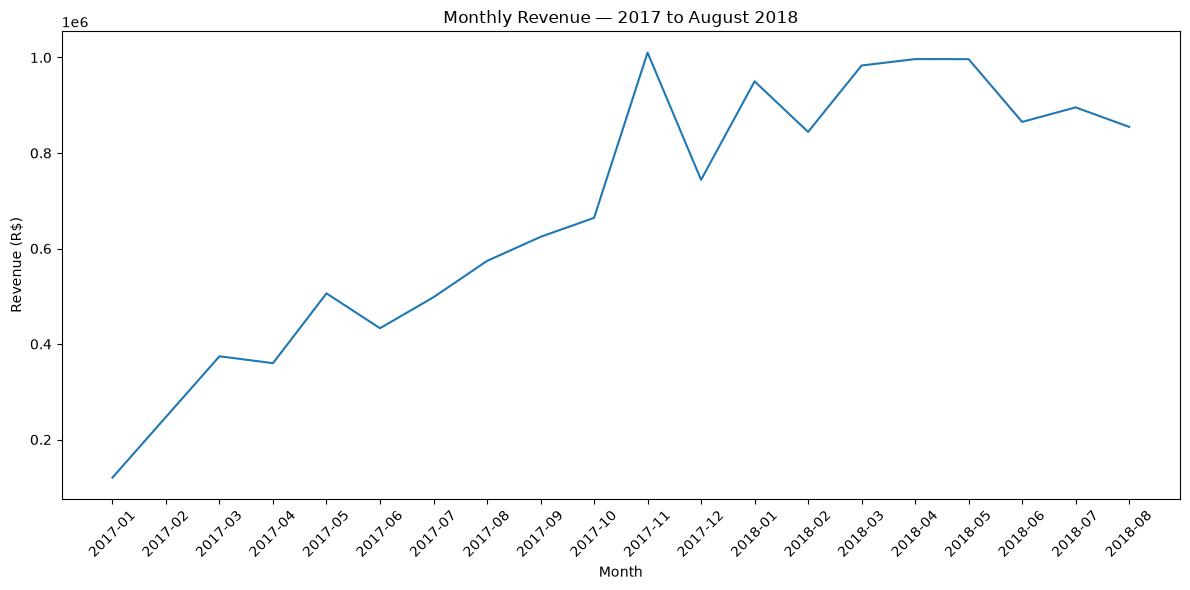

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales_full.index,
    monthly_sales_full["revenue"]
)

plt.title("Monthly Revenue — 2017 to August 2018")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [ ]:
import os

os.makedirs("../reports/figures", exist_ok=True)

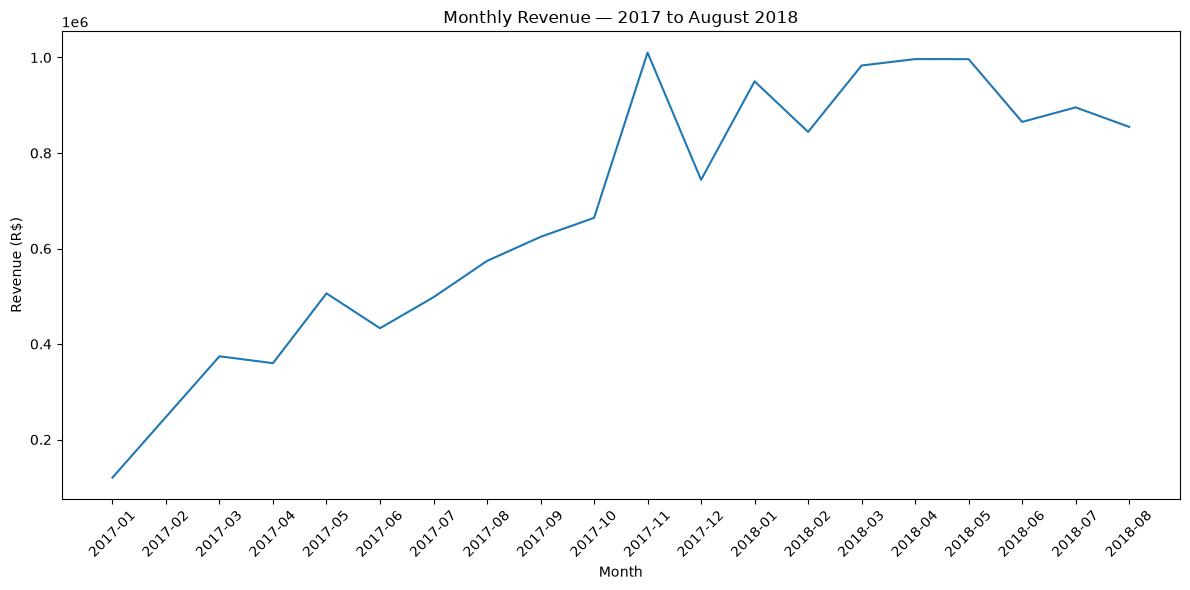

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales_full.index,
    monthly_sales_full["revenue"]
)

plt.title("Monthly Revenue — 2017 to August 2018")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../reports/figures/monthly_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
customers = pd.read_csv(
    "../data/raw/olist_customers_dataset.csv"
)

customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [ ]:
orders_customers = orders.merge(
    customers[
        [
            "customer_id",
            "customer_unique_id",
            "customer_state"
        ]
    ],
    on="customer_id",
    how="left"
)

orders_customers.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days,delivery_time_days,customer_unique_id,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,-7.107488,8.436574,7c396fd4830fd04220f754e42b4e5bff,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,-5.355729,13.782037,af07308b275d755c9edb36a90c618231,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,-17.245498,9.394213,3a653a41f6f9fc3d2a113cf8398680e8,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,-12.980069,13.208750,7c142cf63193a1473d2e66489a9ae977,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,-9.238171,2.873877,72632f0f9dd73dfee390c9b22eb56dd6,SP


In [ ]:
delivered_orders = orders_customers[
    orders_customers["order_status"] == "delivered"
].copy()

print("Delivered orders:", delivered_orders["order_id"].nunique())
print("Unique customers:", delivered_orders["customer_unique_id"].nunique())

Delivered orders: 96478
Unique customers: 93358


In [ ]:
customer_orders = (
    delivered_orders
    .groupby("customer_unique_id")
    .agg(
        orders=("order_id", "nunique"),
        first_order=("order_purchase_timestamp", "min"),
        last_order=("order_purchase_timestamp", "max")
    )
)

customer_orders.head()

,orders,first_order,last_order
customer_unique_id,,,
0000366f3b9a7992bf8c76cfdf3221e2,1,2018-05-10 10:56:27,2018-05-10 10:56:27
0000b849f77a49e4a4ce2b2a4ca5be3f,1,2018-05-07 11:11:27,2018-05-07 11:11:27
0000f46a3911fa3c0805444483337064,1,2017-03-10 21:05:03,2017-03-10 21:05:03
0000f6ccb0745a6a4b88665a16c9f078,1,2017-10-12 20:29:41,2017-10-12 20:29:41
0004aac84e0df4da2b147fca70cf8255,1,2017-11-14 19:45:42,2017-11-14 19:45:42


In [ ]:
total_customers = customer_orders.shape[0]

repeat_customers = (
    customer_orders["orders"] > 1
).sum()

repeat_rate = (
    repeat_customers / total_customers * 100
)

print("Total unique customers:", total_customers)
print("Repeat customers:", repeat_customers)
print("Repeat customer rate:", round(repeat_rate, 2), "%")

Total unique customers: 93358
Repeat customers: 2801
Repeat customer rate: 3.0 %


In [ ]:
customer_orders["orders"].value_counts().sort_index()

orders
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64

In [ ]:
order_revenue = (
    orders_items
    .groupby("order_id")
    .agg(
        revenue=("price", "sum"),
        freight=("freight_value", "sum"),
        items=("order_item_id", "count")
    )
    .reset_index()
)

order_revenue.head()

,order_id,revenue,freight,items
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,1
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,1
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,1
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,1


In [ ]:
customer_order_revenue = orders_customers.merge(
    order_revenue,
    on="order_id",
    how="left"
)

customer_order_revenue.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days,delivery_time_days,customer_unique_id,customer_state,revenue,freight,items
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,-7.107488,8.436574,7c396fd4830fd04220f754e42b4e5bff,SP,29.99,8.72,1.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,-5.355729,13.782037,af07308b275d755c9edb36a90c618231,BA,118.70,22.76,1.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,-17.245498,9.394213,3a653a41f6f9fc3d2a113cf8398680e8,GO,159.90,19.22,1.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,-12.980069,13.208750,7c142cf63193a1473d2e66489a9ae977,RN,45.00,27.20,1.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,-9.238171,2.873877,72632f0f9dd73dfee390c9b22eb56dd6,SP,19.90,8.72,1.0


In [ ]:
customer_analysis = (
    customer_order_revenue[
        customer_order_revenue["order_status"] == "delivered"
    ]
    .groupby("customer_unique_id")
    .agg(
        orders=("order_id", "nunique"),
        revenue=("revenue", "sum"),
        freight=("freight", "sum"),
        items_bought=("items", "sum")
    )
)

customer_analysis["revenue_per_order"] = (
    customer_analysis["revenue"] /
    customer_analysis["orders"]
)

customer_analysis.head()

,orders,revenue,freight,items_bought,revenue_per_order
customer_unique_id,,,,,
0000366f3b9a7992bf8c76cfdf3221e2,1,129.90,12.00,1.0,129.90
0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.90,8.29,1.0,18.90
0000f46a3911fa3c0805444483337064,1,69.00,17.22,1.0,69.00
0000f6ccb0745a6a4b88665a16c9f078,1,25.99,17.63,1.0,25.99
0004aac84e0df4da2b147fca70cf8255,1,180.00,16.89,1.0,180.00


In [ ]:
total_revenue = customer_analysis["revenue"].sum()

average_revenue_per_customer = (
    customer_analysis["revenue"].mean()
)

average_orders_per_customer = (
    customer_analysis["orders"].mean()
)

average_items_per_customer = (
    customer_analysis["items_bought"].mean()
)

print("Total revenue: R$", round(total_revenue, 2))
print(
    "Average revenue per customer: R$",
    round(average_revenue_per_customer, 2)
)
print(
    "Average orders per customer:",
    round(average_orders_per_customer, 2)
)
print(
    "Average items per customer:",
    round(average_items_per_customer, 2)
)

Total revenue: R$ 13221498.11
Average revenue per customer: R$ 141.62
Average orders per customer: 1.03
Average items per customer: 1.18


In [ ]:
customer_segments = (
    customer_analysis
    .assign(
        customer_type=lambda x: x["orders"].apply(
            lambda n: "Repeat" if n > 1 else "One-time"
        )
    )
    .groupby("customer_type")
    .agg(
        customers=("orders", "size"),
        total_revenue=("revenue", "sum"),
        average_revenue=("revenue", "mean"),
        average_orders=("orders", "mean")
    )
)

customer_segments

,customers,total_revenue,average_revenue,average_orders
customer_type,,,,
One-time,90557,12493089.36,137.958295,1.000000
Repeat,2801,728408.75,260.053106,2.113888


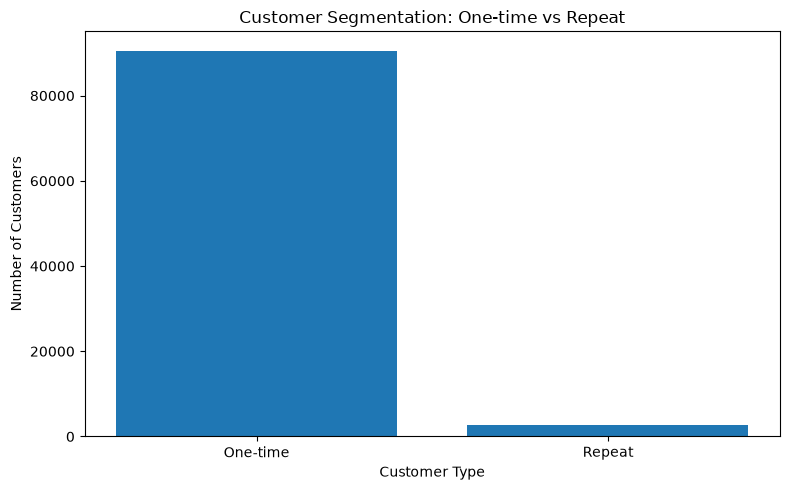

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    customer_segments.index,
    customer_segments["customers"]
)

plt.title("Customer Segmentation: One-time vs Repeat")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

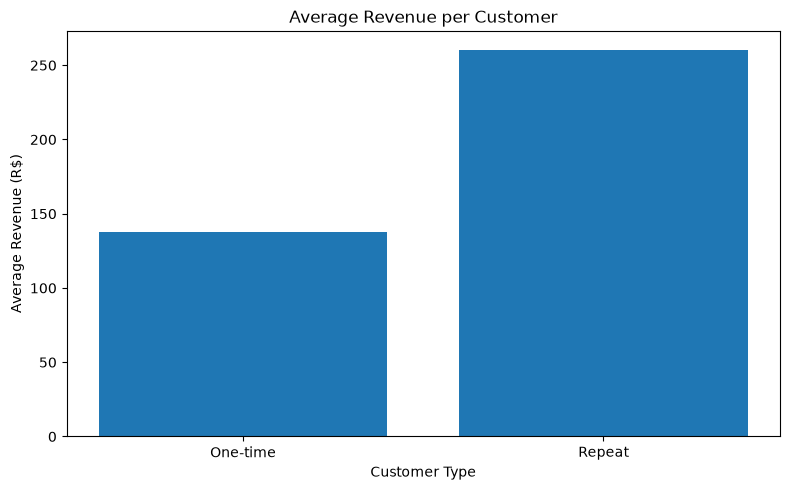

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    customer_segments.index,
    customer_segments["average_revenue"]
)

plt.title("Average Revenue per Customer")
plt.xlabel("Customer Type")
plt.ylabel("Average Revenue (R$)")

plt.tight_layout()
plt.show()

In [ ]:
one_time_avg = customer_segments.loc[
    "One-time", "average_revenue"
]

repeat_avg = customer_segments.loc[
    "Repeat", "average_revenue"
]

difference_pct = (
    (repeat_avg - one_time_avg)
    / one_time_avg
    * 100
)

print(
    "Repeat customers generate",
    round(difference_pct, 2),
    "% more average revenue per customer."
)

Repeat customers generate 88.5 % more average revenue per customer.


In [ ]:
import os

os.makedirs("../reports/figures", exist_ok=True)

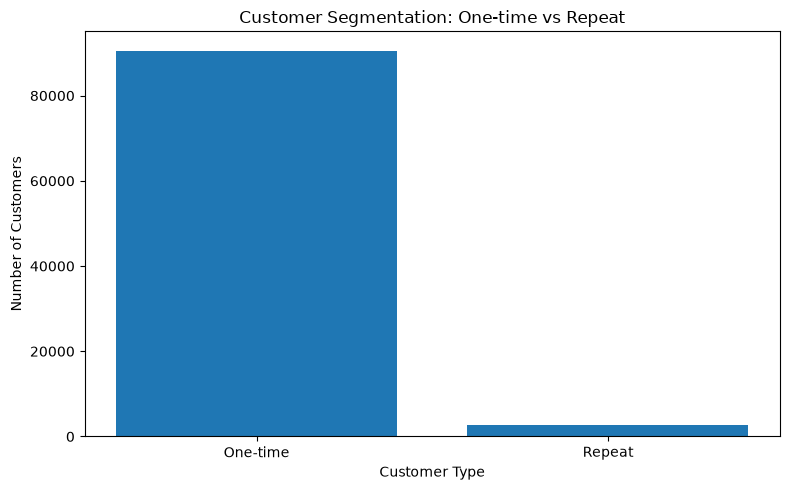

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    customer_segments.index,
    customer_segments["customers"]
)

plt.title("Customer Segmentation: One-time vs Repeat")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    "../reports/figures/customer_segments.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

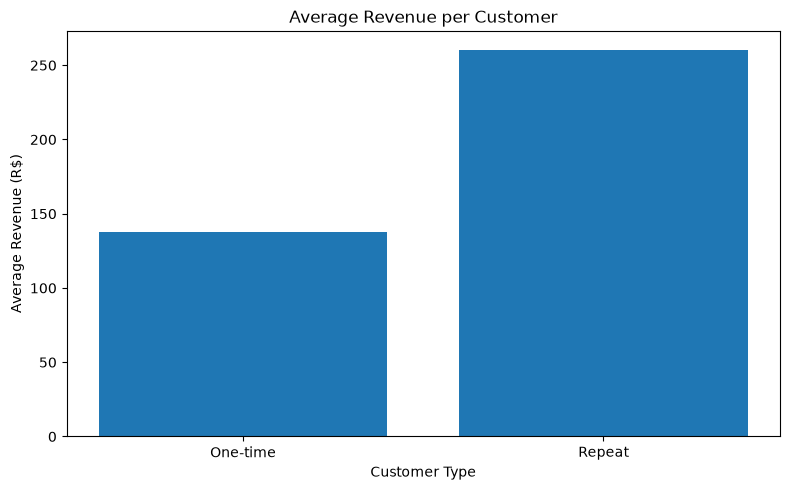

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    customer_segments.index,
    customer_segments["average_revenue"]
)

plt.title("Average Revenue per Customer")
plt.xlabel("Customer Type")
plt.ylabel("Average Revenue (R$)")

plt.tight_layout()

plt.savefig(
    "../reports/figures/customer_revenue_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
reviews = pd.read_csv(
    "../data/raw/olist_order_reviews_dataset.csv"
)

print("Shape:", reviews.shape)
print("\nColumns:")
print(reviews.columns.tolist())

print("\nReview score distribution:")
print(reviews["review_score"].value_counts().sort_index())

print(
    "\nOrders with multiple reviews:",
    (reviews.groupby("order_id").size() > 1).sum()
)

Shape: (99224, 7)

Columns:
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

Review score distribution:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

Orders with multiple reviews: 547


In [ ]:
order_reviews = (
    reviews
    .groupby("order_id")
    .agg(
        review_score=("review_score", "mean"),
        review_count=("review_id", "nunique")
    )
    .reset_index()
)

print("Order-level reviews:", order_reviews.shape)
print("\nReview score summary:")
print(order_reviews["review_score"].describe())

Order-level reviews: (98673, 3)

Review score summary:
count    98673.000000
mean         4.086793
std          1.346274
min          1.000000
25%          4.000000
50%          5.000000
75%          5.000000
max          5.000000
Name: review_score, dtype: float64


In [ ]:
delivery_reviews = delivered_orders.merge(
    order_reviews,
    on="order_id",
    how="left"
)

print("Shape:", delivery_reviews.shape)

print("\nMissing review scores:")
print(delivery_reviews["review_score"].isna().sum())

Shape: (96478, 14)

Missing review scores:
646


In [ ]:
delivery_reviews = delivered_orders.merge(
    order_reviews,
    on="order_id",
    how="left"
)

print("Shape:", delivery_reviews.shape)

print("\nMissing review scores:")
print(delivery_reviews["review_score"].isna().sum())

Shape: (96478, 14)

Missing review scores:
646


In [ ]:
review_by_delivery = (
    delivery_reviews
    .dropna(subset=["review_score"])
    .groupby("delivery_status")
    ["review_score"]
    .agg(["count", "mean", "median"])
)

print(review_by_delivery)

KeyError: 'delivery_status'

In [ ]:
# Make sure the date columns are datetime
delivery_reviews["delivery_date"] = pd.to_datetime(
    delivery_reviews["order_delivered_customer_date"]
).dt.normalize()

delivery_reviews["estimated_date"] = pd.to_datetime(
    delivery_reviews["order_estimated_delivery_date"]
).dt.normalize()

# Calculate delivery delay
delivery_reviews["delay_days"] = (
    delivery_reviews["delivery_date"]
    - delivery_reviews["estimated_date"]
).dt.days

# Create delivery status
delivery_reviews["delivery_status"] = np.where(
    delivery_reviews["delay_days"] > 0,
    "Late",
    "On time / Early"
)

print(delivery_reviews[
    ["order_id", "delay_days", "delivery_status", "review_score"]
].head())

print("\nDelivery status:")
print(delivery_reviews["delivery_status"].value_counts())

                           order_id  delay_days  delivery_status  review_score
0  e481f51cbdc54678b7cc49136f2d6af7        -8.0  On time / Early           4.0
1  53cdb2fc8bc7dce0b6741e2150273451        -6.0  On time / Early           4.0
2  47770eb9100c2d0c44946d9cf07ec65d       -18.0  On time / Early           5.0
3  949d5b44dbf5de918fe9c16f97b45f8a       -13.0  On time / Early           5.0
4  ad21c59c0840e6cb83a9ceb5573f8159       -10.0  On time / Early           5.0

Delivery status:
delivery_status
On time / Early    89944
Late                6534
Name: count, dtype: int64


In [ ]:
review_by_delivery = (
    delivery_reviews
    .dropna(subset=["review_score"])
    .groupby("delivery_status")["review_score"]
    .agg(["count", "mean", "median"])
)

print(review_by_delivery)

                 count      mean  median
delivery_status                         
Late              6381  2.271823     1.0
On time / Early  89451  4.290608     5.0


In [ ]:
print(delivery_reviews.columns.tolist())

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'delivery_delay_days', 'delivery_time_days', 'customer_unique_id', 'customer_state', 'review_score', 'review_count', 'delivery_date', 'estimated_date', 'delay_days', 'delivery_status']


In [ ]:
late_avg = review_by_delivery.loc["Late", "mean"]
on_time_avg = review_by_delivery.loc["On time / Early", "mean"]

difference = on_time_avg - late_avg
difference_pct = (difference / on_time_avg) * 100

print("Average review — Late:", round(late_avg, 2))
print("Average review — On time / Early:", round(on_time_avg, 2))
print("Difference:", round(difference, 2), "stars")
print("Relative difference:", round(difference_pct, 1), "%")

Average review — Late: 2.27
Average review — On time / Early: 4.29
Difference: 2.02 stars
Relative difference: 47.1 %


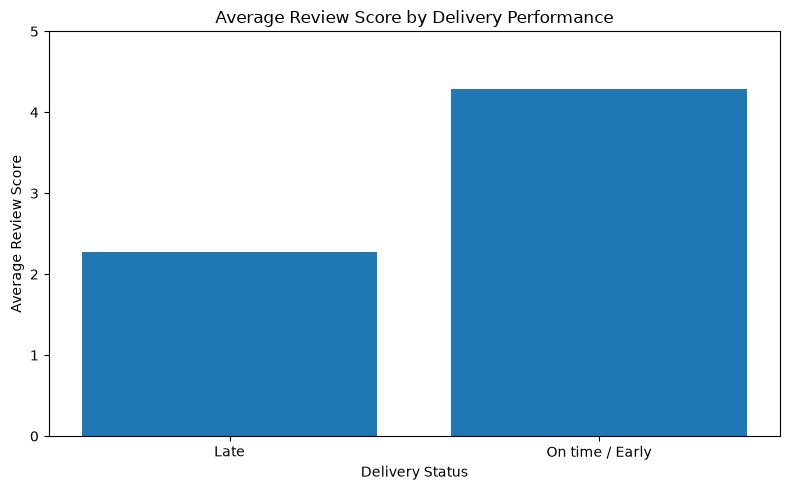

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    review_by_delivery.index,
    review_by_delivery["mean"]
)

plt.title("Average Review Score by Delivery Performance")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score")
plt.ylim(0, 5)

plt.tight_layout()
plt.show()

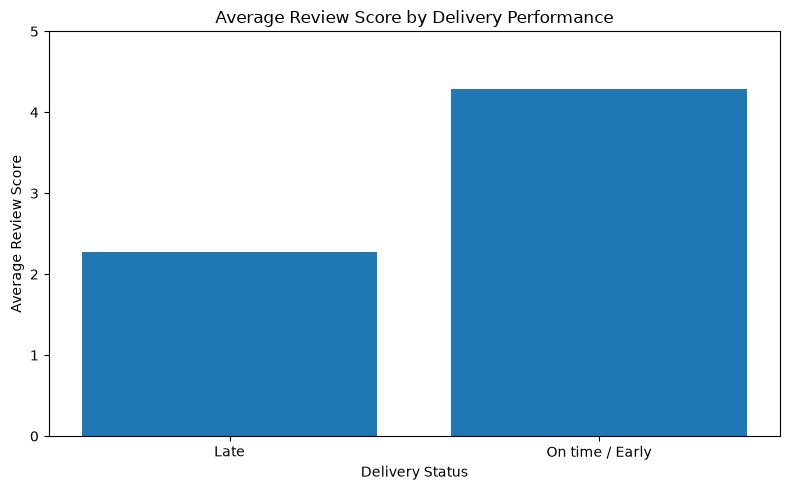

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    review_by_delivery.index,
    review_by_delivery["mean"]
)

plt.title("Average Review Score by Delivery Performance")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score")
plt.ylim(0, 5)

plt.tight_layout()

plt.savefig(
    "../reports/figures/review_score_by_delivery.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
delivery_reviews["low_review"] = (
    delivery_reviews["review_score"] <= 2
)

low_review_rate = (
    delivery_reviews
    .dropna(subset=["review_score"])
    .groupby("delivery_status")["low_review"]
    .mean()
    * 100
)

print("Low review rate (%):")
print(low_review_rate.round(2))

Low review rate (%):
delivery_status
Late               62.36
On time / Early     9.23
Name: low_review, dtype: float64


In [ ]:
payments = pd.read_csv(
    "../data/raw/olist_order_payments_dataset.csv"
)

print("Shape:", payments.shape)
print("\nColumns:")
print(payments.columns.tolist())

print("\nFirst 5 rows:")
print(payments.head())

print("\nPayment type distribution:")
print(payments["payment_type"].value_counts())

print("\nMissing values:")
print(payments.isnull().sum())

Shape: (103886, 5)

Columns:
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

First 5 rows:
                           order_id  payment_sequential payment_type  \
0  b81ef226f3fe1789b1e8b2acac839d17                   1  credit_card   
1  a9810da82917af2d9aefd1278f1dcfa0                   1  credit_card   
2  25e8ea4e93396b6fa0d3dd708e76c1bd                   1  credit_card   
3  ba78997921bbcdc1373bb41e913ab953                   1  credit_card   
4  42fdf880ba16b47b59251dd489d4441a                   1  credit_card   

   payment_installments  payment_value  
0                     8          99.33  
1                     1          24.39  
2                     1          65.71  
3                     8         107.78  
4                     2         128.45  

Payment type distribution:
payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

Missing valu

In [ ]:
order_payments = payments[
    [
        "order_id",
        "payment_type",
        "payment_value",
        "payment_installments",
        "payment_sequential"
    ]
].copy()

order_payments["payment_count"] = 1

print("Payment transactions shape:", order_payments.shape)

print("\nFirst 5 rows:")
print(order_payments.head())

print("\nPayment type summary:")
print(
    order_payments.groupby("payment_type")["payment_value"]
    .agg(["count", "sum", "mean"])
    .sort_values("sum", ascending=False)
)

NameError: name 'payments' is not defined

In [ ]:
payment_type_summary = (
    payments
    .groupby("payment_type")
    .agg(
        transactions=("order_id", "count"),
        orders=("order_id", "nunique"),
        total_value=("payment_value", "sum"),
        average_payment=("payment_value", "mean")
    )
    .sort_values("total_value", ascending=False)
)

print(payment_type_summary)

              transactions  orders  total_value  average_payment
payment_type                                                    
credit_card          76795   76505  12542084.19       163.319021
boleto               19784   19784   2869361.27       145.034435
voucher               5775    3866    379436.87        65.703354
debit_card            1529    1528    217989.79       142.570170
not_defined              3       3         0.00         0.000000


In [ ]:
payment_type_summary["value_share_%"] = (
    payment_type_summary["total_value"]
    / payment_type_summary["total_value"].sum()
    * 100
)

print(payment_type_summary.round(2))

              transactions  orders  total_value  average_payment  \
payment_type                                                       
credit_card          76795   76505  12542084.19           163.32   
boleto               19784   19784   2869361.27           145.03   
voucher               5775    3866    379436.87            65.70   
debit_card            1529    1528    217989.79           142.57   
not_defined              3       3         0.00             0.00   

              value_share_%  
payment_type                 
credit_card           78.34  
boleto                17.92  
voucher                2.37  
debit_card             1.36  
not_defined            0.00  


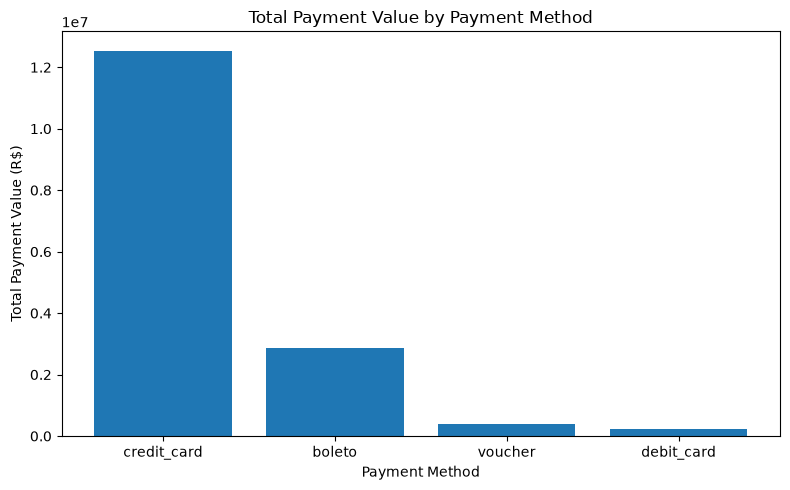

In [ ]:
plt.figure(figsize=(8, 5))

payment_chart = payment_type_summary[
    payment_type_summary["total_value"] > 0
]

plt.bar(
    payment_chart.index,
    payment_chart["total_value"]
)

plt.title("Total Payment Value by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Payment Value (R$)")

plt.tight_layout()
plt.show()

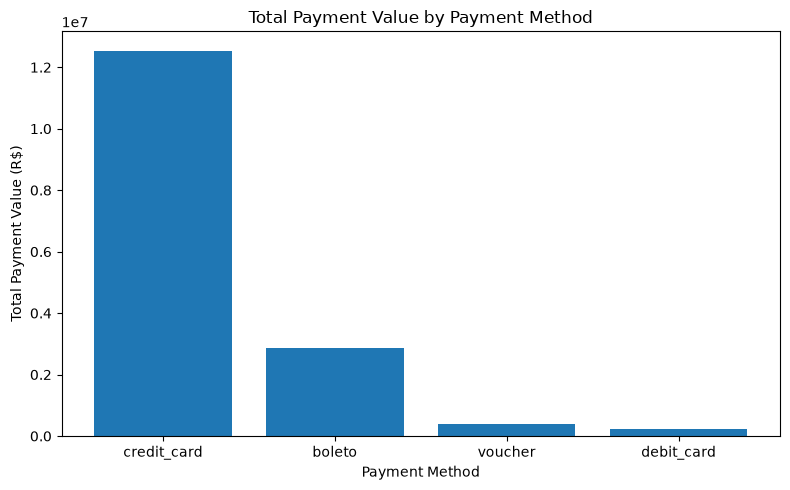

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    payment_chart.index,
    payment_chart["total_value"]
)

plt.title("Total Payment Value by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Payment Value (R$)")

plt.tight_layout()

plt.savefig(
    "../reports/figures/payment_value_by_method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
installment_summary = (
    payments
    .groupby("payment_installments")
    .agg(
        transactions=("order_id", "count"),
        orders=("order_id", "nunique"),
        total_value=("payment_value", "sum"),
        average_payment=("payment_value", "mean")
    )
    .sort_index()
)

print(installment_summary)

                      transactions  orders  total_value  average_payment
payment_installments                                                    
0                                2       2       188.63        94.315000
1                            52546   49060   5907233.36       112.420229
2                            12413   12389   1579283.03       127.228150
3                            10461   10443   1491103.80       142.539317
4                             7098    7088   1163907.61       163.976840
5                             5239    5234    961174.30       183.465222
6                             3920    3916    822611.81       209.849952
7                             1626    1623    305157.39       187.673672
8                             4268    4253   1313423.34       307.737427
9                              644     644    131015.92       203.440870
10                            5328    5315   2211577.34       415.085837
11                              23      23      287

In [ ]:
print(
    installment_summary
    .sort_values("orders", ascending=False)
    .head(10)
    .round(2)
)

                      transactions  orders  total_value  average_payment
payment_installments                                                    
1                            52546   49060   5907233.36           112.42
2                            12413   12389   1579283.03           127.23
3                            10461   10443   1491103.80           142.54
4                             7098    7088   1163907.61           163.98
10                            5328    5315   2211577.34           415.09
5                             5239    5234    961174.30           183.47
8                             4268    4253   1313423.34           307.74
6                             3920    3916    822611.81           209.85
7                             1626    1623    305157.39           187.67
9                              644     644    131015.92           203.44


In [ ]:
freight_analysis = orders_items.agg(
    product_revenue=("price", "sum"),
    freight_revenue=("freight_value", "sum")
)

print(freight_analysis)

freight_ratio = (
    freight_analysis["freight_revenue"]
    / freight_analysis["product_revenue"]
    * 100
)

print(
    "\nFreight as % of product revenue:",
    round(freight_ratio, 2),
    "%"
)

                      price  freight_value
product_revenue  13591643.7            NaN
freight_revenue         NaN     2251909.54


KeyError: 'freight_revenue'

In [ ]:
product_revenue = orders_items["price"].sum()
freight_revenue = orders_items["freight_value"].sum()

freight_ratio = (
    freight_revenue / product_revenue
) * 100

print("Product revenue: R$", round(product_revenue, 2))
print("Freight revenue: R$", round(freight_revenue, 2))
print(
    "Freight as % of product revenue:",
    round(freight_ratio, 2),
    "%"
)

Product revenue: R$ 13591643.7
Freight revenue: R$ 2251909.54
Freight as % of product revenue: 16.57 %


In [ ]:
freight_per_order = (
    orders_items
    .groupby("order_id")
    .agg(
        product_revenue=("price", "sum"),
        freight_cost=("freight_value", "sum")
    )
)

print(freight_per_order.describe())

       product_revenue  freight_cost
count     98666.000000  98666.000000
mean        137.754076     22.823562
std         210.645145     21.650909
min           0.850000      0.000000
25%          45.900000     13.850000
50%          86.900000     17.170000
75%         149.900000     24.040000
max       13440.000000   1794.960000


In [ ]:
freight_per_order["freight_ratio_%"] = (
    freight_per_order["freight_cost"]
    / freight_per_order["product_revenue"]
    * 100
)

print(
    freight_per_order["freight_ratio_%"]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .describe()
)

count    98666.000000
mean        30.838869
std         31.476219
min          0.000000
25%         13.186441
50%         22.437396
75%         38.019087
max       2144.705882
Name: freight_ratio_%, dtype: float64


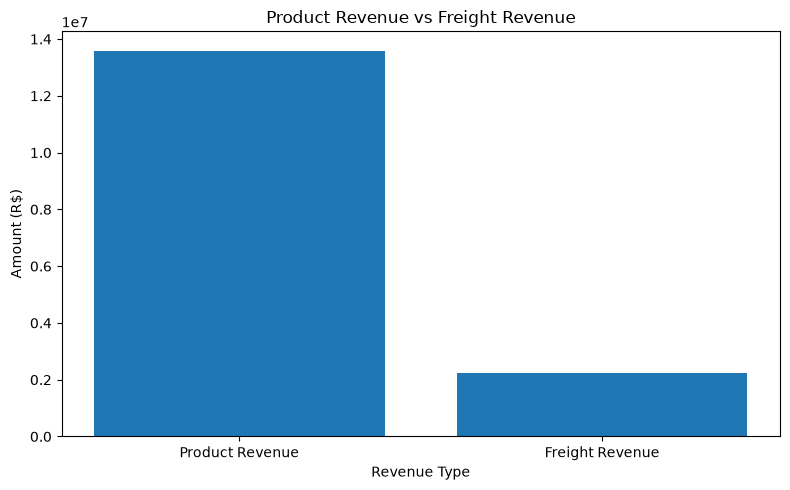

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    ["Product Revenue", "Freight Revenue"],
    [product_revenue, freight_revenue]
)

plt.title("Product Revenue vs Freight Revenue")
plt.xlabel("Revenue Type")
plt.ylabel("Amount (R$)")

plt.tight_layout()
plt.show()

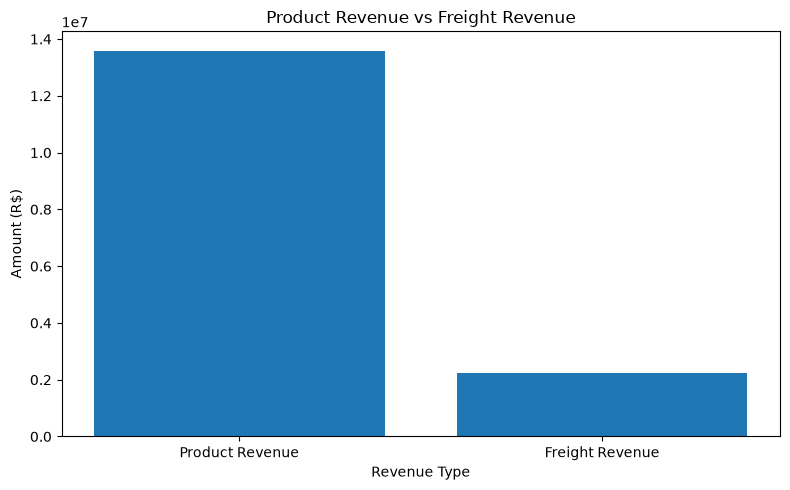

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    ["Product Revenue", "Freight Revenue"],
    [product_revenue, freight_revenue]
)

plt.title("Product Revenue vs Freight Revenue")
plt.xlabel("Revenue Type")
plt.ylabel("Amount (R$)")

plt.tight_layout()

plt.savefig(
    "../reports/figures/product_vs_freight_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
installment_chart = (
    installment_summary
    .sort_values("orders", ascending=False)
    .head(10)
)

print(installment_chart.round(2))

                      transactions  orders  total_value  average_payment
payment_installments                                                    
1                            52546   49060   5907233.36           112.42
2                            12413   12389   1579283.03           127.23
3                            10461   10443   1491103.80           142.54
4                             7098    7088   1163907.61           163.98
10                            5328    5315   2211577.34           415.09
5                             5239    5234    961174.30           183.47
8                             4268    4253   1313423.34           307.74
6                             3920    3916    822611.81           209.85
7                             1626    1623    305157.39           187.67
9                              644     644    131015.92           203.44


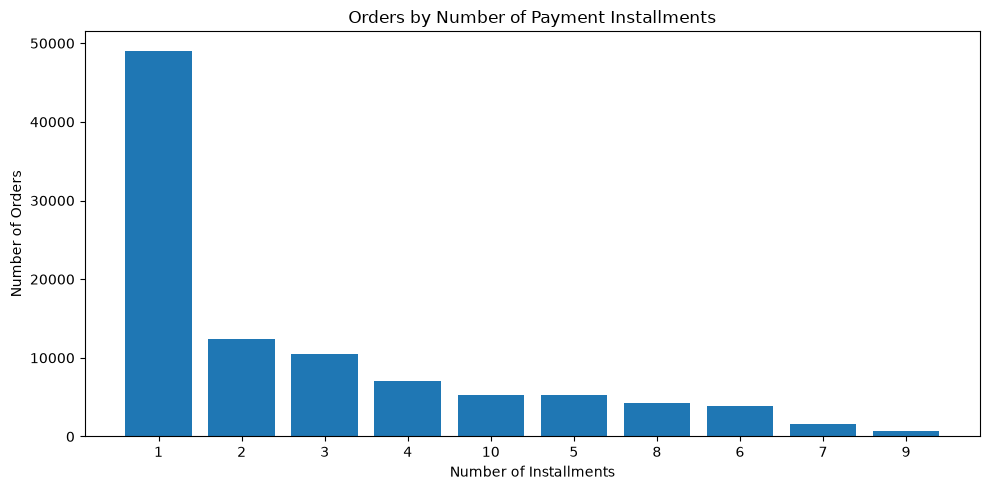

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    installment_chart.index.astype(str),
    installment_chart["orders"]
)

plt.title("Orders by Number of Payment Installments")
plt.xlabel("Number of Installments")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

In [ ]:
fact_orders = orders.copy()

print("Shape:", fact_orders.shape)
print("\nColumns:")
print(fact_orders.columns.tolist())

print("\nDuplicate order IDs:")
print(fact_orders["order_id"].duplicated().sum())

Shape: (99441, 10)

Columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'delivery_delay_days', 'delivery_time_days']

Duplicate order IDs:
0


In [ ]:
fact_orders["order_purchase_timestamp"] = pd.to_datetime(
    fact_orders["order_purchase_timestamp"]
)

fact_orders["order_delivered_customer_date"] = pd.to_datetime(
    fact_orders["order_delivered_customer_date"]
)

fact_orders["order_estimated_delivery_date"] = pd.to_datetime(
    fact_orders["order_estimated_delivery_date"]
)

fact_orders["delivery_time_days"] = (
    fact_orders["order_delivered_customer_date"]
    - fact_orders["order_purchase_timestamp"]
).dt.total_seconds() / (60 * 60 * 24)

fact_orders["delay_days"] = (
    fact_orders["order_delivered_customer_date"].dt.normalize()
    - fact_orders["order_estimated_delivery_date"].dt.normalize()
).dt.days

fact_orders["is_late"] = (
    fact_orders["delay_days"] > 0
)

In [ ]:
print(
    fact_orders[
        [
            "order_id",
            "order_status",
            "delivery_time_days",
            "delay_days",
            "is_late"
        ]
    ].head()
)

                           order_id order_status  delivery_time_days  \
0  e481f51cbdc54678b7cc49136f2d6af7    delivered            8.436574   
1  53cdb2fc8bc7dce0b6741e2150273451    delivered           13.782037   
2  47770eb9100c2d0c44946d9cf07ec65d    delivered            9.394213   
3  949d5b44dbf5de918fe9c16f97b45f8a    delivered           13.208750   
4  ad21c59c0840e6cb83a9ceb5573f8159    delivered            2.873877   

   delay_days  is_late  
0        -8.0    False  
1        -6.0    False  
2       -18.0    False  
3       -13.0    False  
4       -10.0    False  


In [ ]:
fact_order_items = orders_items.copy()

print("Shape:", fact_order_items.shape)

print("\nColumns:")
print(fact_order_items.columns.tolist())

Shape: (112650, 11)

Columns:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value', 'product_category_name', 'customer_id', 'order_purchase_timestamp', 'month']


In [ ]:
print("\nDuplicate order-item combinations:")

print(
    fact_order_items
    .duplicated(subset=["order_id", "order_item_id"])
    .sum()
)


Duplicate order-item combinations:
0


In [ ]:
dim_customers = customers.copy()

print("Shape:", dim_customers.shape)

print("\nDuplicate customer IDs:")
print(dim_customers["customer_id"].duplicated().sum())

print("\nUnique customers:")
print(dim_customers["customer_unique_id"].nunique())

Shape: (99441, 5)

Duplicate customer IDs:
0

Unique customers:
96096


In [ ]:
products = pd.read_csv(
    "../data/raw/olist_products_dataset.csv"
)

print("Shape:", products.shape)

print("\nColumns:")
print(products.columns.tolist())

Shape: (32951, 9)

Columns:
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']


In [ ]:
dim_products = products.copy()

print("\nDuplicate product IDs:")
print(dim_products["product_id"].duplicated().sum())


Duplicate product IDs:
0


In [ ]:
sellers = pd.read_csv(
    "../data/raw/olist_sellers_dataset.csv"
)

dim_sellers = sellers.copy()

print("Shape:", dim_sellers.shape)

print("\nDuplicate seller IDs:")
print(dim_sellers["seller_id"].duplicated().sum())

Shape: (3095, 4)

Duplicate seller IDs:
0


In [ ]:
import os

os.makedirs("../data/processed", exist_ok=True)

print("Processed data folder created.")

Processed data folder created.


In [ ]:
dim_customers = (
    customers[
        [
            "customer_id",
            "customer_unique_id",
            "customer_zip_code_prefix",
            "customer_city",
            "customer_state"
        ]
    ]
    .drop_duplicates()
)

print("Rows:", len(dim_customers))
print("Unique customer IDs:", dim_customers["customer_id"].nunique())
print("Unique customer_unique IDs:", dim_customers["customer_unique_id"].nunique())

Rows: 99441
Unique customer IDs: 99441
Unique customer_unique IDs: 96096


In [ ]:
fact_orders.to_csv(
    "../data/processed/fact_orders.csv",
    index=False
)

fact_order_items.to_csv(
    "../data/processed/fact_order_items.csv",
    index=False
)

dim_customers.to_csv(
    "../data/processed/dim_customers.csv",
    index=False
)

dim_products.to_csv(
    "../data/processed/dim_products.csv",
    index=False
)

dim_sellers.to_csv(
    "../data/processed/dim_sellers.csv",
    index=False
)

print("All Power BI tables exported successfully!")

All Power BI tables exported successfully!


In [ ]:
order_payments.to_csv(
    "../data/processed/fact_payments.csv",
    index=False
)

order_reviews.to_csv(
    "../data/processed/fact_reviews.csv",
    index=False
)

print("Payments and reviews exported successfully!")

Payments and reviews exported successfully!


In [ ]:
import os

print(os.listdir("../data/processed"))

['dim_customers.csv', 'dim_products.csv', 'dim_sellers.csv', 'fact_orders.csv', 'fact_order_items.csv', 'fact_payments.csv', 'fact_reviews.csv']
